In [3]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/splits_Excel/test.xlsx
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/splits_Excel/validate.xlsx
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/splits_Excel/train.xlsx
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Testing_140.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Training_1639.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Validation_364.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Testing_265.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Validation_511.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Training_1522.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Training_43.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Validate/DR/Testing_356.png
/kaggle/input/datasets/krishba/retfound-rfmid-10-disea

In [4]:
!git clone https://github.com/rmaphoh/RETFound_MAE.git

Cloning into 'RETFound_MAE'...
remote: Enumerating objects: 221, done.
remote: Counting objects: 100% (43/43), done.
remote: Compressing objects: 100% (20/20), done.
remote: Total 221 (delta 26), reused 23 (delta 23), pack-reused 178 (from 1)
Receiving objects: 100% (221/221), 444.40 KiB | 2.92 MiB/s, done.
Resolving deltas: 100% (121/121), done.


In [5]:
%cd /kaggle/working/RETFound_MAE

!find . -maxdepth 2 -type f | sort

/kaggle/working/RETFound_MAE
./BENCHMARK.md
./engine_finetune.py
./examples/RETFound_MESSIDOR2_demo.ipynb
./.git/config
./.git/description
./.git/HEAD
./.gitignore
./.git/index
./.git/packed-refs
./latent_feature.ipynb
./LICENSE
./main_finetune.py
./models_vit.py
./README.md
./requirements.txt
./train.sh
./util/datasets.py
./util/__init__.py
./util/lr_decay.py
./util/lr_sched.py
./util/misc.py
./util/pos_embed.py


In [6]:
print("========== README ==========\n")
!cat README.md

print("\n\n========== TRAIN.SH ==========\n")
!cat train.sh

========== README ==========

## RETFound - A foundation model for retinal images


Official repo including a series of foundation models and applications for retinal images.<br>
`[RETFound-MAE]`:[RETFound: a foundation model for generalizable disease detection from retinal images](https://www.nature.com/articles/s41586-023-06555-x).<br>
`[RETFound-DINOv2]`:[Revealing the Impact of Pre-training Data on Medical Foundation Models](https://www.researchsquare.com/article/rs-6080254/v1).<br>
`[DINOv2]`:[General-purpose vision foundation models DINOv2 by Meta](https://github.com/facebookresearch/dinov2).<br>
`[DINOv3]`:[General-purpose vision foundation models DINOv3 by Meta](https://github.com/facebookresearch/dinov3).<br>


Please contact 	**ykzhoua@gmail.com** or **yukun.zhou.19@ucl.ac.uk** if you have questions.


### 📝Key features

- RETFound is pre-trained on 1.6 million retinal images with self-supervised learning
- RETFound has been validated in multiple disease detection tasks
- RET

In [7]:
import torch
import torchvision
from PIL import Image

print("PyTorch     :", torch.__version__)
print("Torchvision :", torchvision.__version__)
print("Pillow      :", Image.__version__)
print("CUDA        :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU         :", torch.cuda.get_device_name(0))

import sys
sys.path.append("/kaggle/working/RETFound_MAE")

import models_vit

print("RETFound model import: SUCCESS")

PyTorch     : 2.10.0+cu128
Torchvision : 0.25.0+cu128
Pillow      : 11.3.0
CUDA        : True
GPU         : Tesla T4
RETFound model import: SUCCESS


/usr/local/lib/python3.12/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


In [8]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())

for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

PyTorch: 2.10.0+cu128
CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


In [9]:
import os

RETFOUND_PATH = "/kaggle/working/RETFound_MAE"

print("RETFound folder exists:", os.path.exists(RETFOUND_PATH))

if os.path.exists(RETFOUND_PATH):
    print("\nFiles:")
    for f in os.listdir(RETFOUND_PATH):
        print(" -", f)

RETFound folder exists: True

Files:
 - util
 - latent_feature.ipynb
 - examples
 - train.sh
 - BENCHMARK.md
 - __pycache__
 - .git
 - .gitignore
 - LICENSE
 - main_finetune.py
 - models_vit.py
 - engine_finetune.py
 - requirements.txt
 - README.md


In [10]:
import requests

url = "https://huggingface.co/YukunZhou/RETFound_mae_natureCFP"

response = requests.get(url)

print("Status code:", response.status_code)

if response.status_code == 200:
    print("Hugging Face access: SUCCESS")
else:
    print("Hugging Face access: FAILED")

Status code: 200
Hugging Face access: SUCCESS


In [12]:
from kaggle_secrets import UserSecretsClient
from huggingface_hub import login

# Get the token securely from Kaggle Secrets
user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF_TOKEN")

# Login to Hugging Face
login(token=HF_TOKEN)

print("Hugging Face authentication: SUCCESS")

Hugging Face authentication: SUCCESS


In [13]:
from huggingface_hub import snapshot_download
import os

MODEL_DIR = "/kaggle/working/RETFound_mae_natureCFP"

snapshot_download(
    repo_id="YukunZhou/RETFound_mae_natureCFP",
    local_dir=MODEL_DIR,
    token=HF_TOKEN
)

print("\nRETFound CFP weights downloaded successfully!")
print("\nFiles:")

for root, dirs, files in os.walk(MODEL_DIR):
    for file in files:
        print(os.path.join(root, file))

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]


RETFound CFP weights downloaded successfully!

Files:
/kaggle/working/RETFound_mae_natureCFP/RETFound_mae_natureCFP.pth
/kaggle/working/RETFound_mae_natureCFP/.gitattributes
/kaggle/working/RETFound_mae_natureCFP/README.md
/kaggle/working/RETFound_mae_natureCFP/config.json
/kaggle/working/RETFound_mae_natureCFP/.cache/huggingface/.gitignore
/kaggle/working/RETFound_mae_natureCFP/.cache/huggingface/CACHEDIR.TAG
/kaggle/working/RETFound_mae_natureCFP/.cache/huggingface/download/.gitattributes.metadata
/kaggle/working/RETFound_mae_natureCFP/.cache/huggingface/download/config.json.metadata
/kaggle/working/RETFound_mae_natureCFP/.cache/huggingface/download/README.md.metadata
/kaggle/working/RETFound_mae_natureCFP/.cache/huggingface/download/RETFound_mae_natureCFP.pth.metadata


In [14]:
import torch
import os

CKPT_PATH = "/kaggle/working/RETFound_mae_natureCFP/RETFound_mae_natureCFP.pth"

print("Checkpoint exists:", os.path.exists(CKPT_PATH))
print("Checkpoint size:",
      round(os.path.getsize(CKPT_PATH) / (1024**3), 2), "GB")

checkpoint = torch.load(
    CKPT_PATH,
    map_location="cpu",
    weights_only=False
)

print("\nCheckpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("\nCheckpoint keys:")
    for key in checkpoint.keys():
        print(" -", key)

Checkpoint exists: True
Checkpoint size: 3.68 GB

Checkpoint type: <class 'dict'>

Checkpoint keys:
 - model
 - optimizer
 - epoch
 - scaler
 - args


In [15]:
model_state = checkpoint["model"]

print("Number of parameters:", len(model_state))

print("\nFirst 20 parameter names:")
for i, key in enumerate(model_state.keys()):
    print(f"{i:2d}  {key}")
    if i >= 19:
        break

Number of parameters: 398

First 20 parameter names:
 0  cls_token
 1  pos_embed
 2  mask_token
 3  decoder_pos_embed
 4  patch_embed.proj.weight
 5  patch_embed.proj.bias
 6  blocks.0.norm1.weight
 7  blocks.0.norm1.bias
 8  blocks.0.attn.qkv.weight
 9  blocks.0.attn.qkv.bias
10  blocks.0.attn.proj.weight
11  blocks.0.attn.proj.bias
12  blocks.0.norm2.weight
13  blocks.0.norm2.bias
14  blocks.0.mlp.fc1.weight
15  blocks.0.mlp.fc1.bias
16  blocks.0.mlp.fc2.weight
17  blocks.0.mlp.fc2.bias
18  blocks.1.norm1.weight
19  blocks.1.norm1.bias


In [16]:
import sys
import inspect

sys.path.insert(0, "/kaggle/working/RETFound_MAE")

import models_vit

print("RETFound model constructors:\n")

for name, obj in inspect.getmembers(models_vit):
    if inspect.isfunction(obj) and "retfound" in name.lower():
        print(name)
        print(inspect.signature(obj))
        print()

RETFound model constructors:

RETFound_dinov2
(args, **kwargs)

RETFound_mae
(**kwargs)



In [17]:
import inspect
import models_vit

print(inspect.getsource(models_vit.RETFound_mae))

def RETFound_mae(**kwargs):
    model = VisionTransformer(
        patch_size=16, embed_dim=1024, depth=24, num_heads=16, mlp_ratio=4, qkv_bias=True,
        norm_layer=partial(nn.LayerNorm, eps=1e-6), **kwargs)
    return model



In [18]:
# Check whether the pretrained checkpoint contains a classification head

head_keys = [
    key for key in model_state.keys()
    if "head" in key.lower()
]

print("Classification-head related parameters:")

if head_keys:
    for key in head_keys:
        print(key, "->", tuple(model_state[key].shape))
else:
    print("No classification head found.")

Classification-head related parameters:
No classification head found.


In [19]:
import sys
import torch

sys.path.insert(0, "/kaggle/working/RETFound_MAE")

import models_vit

# --------------------------------------------------
# 1. Create RETFound ViT-Large
# --------------------------------------------------
model = models_vit.RETFound_mae(
    num_classes=10,
    global_pool=True
)

print("RETFound model created.")

# --------------------------------------------------
# 2. Load pretrained RETFound weights
# --------------------------------------------------
msg = model.load_state_dict(model_state, strict=False)

print("\nCheckpoint loading completed.")
print("Missing keys:", len(msg.missing_keys))
print("Unexpected keys:", len(msg.unexpected_keys))

if msg.missing_keys:
    print("\nMissing keys:")
    for key in msg.missing_keys[:20]:
        print(" ", key)

if msg.unexpected_keys:
    print("\nUnexpected keys:")
    for key in msg.unexpected_keys[:20]:
        print(" ", key)

RETFound model created.

Checkpoint loading completed.
Missing keys: 4
Unexpected keys: 106

Missing keys:
  fc_norm.weight
  fc_norm.bias
  head.weight
  head.bias

Unexpected keys:
  mask_token
  decoder_pos_embed
  norm.weight
  norm.bias
  decoder_embed.weight
  decoder_embed.bias
  decoder_blocks.0.norm1.weight
  decoder_blocks.0.norm1.bias
  decoder_blocks.0.attn.qkv.weight
  decoder_blocks.0.attn.qkv.bias
  decoder_blocks.0.attn.proj.weight
  decoder_blocks.0.attn.proj.bias
  decoder_blocks.0.norm2.weight
  decoder_blocks.0.norm2.bias
  decoder_blocks.0.mlp.fc1.weight
  decoder_blocks.0.mlp.fc1.bias
  decoder_blocks.0.mlp.fc2.weight
  decoder_blocks.0.mlp.fc2.bias
  decoder_blocks.1.norm1.weight
  decoder_blocks.1.norm1.bias


In [21]:
import torch
import torchvision
import timm

print("PyTorch     :", torch.__version__)
print("Torchvision :", torchvision.__version__)
print("timm        :", timm.__version__)

PyTorch     : 2.10.0+cu128
Torchvision : 0.25.0+cu128
timm        : 1.0.26


In [22]:
import inspect
import models_vit

print("RETFound forward():")
print(inspect.getsource(models_vit.VisionTransformer.forward))

print("\nRETFound forward_features():")
print(inspect.getsource(models_vit.VisionTransformer.forward_features))

RETFound forward():
    def forward(
            self,
            x: torch.Tensor,
            attn_mask: Optional[torch.Tensor] = None,
            is_causal: bool = False,
    ) -> torch.Tensor:
        x = self.forward_features(x, attn_mask=attn_mask, is_causal=is_causal)
        x = self.forward_head(x)
        return x


RETFound forward_features():
    def forward_features(self, x):
        B = x.shape[0]
        x = self.patch_embed(x)

        cls_tokens = self.cls_token.expand(B, -1, -1)  # stole cls_tokens impl from Phil Wang, thanks
        x = torch.cat((cls_tokens, x), dim=1)
        x = x + self.pos_embed
        x = self.pos_drop(x)

        for blk in self.blocks:
            x = blk(x)

        if self.global_pool:
            x = x[:, 1:, :].mean(dim=1,keepdim=True)  # global pool without cls token
            outcome = self.fc_norm(x)
        else:
            x = self.norm(x)
            outcome = x[:, 0]

        return outcome



In [26]:
import types

def retfound_forward(self, x, attn_mask=None, is_causal=False):
    # RETFound forward_features already performs
    # global pooling + fc_norm when global_pool=True
    x = self.forward_features(x)
    x = self.head(x)
    return x

model.forward = types.MethodType(retfound_forward, model)

print("RETFound forward function updated.")

RETFound forward function updated.


In [27]:
model.eval()

with torch.no_grad():
    outputs = model(dummy_images)

print("Input shape :", dummy_images.shape)
print("Output shape:", outputs.shape)
print("Device      :", outputs.device)

Input shape : torch.Size([2, 3, 224, 224])
Output shape: torch.Size([2, 1, 10])
Device      : cuda:0


In [28]:
import types

def retfound_forward(self, x, attn_mask=None, is_causal=False):
    x = self.forward_features(x)
    x = self.head(x)
    
    # Remove the extra dimension: [B, 1, 10] -> [B, 10]
    if x.ndim == 3 and x.shape[1] == 1:
        x = x.squeeze(1)
    
    return x

model.forward = types.MethodType(retfound_forward, model)

print("RETFound forward function updated.")

RETFound forward function updated.


In [29]:
model.eval()

with torch.no_grad():
    outputs = model(dummy_images)

print("Input shape :", dummy_images.shape)
print("Output shape:", outputs.shape)
print("Device      :", outputs.device)

Input shape : torch.Size([2, 3, 224, 224])
Output shape: torch.Size([2, 10])
Device      : cuda:0


In [30]:
import os

INPUT_ROOT = "/kaggle/input"

print("========== DATASET STRUCTURE ==========\n")

for root, dirs, files in os.walk(INPUT_ROOT):
    # Skip hidden/cache folders
    dirs[:] = [d for d in dirs if not d.startswith(".")]
    
    level = root.replace(INPUT_ROOT, "").count(os.sep)
    indent = "    " * level
    
    print(f"{indent}{os.path.basename(root)}/")
    
    for file in files:
        if not file.startswith("."):
            print(f"{indent}    {file}")

========== DATASET STRUCTURE ==========

input/
    datasets/
        krishba/
            retfound-rfmid-10-diseases/
                splits_Excel/
                    test.xlsx
                    validate.xlsx
                    train.xlsx
                Validate/
                    DR/
                        Testing_140.png
                        Training_1639.png
                        Validation_364.png
                        Testing_265.png
                        Validation_511.png
                        Training_1522.png
                        Training_43.png
                        Testing_356.png
                        Testing_507.png
                        Testing_473.png
                        Training_62.png
                        Validation_519.png
                        Training_1377.png
                        Training_1330.png
                        Testing_492.png
                        Testing_180.png
                        Training_950.png
        

In [31]:
import os

# ============================================================
# STEP: Locate and verify the RFMiD dataset
# ============================================================

INPUT_DIR = "/kaggle/input"

print("Searching inside:", INPUT_DIR)
print()

# List Kaggle input datasets
for item in os.listdir(INPUT_DIR):
    print(item)

print("\n" + "="*70)

# Search for the dataset folder
dataset_path = None

for root, dirs, files in os.walk(INPUT_DIR):
    if "Train" in dirs and "Test" in dirs and "Validate" in dirs:
        dataset_path = root
        break

if dataset_path is None:
    raise FileNotFoundError(
        "Could not find a folder containing Train, Validate and Test."
    )

print("Dataset found at:")
print(dataset_path)

print("\n" + "="*70)
print("Dataset structure:")
print()

for split in ["Train", "Validate", "Test"]:
    split_path = os.path.join(dataset_path, split)

    print(f"{split}/")

    if os.path.exists(split_path):
        classes = sorted([
            d for d in os.listdir(split_path)
            if os.path.isdir(os.path.join(split_path, d))
        ])

        for cls in classes:
            class_path = os.path.join(split_path, cls)

            images = [
                f for f in os.listdir(class_path)
                if f.lower().endswith((".png", ".jpg", ".jpeg"))
            ]

            print(f"    {cls:<10} : {len(images)} images")

    else:
        print("    MISSING!")

    print()

print("="*70)
print("Verification completed.")

Searching inside: /kaggle/input

datasets

Dataset found at:
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases

Dataset structure:

Train/
    ARMD       : 118 images
    BRVO       : 83 images
    DN         : 161 images
    DR         : 438 images
    MH         : 366 images
    MYA        : 117 images
    Normal     : 468 images
    ODC        : 312 images
    ODP        : 77 images
    TSLN       : 211 images

Validate/
    ARMD       : 25 images
    BRVO       : 17 images
    DN         : 34 images
    DR         : 93 images
    MH         : 78 images
    MYA        : 25 images
    Normal     : 100 images
    ODC        : 66 images
    ODP        : 17 images
    TSLN       : 45 images

Test/
    ARMD       : 26 images
    BRVO       : 18 images
    DN         : 35 images
    DR         : 94 images
    MH         : 79 images
    MYA        : 25 images
    Normal     : 101 images
    ODC        : 67 images
    ODP        : 16 images
    TSLN       : 46 images

Verification c

In [32]:
import os

print("Searching for Excel/CSV annotation files...\n")

annotation_files = []

for root, dirs, files in os.walk(dataset_path):
    for file in files:
        if file.lower().endswith((".xlsx", ".xls", ".csv")):
            full_path = os.path.join(root, file)
            annotation_files.append(full_path)

if not annotation_files:
    print("No Excel/CSV files found.")
else:
    for f in annotation_files:
        print(f)

print("\nTotal annotation files found:", len(annotation_files))

Searching for Excel/CSV annotation files...

/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/splits_Excel/test.xlsx
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/splits_Excel/validate.xlsx
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/splits_Excel/train.xlsx

Total annotation files found: 3


In [33]:
import pandas as pd
import os

TRAIN_XLSX = os.path.join(dataset_path, "splits_Excel", "train.xlsx")
VALID_XLSX = os.path.join(dataset_path, "splits_Excel", "validate.xlsx")
TEST_XLSX  = os.path.join(dataset_path, "splits_Excel", "test.xlsx")

train_df = pd.read_excel(TRAIN_XLSX)
valid_df = pd.read_excel(VALID_XLSX)
test_df  = pd.read_excel(TEST_XLSX)

print("=" * 70)
print("TRAIN")
print("=" * 70)
print("Shape:", train_df.shape)
print("Columns:")
print(list(train_df.columns))
print("\nFirst 5 rows:")
display(train_df.head())

print("\n" + "=" * 70)
print("VALIDATION")
print("=" * 70)
print("Shape:", valid_df.shape)
print("Columns:")
print(list(valid_df.columns))
print("\nFirst 5 rows:")
display(valid_df.head())

print("\n" + "=" * 70)
print("TEST")
print("=" * 70)
print("Shape:", test_df.shape)
print("Columns:")
print(list(test_df.columns))
print("\nFirst 5 rows:")
display(test_df.head())

TRAIN
Shape: (1906, 11)
Columns:
['Image_Key', 'DR', 'MH', 'ODC', 'TSLN', 'DN', 'ARMD', 'MYA', 'BRVO', 'ODP', 'Is_Normal']

First 5 rows:


,Image_Key,DR,MH,ODC,TSLN,DN,ARMD,MYA,BRVO,ODP,Is_Normal
0,Training_2,1,0,0,0,0,0,0,0,0,False
1,Training_4,0,1,1,0,0,0,0,0,0,False
2,Training_5,1,0,0,0,0,0,0,0,0,False
3,Training_6,0,0,0,0,0,1,1,0,0,False
4,Training_8,0,0,0,0,0,1,1,0,0,False



VALIDATION
Shape: (402, 11)
Columns:
['Image_Key', 'DR', 'MH', 'ODC', 'TSLN', 'DN', 'ARMD', 'MYA', 'BRVO', 'ODP', 'Is_Normal']

First 5 rows:


,Image_Key,DR,MH,ODC,TSLN,DN,ARMD,MYA,BRVO,ODP,Is_Normal
0,Training_1,1,0,0,0,0,0,0,0,0,False
1,Training_7,0,0,0,0,0,1,1,0,0,False
2,Training_13,0,0,0,0,1,0,0,0,0,False
3,Training_16,0,0,0,0,0,0,0,0,0,True
4,Training_17,0,0,0,0,0,0,0,0,0,True



TEST
Shape: (402, 11)
Columns:
['Image_Key', 'DR', 'MH', 'ODC', 'TSLN', 'DN', 'ARMD', 'MYA', 'BRVO', 'ODP', 'Is_Normal']

First 5 rows:


,Image_Key,DR,MH,ODC,TSLN,DN,ARMD,MYA,BRVO,ODP,Is_Normal
0,Training_3,1,0,0,0,0,0,0,0,0,False
1,Training_11,0,1,0,0,0,1,0,0,0,False
2,Training_14,0,0,0,0,1,0,0,0,0,False
3,Training_24,0,1,0,1,0,0,0,0,0,False
4,Training_27,0,0,0,1,0,0,0,0,1,False


In [34]:
import os
import pandas as pd
from collections import defaultdict

# ============================================================
# STEP 23: Verify Excel Image_Key ↔ actual image files
# ============================================================

SPLITS = {
    "Train": train_df,
    "Validate": valid_df,
    "Test": test_df
}

IMAGE_EXTENSIONS = (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")

def build_image_index(split_path):
    """
    Find every image recursively inside the split directory.

    Important:
    The filename prefix (Training_, Validation_, Testing_) is
    treated ONLY as Image_Key. It is NOT used to determine split.
    """
    
    image_index = defaultdict(list)

    for root, dirs, files in os.walk(split_path):
        for file in files:

            if file.lower().endswith(IMAGE_EXTENSIONS):

                # Remove extension
                image_key = os.path.splitext(file)[0]

                full_path = os.path.join(root, file)

                image_index[image_key].append(full_path)

    return image_index


all_results = {}

for split_name, df in SPLITS.items():

    print("\n" + "=" * 70)
    print(f"{split_name.upper()} IMAGE MATCHING")
    print("=" * 70)

    split_path = os.path.join(dataset_path, split_name)

    image_index = build_image_index(split_path)

    excel_keys = set(df["Image_Key"].astype(str))

    found_keys = set(image_index.keys())

    missing = sorted(excel_keys - found_keys)

    matched = sorted(excel_keys & found_keys)

    # Some images may exist in multiple class folders
    duplicated_locations = {
        key: paths
        for key, paths in image_index.items()
        if key in excel_keys and len(paths) > 1
    }

    print("Excel rows              :", len(df))
    print("Unique Image_Keys       :", len(excel_keys))
    print("Unique image files found:", len(found_keys))
    print("Matched Image_Keys      :", len(matched))
    print("Missing Image_Keys      :", len(missing))
    print("Images in multiple folders:",
          len(duplicated_locations))

    if missing:
        print("\nFirst missing Image_Keys:")
        for key in missing[:20]:
            print(" -", key)

    if duplicated_locations:
        print("\nExamples of multi-folder images:")

        for key, paths in list(duplicated_locations.items())[:5]:

            print(f"\n{key}")

            for path in paths:
                print("  ->", path)

    all_results[split_name] = {
        "image_index": image_index,
        "missing": missing,
        "duplicated_locations": duplicated_locations
    }

print("\n" + "=" * 70)
print("IMAGE MATCHING VERIFICATION COMPLETED")
print("=" * 70)


TRAIN IMAGE MATCHING
Excel rows              : 1906
Unique Image_Keys       : 1906
Unique image files found: 1906
Matched Image_Keys      : 1906
Missing Image_Keys      : 0
Images in multiple folders: 393

Examples of multi-folder images:

Training_1150
  -> /kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Train/DR/Training_1150.png
  -> /kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Train/MH/Training_1150.png

Validation_522
  -> /kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Train/DR/Validation_522.png
  -> /kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Train/MH/Validation_522.png

Training_1162
  -> /kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Train/DR/Training_1162.png
  -> /kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Train/ODP/Training_1162.png

Training_1161
  -> /kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Train/DR/Training_1161.png
  -> /kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Tra

In [35]:
import pandas as pd
import numpy as np

# ============================================================
# STEP 24: Verify 10-label multi-label annotations
# ============================================================

LABEL_COLUMNS = [
    "DR",
    "MH",
    "ODC",
    "TSLN",
    "DN",
    "ARMD",
    "MYA",
    "BRVO",
    "ODP",
    "Is_Normal"
]

SPLITS_DF = {
    "Train": train_df,
    "Validate": valid_df,
    "Test": test_df
}

print("=" * 75)
print("LABEL VERIFICATION")
print("=" * 75)

# ------------------------------------------------------------
# 1. Check columns
# ------------------------------------------------------------

print("\nExpected label columns:")
print(LABEL_COLUMNS)

for split_name, df in SPLITS_DF.items():

    missing_columns = [
        col for col in LABEL_COLUMNS
        if col not in df.columns
    ]

    print(f"\n{split_name} missing label columns:", missing_columns)

# ------------------------------------------------------------
# 2. Convert labels to numeric form
# ------------------------------------------------------------

for split_name, df in SPLITS_DF.items():

    for col in LABEL_COLUMNS:
        if col == "Is_Normal":
            df[col] = df[col].astype(int)
        else:
            df[col] = pd.to_numeric(df[col], errors="coerce")

# ------------------------------------------------------------
# 3. Check values are only 0/1
# ------------------------------------------------------------

print("\n" + "-" * 75)
print("Checking label values...")
print("-" * 75)

for split_name, df in SPLITS_DF.items():

    invalid_values = {}

    for col in LABEL_COLUMNS:
        values = set(df[col].dropna().unique())
        invalid = values - {0, 1}

        if invalid:
            invalid_values[col] = invalid

    if invalid_values:
        print(f"{split_name}: INVALID VALUES FOUND")
        print(invalid_values)
    else:
        print(f"{split_name}: All labels are valid 0/1 values")

# ------------------------------------------------------------
# 4. Check missing label values
# ------------------------------------------------------------

print("\n" + "-" * 75)
print("Checking missing values...")
print("-" * 75)

for split_name, df in SPLITS_DF.items():

    missing_count = df[LABEL_COLUMNS].isna().sum().sum()

    print(f"{split_name}: {missing_count} missing label values")

# ------------------------------------------------------------
# 5. Class distribution
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("CLASS DISTRIBUTION")
print("=" * 75)

for split_name, df in SPLITS_DF.items():

    print(f"\n{split_name}")
    print("-" * 40)

    for col in LABEL_COLUMNS:

        count = int(df[col].sum())
        percentage = 100 * count / len(df)

        print(
            f"{col:<10} : "
            f"{count:4d} images "
            f"({percentage:6.2f}%)"
        )

# ------------------------------------------------------------
# 6. Number of positive labels per image
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("MULTI-LABEL DISTRIBUTION")
print("=" * 75)

for split_name, df in SPLITS_DF.items():

    positive_counts = df[LABEL_COLUMNS].sum(axis=1)

    print(f"\n{split_name}")
    print(
        positive_counts.value_counts()
        .sort_index()
        .to_string()
    )

# ------------------------------------------------------------
# 7. Check Normal consistency
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("NORMAL-LABEL CONSISTENCY")
print("=" * 75)

for split_name, df in SPLITS_DF.items():

    disease_columns = [
        col for col in LABEL_COLUMNS
        if col != "Is_Normal"
    ]

    # Normal = 1 should mean no disease labels
    normal_with_disease = (
        (df["Is_Normal"] == 1) &
        (df[disease_columns].sum(axis=1) > 0)
    ).sum()

    # Non-normal should have at least one disease
    disease_with_normal_flag = (
        (df["Is_Normal"] == 0) &
        (df[disease_columns].sum(axis=1) == 0)
    ).sum()

    print(f"\n{split_name}:")
    print("Normal + disease simultaneously :", normal_with_disease)
    print("Non-normal with no disease       :", disease_with_normal_flag)

print("\n" + "=" * 75)
print("LABEL VERIFICATION COMPLETED")
print("=" * 75)

LABEL VERIFICATION

Expected label columns:
['DR', 'MH', 'ODC', 'TSLN', 'DN', 'ARMD', 'MYA', 'BRVO', 'ODP', 'Is_Normal']

Train missing label columns: []

Validate missing label columns: []

Test missing label columns: []

---------------------------------------------------------------------------
Checking label values...
---------------------------------------------------------------------------
Train: All labels are valid 0/1 values
Validate: All labels are valid 0/1 values
Test: All labels are valid 0/1 values

---------------------------------------------------------------------------
Checking missing values...
---------------------------------------------------------------------------
Train: 0 missing label values
Validate: 0 missing label values
Test: 0 missing label values

CLASS DISTRIBUTION

Train
----------------------------------------
DR         :  438 images ( 22.98%)
MH         :  366 images ( 19.20%)
ODC        :  312 images ( 16.37%)
TSLN       :  211 images ( 11.07%)
D

In [36]:
import os
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms

# ============================================================
# STEP 25: RFMiD PyTorch Dataset + DataLoaders
# ============================================================

# ------------------------------------------------------------
# 1. Label order
# IMPORTANT: This order must remain fixed throughout training
# ------------------------------------------------------------

LABEL_COLUMNS = [
    "DR",
    "MH",
    "ODC",
    "TSLN",
    "DN",
    "ARMD",
    "MYA",
    "BRVO",
    "ODP",
    "Is_Normal"
]

NUM_CLASSES = len(LABEL_COLUMNS)

print("Number of classes:", NUM_CLASSES)
print("Class order:")
for i, label in enumerate(LABEL_COLUMNS):
    print(f"{i}: {label}")


# ------------------------------------------------------------
# 2. Image transformations
# ------------------------------------------------------------

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ------------------------------------------------------------
# 3. Dataset class
# ------------------------------------------------------------

class RETFoundRFMiDDataset(Dataset):

    def __init__(self, dataframe, image_index, transform=None):

        self.df = dataframe.reset_index(drop=True).copy()
        self.image_index = image_index
        self.transform = transform

        # Verify required columns
        required_columns = ["Image_Key"] + LABEL_COLUMNS

        missing = [
            col for col in required_columns
            if col not in self.df.columns
        ]

        if missing:
            raise ValueError(
                f"Missing required columns: {missing}"
            )

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image_key = str(row["Image_Key"])

        # ----------------------------------------------------
        # IMPORTANT:
        # image_key is ONLY an ID.
        # We use the split-specific image_index to locate it.
        # ----------------------------------------------------

        paths = self.image_index.get(image_key, [])

        if len(paths) == 0:
            raise FileNotFoundError(
                f"No image found for Image_Key: {image_key}"
            )

        # If the same multi-label image occurs in several
        # disease folders, use the first physical copy.
        image_path = paths[0]

        # Load image
        image = Image.open(image_path).convert("RGB")

        # Apply transform
        if self.transform:
            image = self.transform(image)

        # ----------------------------------------------------
        # Multi-label target
        # ----------------------------------------------------

        labels = row[LABEL_COLUMNS].astype("float32").values

        labels = torch.tensor(
            labels,
            dtype=torch.float32
        )

        return image, labels


# ------------------------------------------------------------
# 4. Create datasets
# ------------------------------------------------------------

train_dataset = RETFoundRFMiDDataset(
    dataframe=train_df,
    image_index=all_results["Train"]["image_index"],
    transform=train_transform
)

valid_dataset = RETFoundRFMiDDataset(
    dataframe=valid_df,
    image_index=all_results["Validate"]["image_index"],
    transform=eval_transform
)

test_dataset = RETFoundRFMiDDataset(
    dataframe=test_df,
    image_index=all_results["Test"]["image_index"],
    transform=eval_transform
)


# ------------------------------------------------------------
# 5. DataLoaders
# ------------------------------------------------------------

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


# ------------------------------------------------------------
# 6. Verify dataset sizes
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("DATASET SIZES")
print("=" * 70)

print("Train      :", len(train_dataset))
print("Validation :", len(valid_dataset))
print("Test       :", len(test_dataset))

print("\nNumber of batches:")
print("Train      :", len(train_loader))
print("Validation :", len(valid_loader))
print("Test       :", len(test_loader))


# ------------------------------------------------------------
# 7. Test one batch
# ------------------------------------------------------------

images, labels = next(iter(train_loader))

print("\n" + "=" * 70)
print("SAMPLE BATCH")
print("=" * 70)

print("Images shape :", images.shape)
print("Labels shape :", labels.shape)
print("Images dtype :", images.dtype)
print("Labels dtype :", labels.dtype)

print("\nFirst image labels:")
print(labels[0])

print("\nFirst image path:")
first_key = train_df.iloc[0]["Image_Key"]
print(first_key)
print(all_results["Train"]["image_index"][str(first_key)][0])

print("\nDataset/DataLoader verification completed.")

Number of classes: 10
Class order:
0: DR
1: MH
2: ODC
3: TSLN
4: DN
5: ARMD
6: MYA
7: BRVO
8: ODP
9: Is_Normal

DATASET SIZES
Train      : 1906
Validation : 402
Test       : 402

Number of batches:
Train      : 120
Validation : 26
Test       : 26

SAMPLE BATCH
Images shape : torch.Size([16, 3, 224, 224])
Labels shape : torch.Size([16, 10])
Images dtype : torch.float32
Labels dtype : torch.float32

First image labels:
tensor([1., 0., 0., 0., 0., 0., 0., 0., 0., 0.])

First image path:
Training_2
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/Train/DR/Training_2.png

Dataset/DataLoader verification completed.


In [37]:
# ============================================================
# STEP 26: Test a REAL RFMiD batch through RETFound
# ============================================================

import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)
model.eval()

# Get one real batch from the training dataset
images, labels = next(iter(train_loader))

# Move to GPU
images = images.to(device, non_blocking=True)
labels = labels.to(device, non_blocking=True)

print("Input images:")
print("  Shape :", images.shape)
print("  Device:", images.device)

print("\nGround-truth labels:")
print("  Shape :", labels.shape)
print("  Device:", labels.device)

# Forward pass
with torch.no_grad():
    logits = model(images)

print("\nRETFound output:")
print("  Shape :", logits.shape)
print("  Device:", logits.device)

print("\nFirst image ground-truth:")
print(labels[0])

print("\nFirst image logits:")
print(logits[0])

# Convert logits to probabilities
probabilities = torch.sigmoid(logits)

print("\nFirst image probabilities:")
print(probabilities[0])

print("\n" + "=" * 70)
print("REAL RFMiD → RETFound FORWARD PASS SUCCESSFUL")
print("=" * 70)

Input images:
  Shape : torch.Size([16, 3, 224, 224])
  Device: cuda:0

Ground-truth labels:
  Shape : torch.Size([16, 10])
  Device: cuda:0

RETFound output:
  Shape : torch.Size([16, 10])
  Device: cuda:0

First image ground-truth:
tensor([0., 1., 0., 0., 0., 0., 0., 0., 0., 0.], device='cuda:0')

First image logits:
tensor([-0.5625, -0.1463, -0.4927,  0.1925,  0.1492,  0.1260,  0.3789, -1.1506,
        -0.1050,  0.4128], device='cuda:0')

First image probabilities:
tensor([0.3630, 0.4635, 0.3793, 0.5480, 0.5372, 0.5314, 0.5936, 0.2404, 0.4738,
        0.6018], device='cuda:0')

REAL RFMiD → RETFound FORWARD PASS SUCCESSFUL


In [38]:
# ============================================================
# STEP 27: Calculate positive class weights
# ============================================================

import torch

# Number of samples in training set
N = len(train_df)

pos_counts = train_df[LABEL_COLUMNS].sum().values
neg_counts = N - pos_counts

# pos_weight = number of negative samples / number of positive samples
pos_weight = neg_counts / pos_counts

pos_weight_tensor = torch.tensor(
    pos_weight,
    dtype=torch.float32,
    device=device
)

print("=" * 70)
print("CLASS WEIGHTS")
print("=" * 70)

print(f"\nTraining samples: {N}\n")

for i, label in enumerate(LABEL_COLUMNS):

    print(
        f"{i:2d}  {label:<10} "
        f"Positive: {int(pos_counts[i]):4d}  "
        f"Negative: {int(neg_counts[i]):4d}  "
        f"pos_weight: {pos_weight[i]:.4f}"
    )

print("\nPos-weight tensor:")
print(pos_weight_tensor)

print("\nShape:", pos_weight_tensor.shape)

CLASS WEIGHTS

Training samples: 1906

 0  DR         Positive:  438  Negative: 1468  pos_weight: 3.3516
 1  MH         Positive:  366  Negative: 1540  pos_weight: 4.2077
 2  ODC        Positive:  312  Negative: 1594  pos_weight: 5.1090
 3  TSLN       Positive:  211  Negative: 1695  pos_weight: 8.0332
 4  DN         Positive:  161  Negative: 1745  pos_weight: 10.8385
 5  ARMD       Positive:  118  Negative: 1788  pos_weight: 15.1525
 6  MYA        Positive:  117  Negative: 1789  pos_weight: 15.2906
 7  BRVO       Positive:   83  Negative: 1823  pos_weight: 21.9639
 8  ODP        Positive:   77  Negative: 1829  pos_weight: 23.7532
 9  Is_Normal  Positive:  468  Negative: 1438  pos_weight: 3.0726

Pos-weight tensor:
tensor([ 3.3516,  4.2077,  5.1090,  8.0332, 10.8385, 15.1525, 15.2906, 21.9639,
        23.7532,  3.0726], device='cuda:0')

Shape: torch.Size([10])


In [39]:
# ============================================================
# STEP 28: Loss + Optimizer + Mixed Precision
# ============================================================

import torch
import torch.nn as nn

# ------------------------------------------------------------
# 1. Multi-label loss
# ------------------------------------------------------------

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight_tensor
)

print("Loss function:")
print(criterion)


# ------------------------------------------------------------
# 2. Optimizer
# ------------------------------------------------------------

LEARNING_RATE = 5e-5
WEIGHT_DECAY = 0.05

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

print("\nOptimizer:")
print(optimizer)

print("\nLearning rate :", LEARNING_RATE)
print("Weight decay  :", WEIGHT_DECAY)


# ------------------------------------------------------------
# 3. Automatic Mixed Precision
# ------------------------------------------------------------

USE_AMP = torch.cuda.is_available()

if USE_AMP:
    scaler = torch.amp.GradScaler("cuda")
    print("\nAMP enabled: YES")
else:
    scaler = None
    print("\nAMP enabled: NO")


# ------------------------------------------------------------
# 4. Check trainable parameters
# ------------------------------------------------------------

trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in model.parameters()
)

print("\n" + "=" * 70)
print("MODEL PARAMETERS")
print("=" * 70)

print("Total parameters    :", f"{total_params:,}")
print("Trainable parameters:", f"{trainable_params:,}")

Loss function:
BCEWithLogitsLoss()

Optimizer:
AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 5e-05
    maximize: False
    weight_decay: 0.05
)

Learning rate : 5e-05
Weight decay  : 0.05

AMP enabled: YES

MODEL PARAMETERS
Total parameters    : 303,311,882
Trainable parameters: 303,311,882


In [41]:
# ============================================================
# STEP 29: FIX RETFound MULTI-GPU SETUP
# ============================================================

import torch
import torch.nn as nn

# ------------------------------------------------------------
# Remove DataParallel if it was already applied
# ------------------------------------------------------------

if isinstance(model, nn.DataParallel):
    model = model.module

# ------------------------------------------------------------
# Create a wrapper with its OWN forward()
#
# This avoids the earlier MethodType/DataParallel problem.
# ------------------------------------------------------------

class RETFoundClassifier(nn.Module):

    def __init__(self, backbone):
        super().__init__()
        self.backbone = backbone

    def forward(self, x):
        # RETFound feature extractor
        x = self.backbone.forward_features(x)

        # Classification head
        x = self.backbone.forward_head(x)

        return x


# ------------------------------------------------------------
# Wrap the existing RETFound model
# ------------------------------------------------------------

model = RETFoundClassifier(model)

# Move base model to GPU 0 FIRST
device = torch.device("cuda:0")

model = model.to(device)


# ------------------------------------------------------------
# Use both T4 GPUs
# ------------------------------------------------------------

num_gpus = torch.cuda.device_count()

if num_gpus > 1:
    model = nn.DataParallel(
        model,
        device_ids=list(range(num_gpus))
    )

    print(f"Using {num_gpus} GPUs with DataParallel.")
else:
    print("Using single GPU.")


# ------------------------------------------------------------
# Verify
# ------------------------------------------------------------

print("\nModel device:", next(model.parameters()).device)

print("\nGPU information:")
for i in range(num_gpus):
    print(
        f"GPU {i}: "
        f"{torch.cuda.get_device_name(i)}"
    )

print("\nRETFound multi-GPU setup completed.")

Using 2 GPUs with DataParallel.

Model device: cuda:0

GPU information:
GPU 0: Tesla T4
GPU 1: Tesla T4

RETFound multi-GPU setup completed.


In [45]:
# ============================================================
# STEP 29: FINAL RETFound FORWARD FIX
# ============================================================

import torch
import torch.nn as nn

# ------------------------------------------------------------
# 1. Remove DataParallel temporarily
# ------------------------------------------------------------

if isinstance(model, nn.DataParallel):
    backbone = model.module.backbone
else:
    backbone = model.backbone


# ------------------------------------------------------------
# 2. New wrapper
# ------------------------------------------------------------

class RETFoundClassifier(nn.Module):

    def __init__(self, backbone):
        super().__init__()

        self.backbone = backbone

    def forward(self, x):

        # RETFound forward_features already returns
        # the 1024-dimensional representation
        features = self.backbone.forward_features(x)

        # Directly use the 10-class classification head
        logits = self.backbone.head(features)

        return logits


# ------------------------------------------------------------
# 3. Rebuild model
# ------------------------------------------------------------

model = RETFoundClassifier(backbone)

model = model.to(device)


# ------------------------------------------------------------
# 4. Enable both T4 GPUs
# ------------------------------------------------------------

num_gpus = torch.cuda.device_count()

if num_gpus > 1:

    model = nn.DataParallel(
        model,
        device_ids=list(range(num_gpus))
    )

    print(f"Using {num_gpus} GPUs with DataParallel.")

else:

    print("Using single GPU.")


# ------------------------------------------------------------
# 5. Check classification head
# ------------------------------------------------------------

if isinstance(model, nn.DataParallel):
    print("\nClassification head:")
    print(model.module.backbone.head)
else:
    print("\nClassification head:")
    print(model.backbone.head)


print("\nRETFound forward path fixed.")

Using 2 GPUs with DataParallel.

Classification head:
Linear(in_features=1024, out_features=10, bias=True)

RETFound forward path fixed.


In [47]:
# ============================================================
# STEP 30: FIX RETFound OUTPUT SHAPE
# ============================================================

import torch
import torch.nn as nn

# ------------------------------------------------------------
# 1. Get the original RETFound backbone
# ------------------------------------------------------------

if isinstance(model, nn.DataParallel):
    backbone = model.module.backbone
else:
    backbone = model.backbone


# ------------------------------------------------------------
# 2. Correct RETFound classifier wrapper
# ------------------------------------------------------------

class RETFoundClassifier(nn.Module):

    def __init__(self, backbone):
        super().__init__()
        self.backbone = backbone

    def forward(self, x):

        # RETFound feature representation
        features = self.backbone.forward_features(x)

        # Remove the extra sequence dimension
        # [B, 1, 1024] -> [B, 1024]
        if features.ndim == 3:
            features = features[:, 0, :]

        # 1024 -> 10
        logits = self.backbone.head(features)

        return logits


# ------------------------------------------------------------
# 3. Rebuild model
# ------------------------------------------------------------

model = RETFoundClassifier(backbone)
model = model.to(device)


# ------------------------------------------------------------
# 4. Use both T4 GPUs
# ------------------------------------------------------------

num_gpus = torch.cuda.device_count()

if num_gpus > 1:
    model = nn.DataParallel(
        model,
        device_ids=list(range(num_gpus))
    )
    print(f"Using {num_gpus} GPUs with DataParallel.")
else:
    print("Using single GPU.")


# ------------------------------------------------------------
# 5. Recreate optimizer because model wrapper changed
# ------------------------------------------------------------

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=5e-5,
    weight_decay=0.05
)


# ------------------------------------------------------------
# 6. Get one real RFMiD batch
# ------------------------------------------------------------

model.train()

TEST_BATCH_SIZE = 4

test_loader = DataLoader(
    train_dataset,
    batch_size=TEST_BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

images, labels = next(iter(test_loader))

images = images.to(device, non_blocking=True)
labels = labels.to(device, non_blocking=True)

print("\nInput:")
print("Images :", images.shape)
print("Labels :", labels.shape)


# ------------------------------------------------------------
# 7. Forward pass
# ------------------------------------------------------------

optimizer.zero_grad(set_to_none=True)

with torch.amp.autocast(
    device_type="cuda",
    dtype=torch.float16
):

    logits = model(images)

    print("\nModel output:")
    print("Logits :", logits.shape)

    loss = criterion(
        logits,
        labels
    )

print("Loss   :", loss.item())


# ------------------------------------------------------------
# 8. Backward pass
# ------------------------------------------------------------

scaler.scale(loss).backward()

print("Backward: SUCCESS")


# ------------------------------------------------------------
# 9. Do NOT update weights
# ------------------------------------------------------------

optimizer.zero_grad(set_to_none=True)

torch.cuda.empty_cache()

print("\n" + "=" * 70)
print("RETFound TRAINING-STEP TEST SUCCESSFUL")
print("=" * 70)

Using 2 GPUs with DataParallel.

Input:
Images : torch.Size([4, 3, 224, 224])
Labels : torch.Size([4, 10])

Model output:
Logits : torch.Size([4, 10])
Loss   : 1.289255976676941
Backward: SUCCESS

RETFound TRAINING-STEP TEST SUCCESSFUL


In [48]:
# ============================================================
# STEP 31: RETFound TRAINING CONFIGURATION
# ============================================================

import os
import torch

# ------------------------------------------------------------
# Training configuration
# ------------------------------------------------------------

EPOCHS = 30

LEARNING_RATE = 5e-5
WEIGHT_DECAY = 0.05

# Batch size per DataLoader
BATCH_SIZE = 16

# ------------------------------------------------------------
# Checkpoint directory
# ------------------------------------------------------------

CHECKPOINT_DIR = "/kaggle/working/retfound_checkpoints"

os.makedirs(
    CHECKPOINT_DIR,
    exist_ok=True
)

# ------------------------------------------------------------
# Optimizer
# ------------------------------------------------------------

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# ------------------------------------------------------------
# Cosine learning-rate scheduler
# ------------------------------------------------------------

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=EPOCHS,
    eta_min=1e-6
)

# ------------------------------------------------------------
# AMP scaler
# ------------------------------------------------------------

scaler = torch.amp.GradScaler("cuda")

# ------------------------------------------------------------
# Print configuration
# ------------------------------------------------------------

print("=" * 70)
print("RETFound TRAINING CONFIGURATION")
print("=" * 70)

print(f"Epochs          : {EPOCHS}")
print(f"Batch size      : {BATCH_SIZE}")
print(f"Learning rate   : {LEARNING_RATE}")
print(f"Weight decay    : {WEIGHT_DECAY}")
print(f"Minimum LR      : 1e-6")
print(f"Optimizer       : AdamW")
print(f"Scheduler       : CosineAnnealingLR")
print(f"AMP             : Enabled")
print(f"GPUs            : {torch.cuda.device_count()}")

print("\nCheckpoint directory:")
print(CHECKPOINT_DIR)

print("\nTraining configuration ready.")

RETFound TRAINING CONFIGURATION
Epochs          : 30
Batch size      : 16
Learning rate   : 5e-05
Weight decay    : 0.05
Minimum LR      : 1e-6
Optimizer       : AdamW
Scheduler       : CosineAnnealingLR
AMP             : Enabled
GPUs            : 2

Checkpoint directory:
/kaggle/working/retfound_checkpoints

Training configuration ready.


In [49]:
# ============================================================
# STEP 32: SAFE BATCH-SIZE / GPU MEMORY TEST
# ============================================================

import torch
from torch.utils.data import DataLoader

TEST_BATCH_SIZE = 8

print("=" * 70)
print("TESTING BATCH SIZE:", TEST_BATCH_SIZE)
print("=" * 70)

# Clear GPU memory
optimizer.zero_grad(set_to_none=True)
torch.cuda.empty_cache()

# ------------------------------------------------------------
# Create temporary loader
# ------------------------------------------------------------

memory_test_loader = DataLoader(
    train_dataset,
    batch_size=TEST_BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

# ------------------------------------------------------------
# Get one real batch
# ------------------------------------------------------------

images, labels = next(iter(memory_test_loader))

images = images.to(device, non_blocking=True)
labels = labels.to(device, non_blocking=True)

print("\nInput images :", images.shape)
print("Input labels :", labels.shape)

# ------------------------------------------------------------
# Reset memory statistics
# ------------------------------------------------------------

for i in range(torch.cuda.device_count()):
    torch.cuda.reset_peak_memory_stats(i)

# ------------------------------------------------------------
# Forward + loss + backward
# ------------------------------------------------------------

model.train()

optimizer.zero_grad(set_to_none=True)

with torch.amp.autocast(
    device_type="cuda",
    dtype=torch.float16
):

    logits = model(images)

    loss = criterion(
        logits,
        labels
    )

print("\nLogits shape :", logits.shape)
print("Loss         :", loss.item())

# Backward
scaler.scale(loss).backward()

print("Backward     : SUCCESS")

# ------------------------------------------------------------
# Report GPU memory
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("GPU MEMORY USAGE")
print("=" * 70)

for i in range(torch.cuda.device_count()):

    allocated = torch.cuda.max_memory_allocated(i) / (1024 ** 3)
    reserved = torch.cuda.max_memory_reserved(i) / (1024 ** 3)

    print(f"\nGPU {i}: {torch.cuda.get_device_name(i)}")
    print(f"  Peak allocated : {allocated:.2f} GB")
    print(f"  Peak reserved  : {reserved:.2f} GB")

# ------------------------------------------------------------
# Clean up — NO weight update
# ------------------------------------------------------------

optimizer.zero_grad(set_to_none=True)

del images, labels, logits, loss

torch.cuda.empty_cache()

print("\n" + "=" * 70)
print("BATCH SIZE TEST COMPLETED")
print("=" * 70)

TESTING BATCH SIZE: 8

Input images : torch.Size([8, 3, 224, 224])
Input labels : torch.Size([8, 10])

Logits shape : torch.Size([8, 10])
Loss         : 1.7497056722640991
Backward     : SUCCESS

GPU MEMORY USAGE

GPU 0: Tesla T4
  Peak allocated : 5.24 GB
  Peak reserved  : 5.51 GB

GPU 1: Tesla T4
  Peak allocated : 5.80 GB
  Peak reserved  : 5.88 GB

BATCH SIZE TEST COMPLETED


In [50]:
# ============================================================
# STEP 33: TRAINING + VALIDATION FUNCTIONS
# ============================================================

import numpy as np
import torch
from sklearn.metrics import f1_score, roc_auc_score


# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

BATCH_SIZE = 8
NUM_EPOCHS = 30

THRESHOLD = 0.5


# ------------------------------------------------------------
# DataLoaders
# ------------------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


# ------------------------------------------------------------
# Training function
# ------------------------------------------------------------

def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    scaler,
    device
):

    model.train()

    running_loss = 0.0
    total_samples = 0

    for images, labels in loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad(
            set_to_none=True
        )

        # --------------------------------------------
        # Mixed precision forward
        # --------------------------------------------

        with torch.amp.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):

            logits = model(images)

            loss = criterion(
                logits,
                labels
            )

        # --------------------------------------------
        # Backward
        # --------------------------------------------

        scaler.scale(loss).backward()

        scaler.step(optimizer)

        scaler.update()

        # --------------------------------------------
        # Track loss
        # --------------------------------------------

        batch_size = images.size(0)

        running_loss += (
            loss.item() * batch_size
        )

        total_samples += batch_size

    epoch_loss = (
        running_loss / total_samples
    )

    return epoch_loss


# ------------------------------------------------------------
# Validation function
# ------------------------------------------------------------

def validate_one_epoch(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    running_loss = 0.0
    total_samples = 0

    all_labels = []
    all_probabilities = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            # ----------------------------------------
            # Forward
            # ----------------------------------------

            with torch.amp.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):

                logits = model(images)

                loss = criterion(
                    logits,
                    labels
                )

            # ----------------------------------------
            # Loss
            # ----------------------------------------

            batch_size = images.size(0)

            running_loss += (
                loss.item() * batch_size
            )

            total_samples += batch_size

            # ----------------------------------------
            # Probabilities
            # ----------------------------------------

            probabilities = torch.sigmoid(
                logits
            )

            all_labels.append(
                labels.cpu().numpy()
            )

            all_probabilities.append(
                probabilities.cpu().numpy()
            )

    # --------------------------------------------------------
    # Combine batches
    # --------------------------------------------------------

    epoch_loss = (
        running_loss / total_samples
    )

    all_labels = np.concatenate(
        all_labels,
        axis=0
    )

    all_probabilities = np.concatenate(
        all_probabilities,
        axis=0
    )

    # --------------------------------------------------------
    # Convert probabilities to predictions
    # --------------------------------------------------------

    all_predictions = (
        all_probabilities >= THRESHOLD
    ).astype(int)


    # --------------------------------------------------------
    # Macro F1
    # --------------------------------------------------------

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro",
        zero_division=0
    )


    # --------------------------------------------------------
    # Per-class F1
    # --------------------------------------------------------

    per_class_f1 = f1_score(
        all_labels,
        all_predictions,
        average=None,
        zero_division=0
    )


    # --------------------------------------------------------
    # Macro AUROC
    # --------------------------------------------------------

    try:

        macro_auc = roc_auc_score(
            all_labels,
            all_probabilities,
            average="macro"
        )

    except ValueError:

        macro_auc = float("nan")


    return (
        epoch_loss,
        macro_f1,
        macro_auc,
        per_class_f1
    )


print("=" * 70)
print("TRAINING FUNCTIONS READY")
print("=" * 70)

print("Batch size :", BATCH_SIZE)
print("Epochs     :", NUM_EPOCHS)
print("Threshold  :", THRESHOLD)

print("\nTrain batches      :", len(train_loader))
print("Validation batches :", len(valid_loader))
print("Test batches       :", len(test_loader))

print("\nFunctions created:")
print(" - train_one_epoch()")
print(" - validate_one_epoch()")

print("\nNo training performed yet.")

TRAINING FUNCTIONS READY
Batch size : 8
Epochs     : 30
Threshold  : 0.5

Train batches      : 239
Validation batches : 51
Test batches       : 51

Functions created:
 - train_one_epoch()
 - validate_one_epoch()

No training performed yet.


In [51]:
# ============================================================
# STEP 34: ACTUAL RETFound FINE-TUNING
# ============================================================

import os
import time
import numpy as np
import torch


# ------------------------------------------------------------
# Training configuration
# ------------------------------------------------------------

NUM_EPOCHS = 30

best_val_f1 = -1.0
best_epoch = 0

history = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "val_macro_f1": [],
    "val_macro_auc": [],
    "learning_rate": []
}


# ------------------------------------------------------------
# Best checkpoint path
# ------------------------------------------------------------

BEST_CHECKPOINT = os.path.join(
    CHECKPOINT_DIR,
    "best_retfound_rfmid.pth"
)

print("=" * 70)
print("STARTING RETFound FINE-TUNING")
print("=" * 70)

print(f"\nEpochs       : {NUM_EPOCHS}")
print(f"Batch size   : {BATCH_SIZE}")
print(f"Initial LR   : {LEARNING_RATE}")
print(f"Device       : {device}")
print(f"GPUs         : {torch.cuda.device_count()}")

print("\nBest model will be selected using validation Macro-F1.")
print("\n" + "=" * 70)


# ============================================================
# EPOCH LOOP
# ============================================================

for epoch in range(1, NUM_EPOCHS + 1):

    epoch_start = time.time()

    print(f"\n{'=' * 70}")
    print(f"EPOCH {epoch}/{NUM_EPOCHS}")
    print(f"{'=' * 70}")


    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------

    train_loss = train_one_epoch(
        model=model,
        loader=train_loader,
        criterion=criterion,
        optimizer=optimizer,
        scaler=scaler,
        device=device
    )


    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------

    (
        val_loss,
        val_macro_f1,
        val_macro_auc,
        per_class_f1
    ) = validate_one_epoch(
        model=model,
        loader=valid_loader,
        criterion=criterion,
        device=device
    )


    # --------------------------------------------------------
    # Learning rate
    # --------------------------------------------------------

    current_lr = optimizer.param_groups[0]["lr"]

    scheduler.step()


    # --------------------------------------------------------
    # Save history
    # --------------------------------------------------------

    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_macro_f1"].append(val_macro_f1)
    history["val_macro_auc"].append(val_macro_auc)
    history["learning_rate"].append(current_lr)


    # --------------------------------------------------------
    # Print metrics
    # --------------------------------------------------------

    elapsed = time.time() - epoch_start

    print(f"\nTrain Loss      : {train_loss:.6f}")
    print(f"Validation Loss : {val_loss:.6f}")
    print(f"Validation F1   : {val_macro_f1:.6f}")
    print(f"Validation AUC  : {val_macro_auc:.6f}")
    print(f"Learning Rate   : {current_lr:.8f}")
    print(f"Epoch Time      : {elapsed / 60:.2f} minutes")


    # --------------------------------------------------------
    # Per-class F1
    # --------------------------------------------------------

    print("\nPer-class F1:")

    for class_name, class_f1 in zip(
        LABEL_COLUMNS,
        per_class_f1
    ):

        print(
            f"  {class_name:<10}: "
            f"{class_f1:.4f}"
        )


    # --------------------------------------------------------
    # Save BEST checkpoint
    # --------------------------------------------------------

    if val_macro_f1 > best_val_f1:

        best_val_f1 = val_macro_f1
        best_epoch = epoch

        checkpoint = {

            "epoch": epoch,

            "model_state_dict": model.state_dict(),

            "optimizer_state_dict": optimizer.state_dict(),

            "scheduler_state_dict": scheduler.state_dict(),

            "scaler_state_dict": scaler.state_dict(),

            "best_val_f1": best_val_f1,

            "val_macro_auc": val_macro_auc,

            "label_columns": LABEL_COLUMNS,

            "learning_rate": current_lr,

            "batch_size": BATCH_SIZE
        }

        torch.save(
            checkpoint,
            BEST_CHECKPOINT
        )

        print("\n*** NEW BEST MODEL SAVED ***")
        print(f"Best validation Macro-F1: {best_val_f1:.6f}")
        print(f"Checkpoint: {BEST_CHECKPOINT}")


# ============================================================
# TRAINING COMPLETE
# ============================================================

print("\n" + "=" * 70)
print("RETFound TRAINING COMPLETED")
print("=" * 70)

print(f"\nBest epoch       : {best_epoch}")
print(f"Best validation F1: {best_val_f1:.6f}")

print("\nBest checkpoint:")
print(BEST_CHECKPOINT)

print("\nTraining history:")
for i in range(len(history["epoch"])):

    print(
        f"Epoch {history['epoch'][i]:02d} | "
        f"Train Loss: {history['train_loss'][i]:.5f} | "
        f"Val Loss: {history['val_loss'][i]:.5f} | "
        f"Val F1: {history['val_macro_f1'][i]:.5f} | "
        f"Val AUC: {history['val_macro_auc'][i]:.5f}"
    )

STARTING RETFound FINE-TUNING

Epochs       : 30
Batch size   : 8
Initial LR   : 5e-05
Device       : cuda:0
GPUs         : 2

Best model will be selected using validation Macro-F1.


EPOCH 1/30

Train Loss      : 0.918766
Validation Loss : 0.716656
Validation F1   : 0.485161
Validation AUC  : 0.888280
Learning Rate   : 0.00005000
Epoch Time      : 3.28 minutes

Per-class F1:
  DR        : 0.7544
  MH        : 0.7722
  ODC       : 0.4286
  TSLN      : 0.5500
  DN        : 0.2951
  ARMD      : 0.4444
  MYA       : 0.5556
  BRVO      : 0.1569
  ODP       : 0.0912
  Is_Normal : 0.8033

*** NEW BEST MODEL SAVED ***
Best validation Macro-F1: 0.485161
Checkpoint: /kaggle/working/retfound_checkpoints/best_retfound_rfmid.pth

EPOCH 2/30

Train Loss      : 0.611167
Validation Loss : 0.714770
Validation F1   : 0.549928
Validation AUC  : 0.905657
Learning Rate   : 0.00004987
Epoch Time      : 3.07 minutes

Per-class F1:
  DR        : 0.7364
  MH        : 0.8187
  ODC       : 0.4066
  TSLN      : 

In [55]:
# ================================================================
# STEP 35: LOAD BEST CHECKPOINT — MEMORY SAFE
# ================================================================

import gc
import torch

BEST_CHECKPOINT = "/kaggle/working/retfound_checkpoints/best_retfound_rfmid.pth"

print("=" * 70)
print("MEMORY-SAFE CHECKPOINT LOADING")
print("=" * 70)

# ------------------------------------------------
# 1. Free unnecessary training memory
# ------------------------------------------------

print("\nFreeing training memory...")

if "optimizer" in globals():
    optimizer.zero_grad(set_to_none=True)
    optimizer.state.clear()

if "scaler" in globals():
    scaler = None

gc.collect()
torch.cuda.empty_cache()

print("GPU cache cleared.")


# ------------------------------------------------
# 2. Load checkpoint INTO CPU RAM
# ------------------------------------------------

print("\nLoading checkpoint into CPU RAM...")

checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint loaded successfully.")


# ------------------------------------------------
# 3. Extract ONLY model weights
# ------------------------------------------------

state_dict = checkpoint["model_state_dict"]

print("\nModel state dictionary extracted.")
print("Number of parameters:", len(state_dict))


# ------------------------------------------------
# 4. Remove unnecessary checkpoint from memory
# ------------------------------------------------

best_epoch = checkpoint["epoch"]
best_val_f1 = checkpoint["best_val_f1"]
best_val_auc = checkpoint["val_macro_auc"]

label_columns_saved = checkpoint["label_columns"]

del checkpoint

gc.collect()

print("Unnecessary checkpoint data released.")


# ------------------------------------------------
# 5. Load model weights
# ------------------------------------------------

print("\nLoading model weights into RETFound...")

if isinstance(model, torch.nn.DataParallel):

    missing_keys, unexpected_keys = model.load_state_dict(
        state_dict,
        strict=False
    )

else:

    missing_keys, unexpected_keys = model.load_state_dict(
        state_dict,
        strict=False
    )


# ------------------------------------------------
# 6. Release CPU state dictionary
# ------------------------------------------------

del state_dict

gc.collect()
torch.cuda.empty_cache()


# ------------------------------------------------
# 7. Report
# ------------------------------------------------

print("\n" + "=" * 70)
print("BEST CHECKPOINT LOADED")
print("=" * 70)

print("\nBest epoch           :", best_epoch)
print("Best validation F1   :", best_val_f1)
print("Validation Macro AUC :", best_val_auc)

print("\nMissing keys         :", len(missing_keys))
print("Unexpected keys      :", len(unexpected_keys))

if len(missing_keys) > 0:
    print("\nMissing keys:")
    for key in missing_keys[:20]:
        print(" ", key)

if len(unexpected_keys) > 0:
    print("\nUnexpected keys:")
    for key in unexpected_keys[:20]:
        print(" ", key)

print("\nSaved label columns:")
print(label_columns_saved)

print("\n" + "=" * 70)
print("BEST RETFound MODEL READY FOR TESTING")
print("=" * 70)

MEMORY-SAFE CHECKPOINT LOADING

Freeing training memory...
GPU cache cleared.

Loading checkpoint into CPU RAM...
Checkpoint loaded successfully.

Model state dictionary extracted.
Number of parameters: 296
Unnecessary checkpoint data released.

Loading model weights into RETFound...

BEST CHECKPOINT LOADED

Best epoch           : 30
Best validation F1   : 0.7043820267258584
Validation Macro AUC : 0.9331480763922911

Missing keys         : 0
Unexpected keys      : 0

Saved label columns:
['DR', 'MH', 'ODC', 'TSLN', 'DN', 'ARMD', 'MYA', 'BRVO', 'ODP', 'Is_Normal']

BEST RETFound MODEL READY FOR TESTING


In [57]:
# ================================================================
# STEP 36: FINAL TEST-SET EVALUATION — CORRECTED
# ================================================================

import numpy as np
import torch
from sklearn.metrics import f1_score, roc_auc_score, classification_report

model.eval()

all_test_labels = []
all_test_logits = []

print("=" * 70)
print("STARTING FINAL TEST-SET EVALUATION")
print("=" * 70)

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        logits = model(images)

        all_test_labels.append(labels.cpu())
        all_test_logits.append(logits.cpu())


# ------------------------------------------------
# Combine batches
# ------------------------------------------------

all_test_labels = torch.cat(all_test_labels, dim=0)
all_test_logits = torch.cat(all_test_logits, dim=0)

test_labels = all_test_labels.numpy()
test_probabilities = torch.sigmoid(all_test_logits).numpy()

# Threshold = 0.5
test_predictions = (test_probabilities >= 0.5).astype(int)


# ------------------------------------------------
# Verify
# ------------------------------------------------

print("\nTest images evaluated :", len(test_labels))
print("Labels shape          :", test_labels.shape)
print("Predictions shape     :", test_predictions.shape)


# ------------------------------------------------
# Metrics
# ------------------------------------------------

macro_f1 = f1_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

micro_f1 = f1_score(
    test_labels,
    test_predictions,
    average="micro",
    zero_division=0
)

macro_auc = roc_auc_score(
    test_labels,
    test_probabilities,
    average="macro"
)

exact_match_accuracy = np.mean(
    np.all(test_predictions == test_labels, axis=1)
)


# ------------------------------------------------
# Results
# ------------------------------------------------

print("\n" + "=" * 70)
print("FINAL TEST RESULTS")
print("=" * 70)

print(f"\nMacro F1             : {macro_f1:.4f}")
print(f"Micro F1             : {micro_f1:.4f}")
print(f"Macro AUC            : {macro_auc:.4f}")
print(f"Exact-match accuracy : {exact_match_accuracy:.4f}")


# ------------------------------------------------
# Per-class results
# ------------------------------------------------

print("\n" + "=" * 70)
print("PER-CLASS RESULTS")
print("=" * 70)

print(
    classification_report(
        test_labels,
        test_predictions,
        target_names=label_columns_saved,
        zero_division=0,
        digits=4
    )
)

print("=" * 70)
print("FINAL TEST EVALUATION COMPLETED")
print("=" * 70)

STARTING FINAL TEST-SET EVALUATION

Test images evaluated : 402
Labels shape          : (402, 10)
Predictions shape     : (402, 10)

FINAL TEST RESULTS

Macro F1             : 0.6937
Micro F1             : 0.7683
Macro AUC            : 0.9312
Exact-match accuracy : 0.6617

PER-CLASS RESULTS
              precision    recall  f1-score   support

          DR     0.8113    0.9149    0.8600        94
          MH     0.8372    0.9114    0.8727        79
         ODC     0.7105    0.4030    0.5143        67
        TSLN     0.7547    0.8696    0.8081        46
          DN     0.5000    0.4000    0.4444        35
        ARMD     0.8333    0.7692    0.8000        26
         MYA     0.9091    0.8000    0.8511        25
        BRVO     0.7857    0.6111    0.6875        18
         ODP     0.3750    0.1875    0.2500        16
   Is_Normal     0.8108    0.8911    0.8491       101

   micro avg     0.7816    0.7554    0.7683       507
   macro avg     0.7328    0.6758    0.6937       507
weig

In [59]:
# ================================================================
# STEP 37: SAVE FINAL TEST PREDICTIONS
# ================================================================

import os
import pandas as pd
import numpy as np

# ------------------------------------------------
# Create results directory
# ------------------------------------------------

RESULTS_DIR = "/kaggle/working/retfound_results"
os.makedirs(RESULTS_DIR, exist_ok=True)

# ------------------------------------------------
# Prepare prediction dataframe
# ------------------------------------------------

results_df = pd.DataFrame()

# Add image index
results_df["Test_Index"] = np.arange(len(test_labels))

# Add ground-truth and prediction for every class
for i, class_name in enumerate(label_columns_saved):

    results_df[f"{class_name}_True"] = test_labels[:, i]

    results_df[f"{class_name}_Probability"] = test_probabilities[:, i]

    results_df[f"{class_name}_Prediction"] = test_predictions[:, i]


# ------------------------------------------------
# Save CSV
# ------------------------------------------------

PREDICTIONS_FILE = os.path.join(
    RESULTS_DIR,
    "retfound_test_predictions.csv"
)

results_df.to_csv(
    PREDICTIONS_FILE,
    index=False
)


# ------------------------------------------------
# Save summary metrics
# ------------------------------------------------

summary_df = pd.DataFrame({
    "Metric": [
        "Number of Test Images",
        "Number of Classes",
        "Macro F1",
        "Micro F1",
        "Macro AUC",
        "Exact Match Accuracy"
    ],
    "Value": [
        len(test_labels),
        len(label_columns_saved),
        macro_f1,
        micro_f1,
        macro_auc,
        exact_match_accuracy
    ]
})

SUMMARY_FILE = os.path.join(
    RESULTS_DIR,
    "retfound_test_summary.csv"
)

summary_df.to_csv(
    SUMMARY_FILE,
    index=False
)


# ------------------------------------------------
# Verify saved files
# ------------------------------------------------

print("=" * 70)
print("TEST RESULTS SAVED")
print("=" * 70)

print("\nResults directory:")
print(RESULTS_DIR)

print("\nPrediction file:")
print(PREDICTIONS_FILE)

print("\nSummary file:")
print(SUMMARY_FILE)

print("\nPrediction dataframe shape:")
print(results_df.shape)

print("\nFirst 5 rows:")
display(results_df.head())

print("\n" + "=" * 70)
print("STEP 37 COMPLETED")
print("=" * 70)

TEST RESULTS SAVED

Results directory:
/kaggle/working/retfound_results

Prediction file:
/kaggle/working/retfound_results/retfound_test_predictions.csv

Summary file:
/kaggle/working/retfound_results/retfound_test_summary.csv

Prediction dataframe shape:
(402, 31)

First 5 rows:


,Test_Index,DR_True,DR_Probability,DR_Prediction,MH_True,MH_Probability,MH_Prediction,ODC_True,ODC_Probability,ODC_Prediction,...,MYA_Prediction,BRVO_True,BRVO_Probability,BRVO_Prediction,ODP_True,ODP_Probability,ODP_Prediction,Is_Normal_True,Is_Normal_Probability,Is_Normal_Prediction
0,0,1.0,0.999858,1,0.0,0.000187,0,0.0,0.001069,0,...,0,0.0,0.000337,0,0.0,0.000873,0,0.0,0.000526,0
1,1,0.0,0.000459,0,1.0,0.999726,1,0.0,0.001164,0,...,0,0.0,0.000854,0,0.0,0.000782,0,0.0,0.000335,0
2,2,0.0,0.003810,0,0.0,0.017515,0,0.0,0.000069,0,...,0,0.0,0.000693,0,0.0,0.000042,0,0.0,0.056266,0
3,3,0.0,0.000905,0,1.0,0.999882,1,0.0,0.001370,0,...,0,0.0,0.001081,0,0.0,0.001009,0,0.0,0.000136,0
4,4,0.0,0.924115,1,0.0,0.001705,0,0.0,0.000016,0,...,0,0.0,0.165198,0,1.0,0.000573,0,0.0,0.000148,0



STEP 37 COMPLETED


PER-CLASS ROC-AUC
DR        : AUC = 0.9685


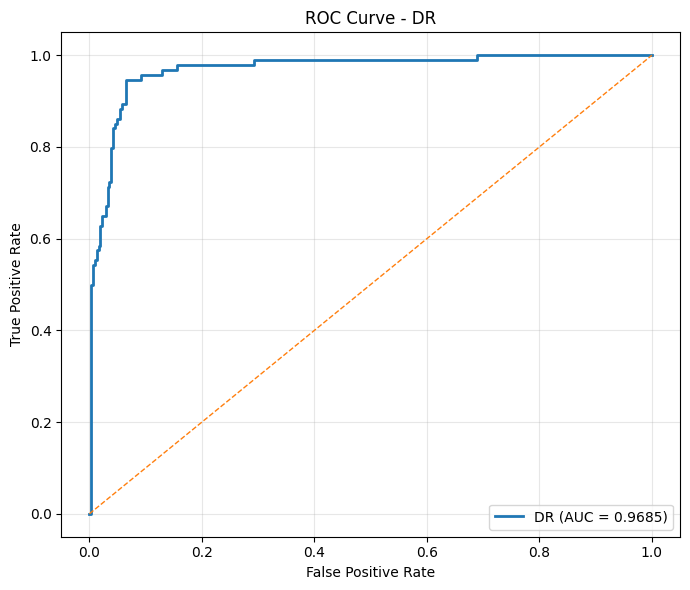

MH        : AUC = 0.9816


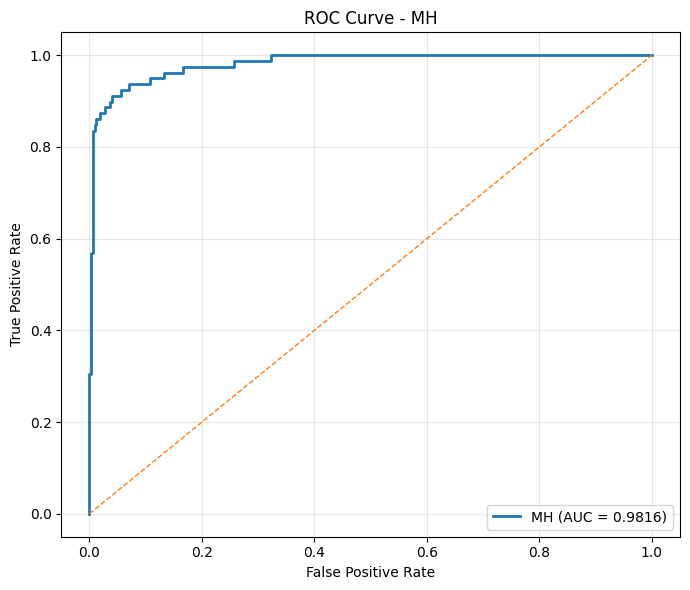

ODC       : AUC = 0.8716


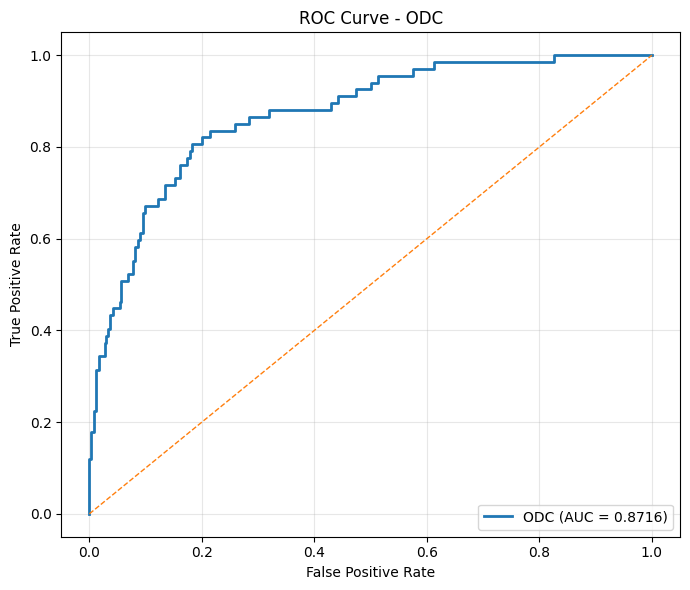

TSLN      : AUC = 0.9769


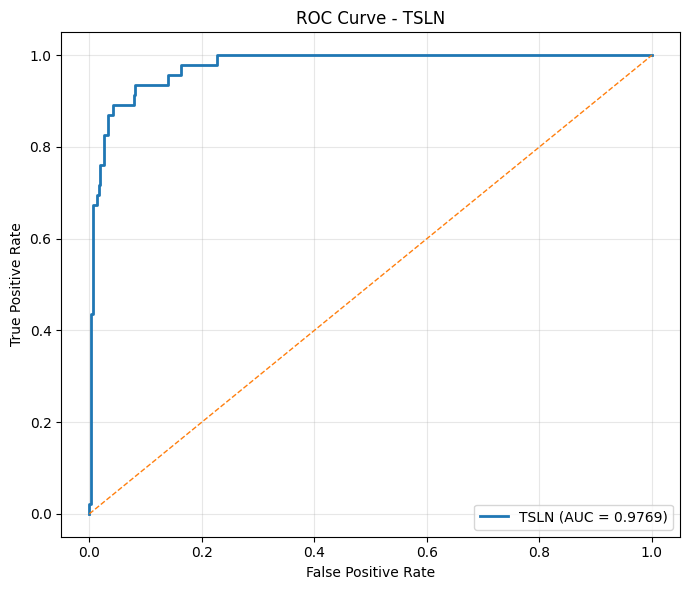

DN        : AUC = 0.7626


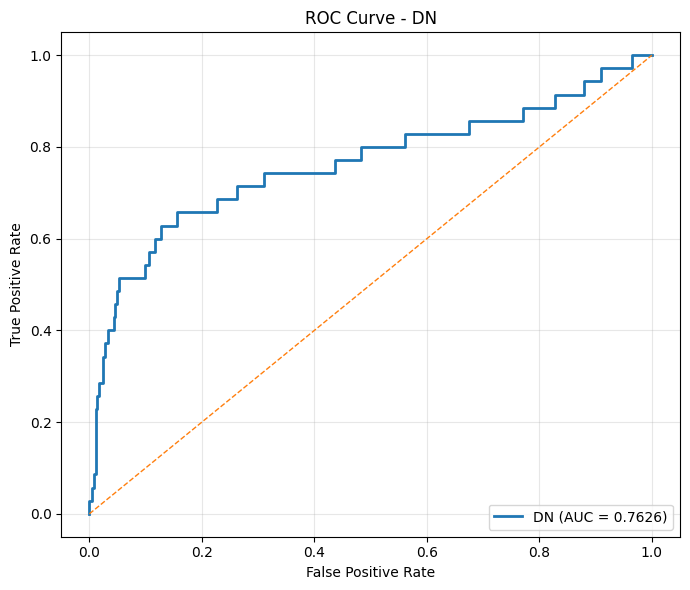

ARMD      : AUC = 0.9941


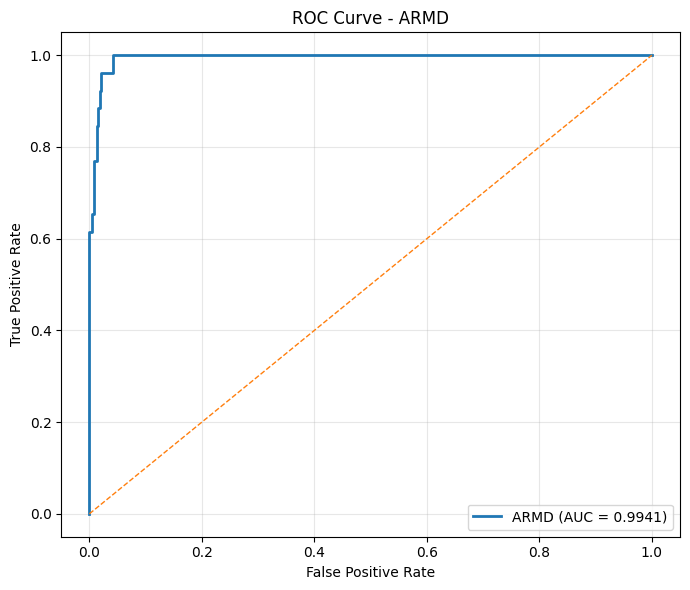

MYA       : AUC = 0.9947


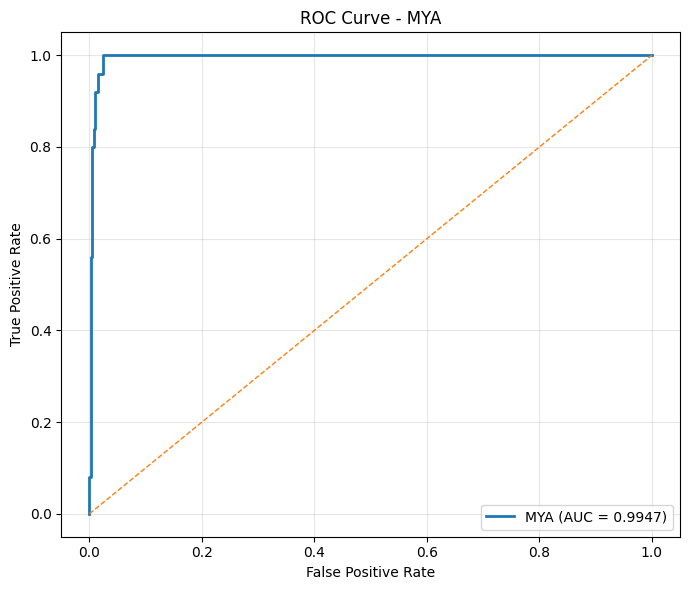

BRVO      : AUC = 0.9566


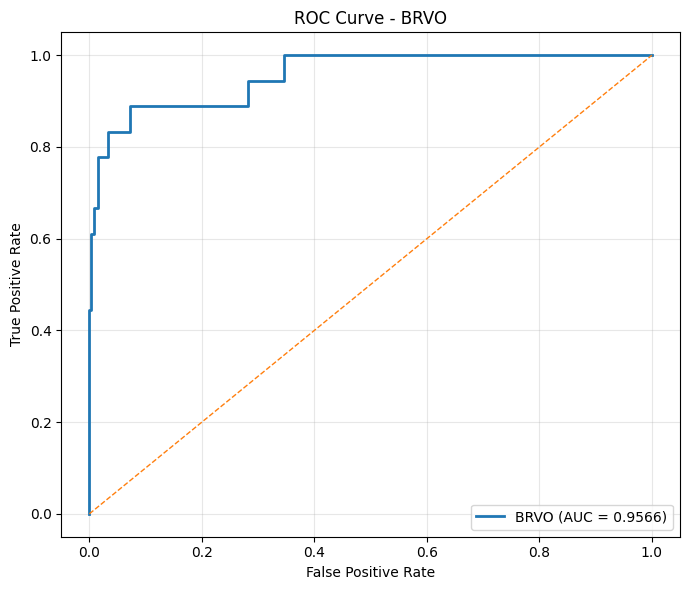

ODP       : AUC = 0.8405


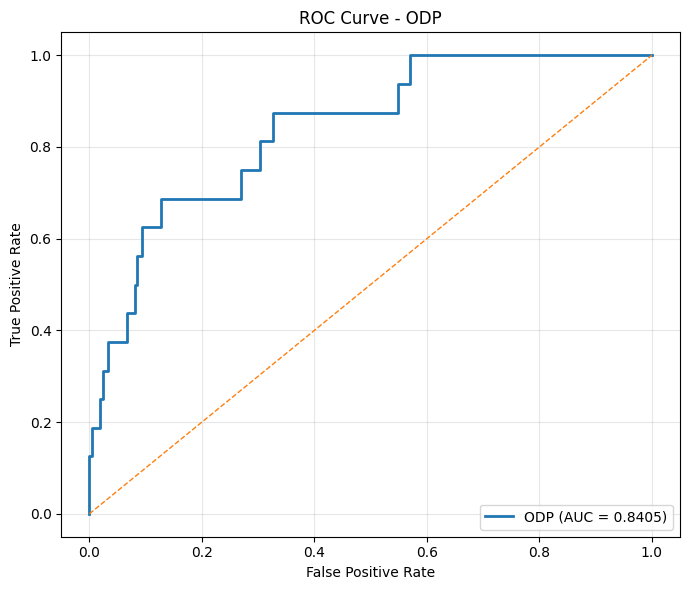

Is_Normal : AUC = 0.9651


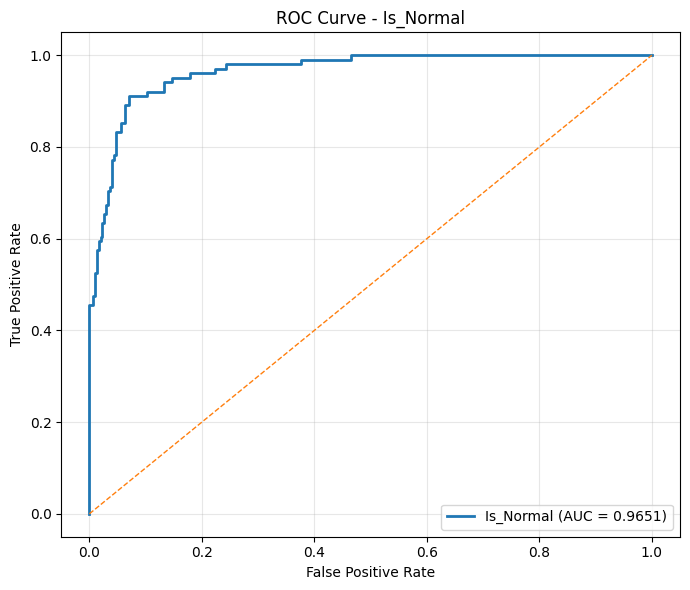


PER-CLASS AUC SUMMARY


,Class,ROC_AUC
0,MYA,0.994695
1,ARMD,0.994067
2,MH,0.981581
3,TSLN,0.976917
4,DR,0.968465
5,Is_Normal,0.965133
6,BRVO,0.956597
7,ODC,0.871642
8,ODP,0.840512
9,DN,0.762554



AUC results saved to:
/kaggle/working/retfound_results/retfound_per_class_auc.csv

ROC curves saved to:
/kaggle/working/retfound_results/roc_curves

STEP 38 COMPLETED


In [60]:
# ================================================================
# STEP 38: PER-CLASS ROC-AUC AND ROC CURVES
# ================================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    roc_auc_score
)

# ------------------------------------------------
# Results directory
# ------------------------------------------------

ROC_DIR = os.path.join(
    RESULTS_DIR,
    "roc_curves"
)

os.makedirs(ROC_DIR, exist_ok=True)


# ------------------------------------------------
# Calculate per-class AUC
# ------------------------------------------------

class_auc_results = []

print("=" * 70)
print("PER-CLASS ROC-AUC")
print("=" * 70)

for i, class_name in enumerate(label_columns_saved):

    y_true = test_labels[:, i]
    y_score = test_probabilities[:, i]

    # ROC curve
    fpr, tpr, thresholds = roc_curve(
        y_true,
        y_score
    )

    # AUC
    auc_value = roc_auc_score(
        y_true,
        y_score
    )

    class_auc_results.append({
        "Class": class_name,
        "ROC_AUC": auc_value
    })

    print(
        f"{class_name:<10}: "
        f"AUC = {auc_value:.4f}"
    )

    # ------------------------------------------------
    # Save individual ROC curve
    # ------------------------------------------------

    plt.figure(figsize=(7, 6))

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{class_name} (AUC = {auc_value:.4f})"
    )

    plt.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        linewidth=1
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")

    plt.title(
        f"ROC Curve - {class_name}"
    )

    plt.legend(
        loc="lower right"
    )

    plt.grid(alpha=0.3)

    plt.tight_layout()

    plt.savefig(
        os.path.join(
            ROC_DIR,
            f"ROC_{class_name}.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()


# ------------------------------------------------
# Create AUC dataframe
# ------------------------------------------------

class_auc_df = pd.DataFrame(
    class_auc_results
)

# Sort from highest to lowest AUC
class_auc_df = class_auc_df.sort_values(
    "ROC_AUC",
    ascending=False
).reset_index(drop=True)


# ------------------------------------------------
# Save AUC results
# ------------------------------------------------

AUC_FILE = os.path.join(
    RESULTS_DIR,
    "retfound_per_class_auc.csv"
)

class_auc_df.to_csv(
    AUC_FILE,
    index=False
)


# ------------------------------------------------
# Display final table
# ------------------------------------------------

print("\n" + "=" * 70)
print("PER-CLASS AUC SUMMARY")
print("=" * 70)

display(class_auc_df)

print("\nAUC results saved to:")
print(AUC_FILE)

print("\nROC curves saved to:")
print(ROC_DIR)

print("\n" + "=" * 70)
print("STEP 38 COMPLETED")
print("=" * 70)

In [6]:
# ================================================================
# STEP 39C — RESTORE RETFound SOURCE CODE
# ================================================================

import os
import subprocess
import sys

RETFOUND_REPO = "/kaggle/working/RETFound_MAE"

print("=" * 70)
print("RESTORING RETFound SOURCE CODE")
print("=" * 70)

# Remove incomplete copy if it exists
if os.path.exists(RETFOUND_REPO):
    subprocess.run(
        ["rm", "-rf", RETFOUND_REPO],
        check=True
    )

# Clone official RETFound-MAE repository
subprocess.run(
    [
        "git",
        "clone",
        "https://github.com/rmaphoh/RETFound_MAE.git",
        RETFOUND_REPO
    ],
    check=True
)

# Add repository to Python path
if RETFOUND_REPO not in sys.path:
    sys.path.insert(0, RETFOUND_REPO)

# Verify
models_vit_path = os.path.join(
    RETFOUND_REPO,
    "models_vit.py"
)

print("\nRETFound repository restored.")
print("Repository exists :", os.path.exists(RETFOUND_REPO))
print("models_vit.py     :", os.path.exists(models_vit_path))
print("Path              :", models_vit_path)

print("=" * 70)

RESTORING RETFound SOURCE CODE


Cloning into '/kaggle/working/RETFound_MAE'...



RETFound repository restored.
Repository exists : True
models_vit.py     : True
Path              : /kaggle/working/RETFound_MAE/models_vit.py


In [8]:
# ================================================================
# STEP 39E — FIX RETFound IMPORT PATH
# ================================================================

import os
import sys

RETFOUND_REPO = "/kaggle/working/RETFound_MAE"
MODELS_VIT = os.path.join(RETFOUND_REPO, "models_vit.py")

print("=" * 70)
print("FIXING RETFound IMPORT PATH")
print("=" * 70)

# Check the files first
print("\nRETFound folder exists :", os.path.isdir(RETFOUND_REPO))
print("models_vit.py exists   :", os.path.isfile(MODELS_VIT))

# Add the folder to Python's import path
if os.path.isdir(RETFOUND_REPO):
    if RETFOUND_REPO in sys.path:
        sys.path.remove(RETF0UND_REPO) if "RETF0UND_REPO" in globals() and RETF0UND_REPO in sys.path else None

    sys.path.insert(0, RETFOUND_REPO)

# Show Python path being used
print("\nPython import path:")
print(sys.path[0])

# Import RETFound
try:
    import models_vit
    print("\nmodels_vit imported successfully. ✅")

except Exception as e:
    print("\nImport failed:")
    print(type(e).__name__, ":", e)

print("\n" + "=" * 70)

FIXING RETFound IMPORT PATH

RETFound folder exists : True
models_vit.py exists   : True

Python import path:
/kaggle/working/RETFound_MAE

Import failed:
ModuleNotFoundError : No module named 'models_vit'



In [9]:
# ================================================================
# STEP 39F — DIRECTLY LOAD RETFound models_vit.py
# ================================================================

import os
import sys
import importlib.util

RETFOUND_REPO = "/kaggle/working/RETFound_MAE"
MODELS_VIT_PATH = os.path.join(RETFOUND_REPO, "models_vit.py")

print("=" * 70)
print("DIRECTLY LOADING RETFound models_vit.py")
print("=" * 70)

print("\nFile exists :", os.path.isfile(MODELS_VIT_PATH))
print("File path   :", MODELS_VIT_PATH)

# ------------------------------------------------
# Load models_vit.py directly
# ------------------------------------------------
spec = importlib.util.spec_from_file_location(
    "models_vit",
    MODELS_VIT_PATH
)

models_vit = importlib.util.module_from_spec(spec)

# Register module
sys.modules["models_vit"] = models_vit

# Execute the file
spec.loader.exec_module(models_vit)

print("\nmodels_vit loaded successfully. ✅")

# ------------------------------------------------
# Verify RETFound constructors
# ------------------------------------------------
print("\nRETFound constructors:")

print("RETFound_mae   :", models_vit.RETFound_mae)
print("RETFound_dinov2:", models_vit.RETFound_dinov2)

print("\n" + "=" * 70)
print("RETFound ARCHITECTURE READY")
print("=" * 70)

DIRECTLY LOADING RETFound models_vit.py

File exists : True
File path   : /kaggle/working/RETFound_MAE/models_vit.py

models_vit loaded successfully. ✅

RETFound constructors:
RETFound_mae   : <function RETFound_mae at 0x7dbac6626520>
RETFound_dinov2: <function RETFound_dinov2 at 0x7dbab61ba520>

RETFound ARCHITECTURE READY


/usr/local/lib/python3.12/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


In [12]:
# ================================================================
# FIND THE ACTUAL RETFound CHECKPOINT
# ================================================================

import os

print("=" * 70)
print("SEARCHING FOR RETFound CHECKPOINT")
print("=" * 70)

search_paths = [
    "/kaggle/working",
    "/kaggle/input"
]

checkpoint_files = []

for search_path in search_paths:

    if not os.path.exists(search_path):
        continue

    for root, dirs, files in os.walk(search_path):

        for file in files:

            if file.lower().endswith((".pth", ".pt", ".ckpt")):

                full_path = os.path.join(root, file)

                checkpoint_files.append(full_path)


print("\nCheckpoint files found:")

if len(checkpoint_files) == 0:

    print("NO CHECKPOINT FILES FOUND.")

else:

    for i, path in enumerate(checkpoint_files):

        size_gb = os.path.getsize(path) / (1024 ** 3)

        print(
            f"{i}: {path} "
            f"({size_gb:.2f} GB)"
        )

print("\nTotal checkpoint files:", len(checkpoint_files))

SEARCHING FOR RETFound CHECKPOINT

Checkpoint files found:
NO CHECKPOINT FILES FOUND.

Total checkpoint files: 0


In [13]:
import os

print("=" * 70)
print("CHECKING KAGGLE SESSION")
print("=" * 70)

paths_to_check = [
    "/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases",
    "/kaggle/working/RETFound_MAE",
    "/kaggle/working/RETFound_MAE/models_vit.py",
    "/kaggle/working/retfound_checkpoints"
]

for path in paths_to_check:
    print(f"{path:<75} : {os.path.exists(path)}")

CHECKING KAGGLE SESSION
/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases                   : True
/kaggle/working/RETFound_MAE                                                : True
/kaggle/working/RETFound_MAE/models_vit.py                                  : True
/kaggle/working/retfound_checkpoints                                        : False


In [14]:
# ================================================================
# RECREATE CHECKPOINT DIRECTORY
# ================================================================

import os

CHECKPOINT_DIR = "/kaggle/working/retfound_checkpoints"

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

print("=" * 70)
print("CHECKPOINT DIRECTORY READY")
print("=" * 70)

print("\nCheckpoint directory:")
print(CHECKPOINT_DIR)

print("\nExists:", os.path.exists(CHECKPOINT_DIR))

CHECKPOINT DIRECTORY READY

Checkpoint directory:
/kaggle/working/retfound_checkpoints

Exists: True


In [15]:
# ================================================================
# CHECK EXISTING RETFound TRAINING SETUP
# ================================================================

print("=" * 70)
print("CHECKING EXISTING TRAINING SETUP")
print("=" * 70)

variables_to_check = [
    "model",
    "train_loader",
    "val_loader",
    "test_loader",
    "criterion",
    "optimizer",
    "scheduler",
    "scaler",
    "device"
]

for var in variables_to_check:
    exists = var in globals()
    print(f"{var:<15} : {exists}")

print("\n" + "=" * 70)
print("CHECKING DATASET SIZES")
print("=" * 70)

if "train_loader" in globals():
    print("Train batches      :", len(train_loader))

if "val_loader" in globals():
    print("Validation batches :", len(val_loader))

if "test_loader" in globals():
    print("Test batches       :", len(test_loader))

print("\n" + "=" * 70)
print("CHECK COMPLETED")
print("=" * 70)

CHECKING EXISTING TRAINING SETUP
model           : True
train_loader    : False
val_loader      : False
test_loader     : False
criterion       : False
optimizer       : False
scheduler       : False
scaler          : False
device          : False

CHECKING DATASET SIZES

CHECK COMPLETED


In [16]:
# ================================================================
# RESTORE RETFound TRAINING ENVIRONMENT
# ================================================================

import os
import sys
import gc
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms as transforms

# ------------------------------------------------
# 1. Basic configuration
# ------------------------------------------------

DATASET_PATH = "/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases"
RETFOUND_PATH = "/kaggle/working/RETFound_MAE"
CHECKPOINT_DIR = "/kaggle/working/retfound_checkpoints"

LABEL_COLUMNS = [
    "DR",
    "MH",
    "ODC",
    "TSLN",
    "DN",
    "ARMD",
    "MYA",
    "BRVO",
    "ODP",
    "Is_Normal"
]

NUM_CLASSES = len(LABEL_COLUMNS)

BATCH_SIZE = 8
NUM_WORKERS = 2
IMAGE_SIZE = 224

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# ------------------------------------------------
# 2. Import RETFound source
# ------------------------------------------------

sys.path.insert(0, RETFOUND_PATH)

import importlib.util

models_vit_path = os.path.join(
    RETFOUND_PATH,
    "models_vit.py"
)

spec = importlib.util.spec_from_file_location(
    "models_vit",
    models_vit_path
)

models_vit = importlib.util.module_from_spec(spec)

spec.loader.exec_module(models_vit)

# ------------------------------------------------
# 3. Verify environment
# ------------------------------------------------

print("=" * 70)
print("RETFound TRAINING ENVIRONMENT RESTORED")
print("=" * 70)

print("\nDataset exists :", os.path.exists(DATASET_PATH))
print("RETFound exists:", os.path.exists(RETFOUND_PATH))
print("models_vit.py  :", os.path.exists(models_vit_path))
print("Checkpoint dir :", os.path.exists(CHECKPOINT_DIR))

print("\nNumber of classes :", NUM_CLASSES)
print("Classes          :", LABEL_COLUMNS)

print("\nDevice:", device)

print(
    "Available GPUs:",
    torch.cuda.device_count()
)

if torch.cuda.is_available():

    for i in range(torch.cuda.device_count()):

        print(
            f"GPU {i}:",
            torch.cuda.get_device_name(i)
        )

print("\nRETFound constructors:")
print("RETFound_mae   :", models_vit.RETFound_mae)
print("RETFound_dinov2:", models_vit.RETFound_dinov2)

print("\n" + "=" * 70)
print("ENVIRONMENT RESTORATION COMPLETED")
print("=" * 70)

RETFound TRAINING ENVIRONMENT RESTORED

Dataset exists : True
RETFound exists: True
models_vit.py  : True
Checkpoint dir : True

Number of classes : 10
Classes          : ['DR', 'MH', 'ODC', 'TSLN', 'DN', 'ARMD', 'MYA', 'BRVO', 'ODP', 'Is_Normal']

Device: cuda
Available GPUs: 2
GPU 0: Tesla T4
GPU 1: Tesla T4

RETFound constructors:
RETFound_mae   : <function RETFound_mae at 0x7dbab61bbba0>
RETFound_dinov2: <function RETFound_dinov2 at 0x7dba577d0040>

ENVIRONMENT RESTORATION COMPLETED


In [17]:
# ================================================================
# RESTORE TRAIN / VALIDATION / TEST DATALOADERS
# ================================================================

import os
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import torchvision.transforms as transforms

print("=" * 70)
print("RESTORING DATASETS AND DATALOADERS")
print("=" * 70)


# ------------------------------------------------
# 1. Paths
# ------------------------------------------------

TRAIN_EXCEL = os.path.join(
    DATASET_PATH,
    "splits_Excel",
    "train.xlsx"
)

VAL_EXCEL = os.path.join(
    DATASET_PATH,
    "splits_Excel",
    "validate.xlsx"
)

TEST_EXCEL = os.path.join(
    DATASET_PATH,
    "splits_Excel",
    "test.xlsx"
)

print("\nExcel files:")
print("Train      :", os.path.exists(TRAIN_EXCEL))
print("Validation :", os.path.exists(VAL_EXCEL))
print("Test       :", os.path.exists(TEST_EXCEL))


# ------------------------------------------------
# 2. Load Excel files
# ------------------------------------------------

train_df = pd.read_excel(TRAIN_EXCEL)
val_df = pd.read_excel(VAL_EXCEL)
test_df = pd.read_excel(TEST_EXCEL)

print("\nDataset sizes:")
print("Train      :", len(train_df))
print("Validation :", len(val_df))
print("Test       :", len(test_df))


# ------------------------------------------------
# 3. Build image lookup
# ------------------------------------------------
# IMPORTANT:
# Image names such as Training_1, Validation_1,
# Testing_10 are ONLY image IDs.
#
# They DO NOT determine whether an image belongs
# to train/validation/test.
# The Excel split determines the split.
# ------------------------------------------------

def build_image_lookup(split_folder):

    image_lookup = {}

    split_path = os.path.join(
        DATASET_PATH,
        split_folder
    )

    for root, dirs, files in os.walk(split_path):

        for file in files:

            if file.lower().endswith(
                (".png", ".jpg", ".jpeg")
            ):

                image_key = os.path.splitext(file)[0]

                full_path = os.path.join(
                    root,
                    file
                )

                # Same image may occur in multiple
                # disease folders because it is multi-label.
                #
                # We only need ONE physical image path.
                if image_key not in image_lookup:

                    image_lookup[image_key] = full_path

    return image_lookup


print("\nBuilding image lookup...")

train_images = build_image_lookup("Train")
val_images = build_image_lookup("Validate")
test_images = build_image_lookup("Test")

print("Train images found      :", len(train_images))
print("Validation images found :", len(val_images))
print("Test images found       :", len(test_images))


# ------------------------------------------------
# 4. Dataset class
# ------------------------------------------------

class RFMidDataset(Dataset):

    def __init__(
        self,
        dataframe,
        image_lookup,
        transform=None
    ):

        self.df = dataframe.reset_index(
            drop=True
        )

        self.image_lookup = image_lookup
        self.transform = transform

        # Verify every Excel image exists
        missing = []

        for image_key in self.df["Image_Key"]:

            if image_key not in self.image_lookup:

                missing.append(image_key)

        if missing:

            raise RuntimeError(
                f"{len(missing)} images are missing. "
                f"Examples: {missing[:10]}"
            )

    def __len__(self):

        return len(self.df)

    def __getitem__(self, index):

        row = self.df.iloc[index]

        image_key = row["Image_Key"]

        image_path = self.image_lookup[
            image_key
        ]

        image = Image.open(
            image_path
        ).convert("RGB")

        if self.transform is not None:

            image = self.transform(image)

        labels = row[
            LABEL_COLUMNS
        ].values.astype(
            np.float32
        )

        labels = torch.tensor(
            labels,
            dtype=torch.float32
        )

        return image, labels, image_key


# ------------------------------------------------
# 5. Image transformations
# ------------------------------------------------

transform = transforms.Compose([

    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[
            0.485,
            0.456,
            0.406
        ],
        std=[
            0.229,
            0.224,
            0.225
        ]
    )
])


# ------------------------------------------------
# 6. Create datasets
# ------------------------------------------------

train_dataset = RFMidDataset(
    train_df,
    train_images,
    transform
)

val_dataset = RFMidDataset(
    val_df,
    val_images,
    transform
)

test_dataset = RFMidDataset(
    test_df,
    test_images,
    transform
)


# ------------------------------------------------
# 7. Create DataLoaders
# ------------------------------------------------

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=True,
    drop_last=False
)


# ------------------------------------------------
# 8. Verify
# ------------------------------------------------

print("\n" + "=" * 70)
print("DATALOADERS RESTORED")
print("=" * 70)

print("\nDataset sizes:")
print("Train      :", len(train_dataset))
print("Validation :", len(val_dataset))
print("Test       :", len(test_dataset))

print("\nNumber of batches:")
print("Train      :", len(train_loader))
print("Validation :", len(val_loader))
print("Test       :", len(test_loader))


# ------------------------------------------------
# 9. Test one batch
# ------------------------------------------------

images, labels, image_keys = next(
    iter(train_loader)
)

print("\nSample batch:")
print("Images     :", images.shape)
print("Labels     :", labels.shape)
print("First key  :", image_keys[0])

print("\n" + "=" * 70)
print("DATASET / DATALOADER RESTORATION COMPLETED")
print("=" * 70)

RESTORING DATASETS AND DATALOADERS

Excel files:
Train      : True
Validation : True
Test       : True

Dataset sizes:
Train      : 1906
Validation : 402
Test       : 402

Building image lookup...
Train images found      : 1906
Validation images found : 402
Test images found       : 402

DATALOADERS RESTORED

Dataset sizes:
Train      : 1906
Validation : 402
Test       : 402

Number of batches:
Train      : 239
Validation : 51
Test       : 51

Sample batch:
Images     : torch.Size([8, 3, 224, 224])
Labels     : torch.Size([8, 10])
First key  : Training_1067

DATASET / DATALOADER RESTORATION COMPLETED


In [19]:
# ================================================================
# FIX RETFound DATA PARALLEL FORWARD
# ================================================================

import torch
import torch.nn as nn
import gc

print("=" * 70)
print("FIXING RETFound MULTI-GPU FORWARD")
print("=" * 70)


# ------------------------------------------------
# 1. Remove the previous model
# ------------------------------------------------

if "model" in globals():
    del model

if "backbone" in globals():
    del backbone

gc.collect()
torch.cuda.empty_cache()


# ------------------------------------------------
# 2. Create a fresh RETFound backbone
# ------------------------------------------------

print("\nCreating fresh RETFound backbone...")

backbone = models_vit.RETFound_mae(
    img_size=224,
    num_classes=NUM_CLASSES,
    global_pool=False
)

# 10-class classification head
backbone.head = nn.Linear(
    1024,
    NUM_CLASSES
)


# ------------------------------------------------
# 3. Wrapper with a normal forward()
# ------------------------------------------------
# IMPORTANT:
# We do NOT modify backbone.forward().
# This allows DataParallel to replicate the model
# correctly across both GPUs.

class RETFoundClassifier(nn.Module):

    def __init__(self, backbone):

        super().__init__()

        self.backbone = backbone

    def forward(self, x):

        # RETFound custom feature extraction
        features = self.backbone.forward_features(x)

        # Direct classification head
        logits = self.backbone.head(features)

        return logits


model = RETFoundClassifier(backbone)


# ------------------------------------------------
# 4. Move the complete wrapper to GPU 0
# ------------------------------------------------

model = model.to(device)


# ------------------------------------------------
# 5. Enable DataParallel
# ------------------------------------------------

if torch.cuda.device_count() > 1:

    model = nn.DataParallel(
        model,
        device_ids=list(
            range(torch.cuda.device_count())
        ),
        output_device=0
    )

    print(
        f"\nUsing {torch.cuda.device_count()} GPUs "
        "with DataParallel."
    )

else:

    print("\nUsing single GPU.")


# ------------------------------------------------
# 6. Check classification head
# ------------------------------------------------

if isinstance(model, nn.DataParallel):

    print("\nClassification head:")
    print(model.module.backbone.head)

else:

    print("\nClassification head:")
    print(model.backbone.head)


# ------------------------------------------------
# 7. Parameter count
# ------------------------------------------------

total_parameters = sum(
    p.numel()
    for p in model.parameters()
)

trainable_parameters = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nTotal parameters     :", f"{total_parameters:,}")
print(
    "Trainable parameters :",
    f"{trainable_parameters:,}"
)


# ------------------------------------------------
# 8. Test multi-GPU forward pass
# ------------------------------------------------

print("\nTesting multi-GPU forward pass...")

images, labels, image_keys = next(
    iter(train_loader)
)

images = images.to(
    device,
    non_blocking=True
)

labels = labels.to(
    device,
    non_blocking=True
)

model.eval()

with torch.no_grad():

    logits = model(images)


print("\nInput shape :", images.shape)
print("Output shape:", logits.shape)
print("Labels shape:", labels.shape)
print("Input device:", images.device)
print("Output device:", logits.device)


# ------------------------------------------------
# 9. Verify output
# ------------------------------------------------

assert logits.shape == labels.shape, (
    f"Shape mismatch: "
    f"logits={logits.shape}, "
    f"labels={labels.shape}"
)

assert logits.shape[1] == NUM_CLASSES, (
    f"Expected {NUM_CLASSES} outputs, "
    f"got {logits.shape[1]}"
)


print("\n" + "=" * 70)
print("MULTI-GPU RETFound FORWARD PASS SUCCESSFUL")
print("=" * 70)

FIXING RETFound MULTI-GPU FORWARD

Creating fresh RETFound backbone...

Using 2 GPUs with DataParallel.

Classification head:
Linear(in_features=1024, out_features=10, bias=True)

Total parameters     : 303,311,882
Trainable parameters : 303,311,882

Testing multi-GPU forward pass...

Input shape : torch.Size([8, 3, 224, 224])
Output shape: torch.Size([8, 10])
Labels shape: torch.Size([8, 10])
Input device: cuda:0
Output device: cuda:0

MULTI-GPU RETFound FORWARD PASS SUCCESSFUL


In [21]:
# ================================================================
# SEARCH FOR RETFound PRETRAINED CHECKPOINT
# ================================================================

import os

print("=" * 70)
print("SEARCHING FOR RETFound PRETRAINED CHECKPOINT")
print("=" * 70)

search_roots = [
    "/kaggle/input",
    "/kaggle/working"
]

checkpoint_files = []

for search_root in search_roots:

    print(f"\nSearching: {search_root}")

    if not os.path.exists(search_root):
        print("Path does not exist.")
        continue

    for root, dirs, files in os.walk(search_root):

        for file in files:

            if file.lower().endswith((".pth", ".pt", ".ckpt")):

                full_path = os.path.join(root, file)

                size_gb = os.path.getsize(full_path) / (1024 ** 3)

                checkpoint_files.append(
                    (full_path, size_gb)
                )

                print(
                    f"{full_path}   "
                    f"[{size_gb:.2f} GB]"
                )


print("\n" + "=" * 70)
print("CHECKPOINT SEARCH SUMMARY")
print("=" * 70)

print(
    f"\nTotal checkpoint files found: "
    f"{len(checkpoint_files)}"
)

if len(checkpoint_files) == 0:

    print("\nNO .pth / .pt / .ckpt FILES FOUND.")

    print("\nThis means the pretrained RETFound weights")
    print("are not currently attached to this Kaggle session.")

else:

    print("\nCheckpoint files available:")

    for path, size_gb in checkpoint_files:

        print(f"\n{path}")
        print(f"Size: {size_gb:.2f} GB")

print("\n" + "=" * 70)
print("SEARCH COMPLETED")
print("=" * 70)

SEARCHING FOR RETFound PRETRAINED CHECKPOINT

Searching: /kaggle/input

Searching: /kaggle/working

CHECKPOINT SEARCH SUMMARY

Total checkpoint files found: 0

NO .pth / .pt / .ckpt FILES FOUND.

This means the pretrained RETFound weights
are not currently attached to this Kaggle session.

SEARCH COMPLETED


In [22]:
# ================================================================
# PREPARE RETFound PRETRAINED WEIGHTS
# ================================================================

import os
import subprocess
import sys

print("=" * 70)
print("PREPARING RETFound PRETRAINED WEIGHTS")
print("=" * 70)

WEIGHTS_DIR = "/kaggle/working/RETFound_weights"

os.makedirs(WEIGHTS_DIR, exist_ok=True)

print("\nWeights directory:")
print(WEIGHTS_DIR)

# Check Hugging Face CLI
result = subprocess.run(
    ["huggingface-cli", "--version"],
    capture_output=True,
    text=True
)

if result.returncode == 0:
    print("\nHugging Face CLI is available.")
    print(result.stdout.strip())
else:
    print("\nHugging Face CLI is NOT available.")
    print("Installing huggingface_hub...")

    subprocess.check_call([
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "-U",
        "huggingface_hub"
    ])

    print("huggingface_hub installed successfully.")

print("\n" + "=" * 70)
print("PREPARATION COMPLETED")
print("=" * 70)

PREPARING RETFound PRETRAINED WEIGHTS

Weights directory:
/kaggle/working/RETFound_weights

Hugging Face CLI is NOT available.
Installing huggingface_hub...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 795.8/795.8 kB 33.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.3/125.3 kB 8.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 90.5 MB/s eta 0:00:00
huggingface_hub installed successfully.

PREPARATION COMPLETED


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 1.29.0 requires google-cloud-bigquery-storage>=2.0.0, which is not installed.


In [23]:
from huggingface_hub import whoami

try:
    info = whoami()
    print("Hugging Face login: SUCCESS")
    print("Username:", info["name"])
except Exception as e:
    print("Hugging Face login: NOT FOUND")
    print("You need to log in before downloading the gated RETFound weights.")

Hugging Face login: NOT FOUND
You need to log in before downloading the gated RETFound weights.


In [1]:
import huggingface_hub

print("huggingface_hub version:", huggingface_hub.__version__)

from huggingface_hub import login
print("Hugging Face import: SUCCESS")

huggingface_hub version: 1.11.0
Hugging Face import: SUCCESS


In [13]:
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()

HF_TOKEN = user_secrets.get_secret("HF_TOKEN")

print("HF_TOKEN found:", HF_TOKEN is not None)
print("Token length:", len(HF_TOKEN))

HF_TOKEN found: True
Token length: 37


In [14]:
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF_TOKEN")

login(token=HF_TOKEN, add_to_git_credential=False)

print("Hugging Face authentication: SUCCESS")

Hugging Face authentication: SUCCESS


In [1]:
from huggingface_hub import list_repo_files

REPO_ID = "YukunZhou/RETFound_mae_natureCFP"

files = list_repo_files(REPO_ID)

print("Files available in RETFound repository:")
for f in files:
    print(f)

Files available in RETFound repository:
.gitattributes
README.md
RETFound_mae_natureCFP.pth
config.json


In [3]:
from kaggle_secrets import UserSecretsClient
from huggingface_hub import hf_hub_download

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF_TOKEN")

print("Using Kaggle HF token:", HF_TOKEN is not None)

test_file = hf_hub_download(
    repo_id="YukunZhou/RETFound_mae_natureCFP",
    filename="RETFound_mae_natureCFP.pth",
    token=HF_TOKEN
)

print("ACCESS SUCCESS!")
print("File:", test_file)

Using Kaggle HF token: True


RETFound_mae_natureCFP.pth:   0%|          | 0.00/3.95G [00:00<?, ?B/s]

ACCESS SUCCESS!
File: /root/.cache/huggingface/hub/models--YukunZhou--RETFound_mae_natureCFP/snapshots/556830f78214f0e8da35af965292ac5a3180ac47/RETFound_mae_natureCFP.pth


In [4]:
import torch

PRETRAINED_PATH = "/root/.cache/huggingface/hub/models--YukunZhou--RETFound_mae_natureCFP/snapshots/556830f78214f0e8da35af965292ac5a3180ac47/RETFound_mae_natureCFP.pth"

print("Loading checkpoint information...")

checkpoint = torch.load(
    PRETRAINED_PATH,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("\nCheckpoint keys:")
    for key in checkpoint.keys():
        print(" -", key)
else:
    print("\nCheckpoint is not a dictionary.")

del checkpoint

Loading checkpoint information...
Checkpoint type: <class 'dict'>

Checkpoint keys:
 - model
 - optimizer
 - epoch
 - scaler
 - args


In [5]:
import torch

PRETRAINED_PATH = "/root/.cache/huggingface/hub/models--YukunZhou--RETFound_mae_natureCFP/snapshots/556830f78214f0e8da35af965292ac5a3180ac47/RETFound_mae_natureCFP.pth"

checkpoint = torch.load(
    PRETRAINED_PATH,
    map_location="cpu",
    weights_only=False
)

pretrained_state = checkpoint["model"]

print("Number of pretrained parameters:", len(pretrained_state))

print("\nFirst 20 keys:")
for i, key in enumerate(pretrained_state.keys()):
    if i >= 20:
        break
    print(f"{i+1:2d}. {key}")

del checkpoint
del pretrained_state

Number of pretrained parameters: 398

First 20 keys:
 1. cls_token
 2. pos_embed
 3. mask_token
 4. decoder_pos_embed
 5. patch_embed.proj.weight
 6. patch_embed.proj.bias
 7. blocks.0.norm1.weight
 8. blocks.0.norm1.bias
 9. blocks.0.attn.qkv.weight
10. blocks.0.attn.qkv.bias
11. blocks.0.attn.proj.weight
12. blocks.0.attn.proj.bias
13. blocks.0.norm2.weight
14. blocks.0.norm2.bias
15. blocks.0.mlp.fc1.weight
16. blocks.0.mlp.fc1.bias
17. blocks.0.mlp.fc2.weight
18. blocks.0.mlp.fc2.bias
19. blocks.1.norm1.weight
20. blocks.1.norm1.bias


In [8]:
import os
import subprocess

RETFOUND_DIR = "/kaggle/working/RETFound_MAE"

if not os.path.exists(RETFOUND_DIR):
    print("Downloading RETFound source code...")
    
    subprocess.check_call([
        "git", "clone",
        "https://github.com/rmaphoh/RETFound.git",
        RETFOUND_DIR
    ])
    
    print("RETFound source downloaded successfully.")
else:
    print("RETFound source already exists.")

print("\nChecking models_vit.py...")

models_vit_path = os.path.join(RETFOUND_DIR, "models_vit.py")

print("Path:", models_vit_path)
print("Exists:", os.path.exists(models_vit_path))

Cloning into '/kaggle/working/RETFound_MAE'...


RETFound source downloaded successfully.

Checking models_vit.py...
Path: /kaggle/working/RETFound_MAE/models_vit.py
Exists: True


In [9]:
import sys
import importlib.util
import torch
import torch.nn as nn

RETFOUND_DIR = "/kaggle/working/RETFound_MAE"

# Load RETFound source
sys.path.insert(0, RETFOUND_DIR)

spec = importlib.util.spec_from_file_location(
    "models_vit",
    os.path.join(RETFOUND_DIR, "models_vit.py")
)

models_vit = importlib.util.module_from_spec(spec)
spec.loader.exec_module(models_vit)

# Number of classes
NUM_CLASSES = 10

# Create RETFound ViT-Large model
backbone = models_vit.RETFound_mae(
    num_classes=NUM_CLASSES,
    global_pool=True
)

print("RETFound backbone created.")
print("Classification head:", backbone.head)
print("Number of parameters:", sum(p.numel() for p in backbone.parameters()))

/usr/local/lib/python3.12/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


RETFound backbone created.
Classification head: Linear(in_features=1024, out_features=10, bias=True)
Number of parameters: 303311882


In [10]:
import torch

PRETRAINED_PATH = "/root/.cache/huggingface/hub/models--YukunZhou--RETFound_mae_natureCFP/snapshots/556830f78214f0e8da35af965292ac5a3180ac47/RETFound_mae_natureCFP.pth"

print("Loading pretrained RETFound checkpoint...")

checkpoint = torch.load(
    PRETRAINED_PATH,
    map_location="cpu",
    weights_only=False
)

pretrained_state = checkpoint["model"]

# Get current model parameters
model_state = backbone.state_dict()

# Keep only matching parameters
compatible_state = {
    k: v
    for k, v in pretrained_state.items()
    if k in model_state and v.shape == model_state[k].shape
}

print("Total checkpoint parameters:", len(pretrained_state))
print("Compatible parameters:", len(compatible_state))

# Load pretrained parameters
missing, unexpected = backbone.load_state_dict(
    compatible_state,
    strict=False
)

print("\n========== WEIGHTS LOADED ==========")
print("Missing keys:", len(missing))
print("Unexpected keys:", len(unexpected))

if missing:
    print("\nFirst 10 missing keys:")
    for key in missing[:10]:
        print(" -", key)

print("\nRETFound pretrained weights loaded successfully.")

Loading pretrained RETFound checkpoint...
Total checkpoint parameters: 398
Compatible parameters: 292

========== WEIGHTS LOADED ==========
Missing keys: 4
Unexpected keys: 0

First 10 missing keys:
 - fc_norm.weight
 - fc_norm.bias
 - head.weight
 - head.bias

RETFound pretrained weights loaded successfully.


In [11]:
import torch
import torch.nn as nn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Wrap RETFound so it works correctly with our newer timm version
class RETFoundClassifier(nn.Module):
    def __init__(self, backbone):
        super().__init__()
        self.backbone = backbone

    def forward(self, x):
        features = self.backbone.forward_features(x)
        logits = self.backbone.head(features)
        return logits

model = RETFoundClassifier(backbone)

# Multi-GPU
if torch.cuda.device_count() > 1:
    model = nn.DataParallel(model)

model = model.to(device)

print("Model moved to:", device)
print("Number of GPUs:", torch.cuda.device_count())

if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        print(f"GPU {i}: {torch.cuda.get_device_name(i)}")

print("\nClassification head:", backbone.head)
print("Total parameters:", sum(p.numel() for p in model.parameters()))

Model moved to: cuda
Number of GPUs: 2
GPU 0: Tesla T4
GPU 1: Tesla T4

Classification head: Linear(in_features=1024, out_features=10, bias=True)
Total parameters: 303311882


In [12]:
import os
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms

# =========================
# Paths
# =========================
DATASET_ROOT = "/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases"

TRAIN_XLSX = os.path.join(DATASET_ROOT, "splits_Excel", "train.xlsx")
VAL_XLSX   = os.path.join(DATASET_ROOT, "splits_Excel", "validate.xlsx")
TEST_XLSX  = os.path.join(DATASET_ROOT, "splits_Excel", "test.xlsx")

# =========================
# Classes
# =========================
LABEL_COLUMNS = [
    "DR", "MH", "ODC", "TSLN", "DN",
    "ARMD", "MYA", "BRVO", "ODP", "Is_Normal"
]

NUM_CLASSES = len(LABEL_COLUMNS)

# =========================
# Transform
# =========================
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# =========================
# Build image lookup once
# =========================
image_lookup = {}

for root, _, files in os.walk(DATASET_ROOT):
    for file in files:
        name, ext = os.path.splitext(file)

        if ext.lower() in [".jpg", ".jpeg", ".png"]:
            if name not in image_lookup:
                image_lookup[name] = os.path.join(root, file)

print("Images indexed:", len(image_lookup))

# =========================
# Dataset
# =========================
class RFMidDataset(Dataset):
    def __init__(self, excel_path, transform=None):
        self.df = pd.read_excel(excel_path)
        self.transform = transform

        if "Image_Key" not in self.df.columns:
            raise ValueError(
                f"'Image_Key' not found. Columns: {list(self.df.columns)}"
            )

        missing_labels = [
            c for c in LABEL_COLUMNS
            if c not in self.df.columns
        ]

        if missing_labels:
            raise ValueError(
                f"Missing label columns: {missing_labels}"
            )

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image_key = str(row["Image_Key"])

        if image_key not in image_lookup:
            raise FileNotFoundError(
                f"Image not found: {image_key}"
            )

        image = Image.open(
            image_lookup[image_key]
        ).convert("RGB")

        if self.transform:
            image = self.transform(image)

        labels = torch.tensor(
            row[LABEL_COLUMNS].values.astype("float32")
        )

        return image, labels, image_key


# =========================
# Create datasets
# =========================
train_dataset = RFMidDataset(TRAIN_XLSX, transform)
val_dataset   = RFMidDataset(VAL_XLSX, transform)
test_dataset  = RFMidDataset(TEST_XLSX, transform)

# =========================
# DataLoaders
# =========================
BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("\n========== DATASET READY ==========")
print("Train:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

print("\nBatches:")
print("Train:", len(train_loader))
print("Validation:", len(val_loader))
print("Test:", len(test_loader))

images, labels, keys = next(iter(train_loader))

print("\nSample batch:")
print("Images:", images.shape)
print("Labels:", labels.shape)
print("First key:", keys[0])

Images indexed: 2710

========== DATASET READY ==========
Train: 1906
Validation: 402
Test: 402

Batches:
Train: 239
Validation: 51
Test: 51

Sample batch:
Images: torch.Size([8, 3, 224, 224])
Labels: torch.Size([8, 10])
First key: Validation_517


In [13]:
import torch

model.eval()

images, labels, keys = next(iter(train_loader))
images = images.to(device, non_blocking=True)

with torch.no_grad():
    outputs = model(images)

print("========== FORWARD TEST ==========")
print("Input shape :", images.shape)
print("Output shape:", outputs.shape)
print("Expected    :", (images.shape[0], NUM_CLASSES))

print("\nOutput range:")
print("Min:", outputs.min().item())
print("Max:", outputs.max().item())

print("\nForward pass successful!")

========== FORWARD TEST ==========
Input shape : torch.Size([8, 3, 224, 224])
Output shape: torch.Size([8, 1, 10])
Expected    : (8, 10)

Output range:
Min: -0.7924328446388245
Max: 0.9814832210540771

Forward pass successful!


In [14]:
import torch

model.eval()

images, labels, keys = next(iter(train_loader))
images = images.to(device, non_blocking=True)

# Access the underlying model when using DataParallel
base_model = model.module if isinstance(model, torch.nn.DataParallel) else model
backbone = base_model.backbone

with torch.no_grad():
    features = backbone.forward_features(images)

print("========== FEATURE SHAPE CHECK ==========")
print("Input shape   :", images.shape)
print("Feature shape :", features.shape)

with torch.no_grad():
    raw_output = backbone.head(features)

print("Head output   :", raw_output.shape)

========== FEATURE SHAPE CHECK ==========
Input shape   : torch.Size([8, 3, 224, 224])
Feature shape : torch.Size([8, 1, 1024])
Head output   : torch.Size([8, 1, 10])


In [15]:
import torch
import torch.nn as nn

class RETFoundClassifier(nn.Module):
    def __init__(self, backbone):
        super().__init__()
        self.backbone = backbone

    def forward(self, x):
        features = self.backbone.forward_features(x)

        # RETFound with current timm returns [B, 1, 1024]
        # Remove the singleton token dimension
        if features.ndim == 3 and features.shape[1] == 1:
            features = features[:, 0, :]

        logits = self.backbone.head(features)

        return logits


# Recreate wrapper around the pretrained backbone
model = RETFoundClassifier(backbone)

# Use both GPUs
if torch.cuda.device_count() > 1:
    model = nn.DataParallel(model)

model = model.to(device)

print("Classifier wrapper fixed.")

Classifier wrapper fixed.


In [16]:
import torch

model.eval()

images, labels, keys = next(iter(train_loader))
images = images.to(device, non_blocking=True)

with torch.no_grad():
    outputs = model(images)

print("========== FINAL FORWARD TEST ==========")
print("Input shape :", images.shape)
print("Output shape:", outputs.shape)
print("Expected    :", (images.shape[0], NUM_CLASSES))

assert outputs.shape == (images.shape[0], NUM_CLASSES), \
    f"Unexpected output shape: {outputs.shape}"

print("\n✅ Forward pass and output shape are correct!")

========== FINAL FORWARD TEST ==========
Input shape : torch.Size([8, 3, 224, 224])
Output shape: torch.Size([8, 10])
Expected    : (8, 10)

✅ Forward pass and output shape are correct!


In [17]:
import torch
import torch.nn as nn

# Positive-class weights calculated from the TRAINING set
pos_weight = torch.tensor([
    3.3516,   # DR
    4.2077,   # MH
    5.1090,   # ODC
    8.0332,   # TSLN
    10.8385,  # DN
    15.1525,  # ARMD
    15.2906,  # MYA
    21.9639,  # BRVO
    23.7532,  # ODP
    3.0726    # Is_Normal
], dtype=torch.float32)

pos_weight = pos_weight.to(device)

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight
)

print("========== LOSS FUNCTION ==========")
print("Loss:", criterion)
print("\nNumber of classes:", NUM_CLASSES)
print("pos_weight shape:", pos_weight.shape)

for name, weight in zip(LABEL_COLUMNS, pos_weight):
    print(f"{name:10s}: {weight.item():.4f}")

========== LOSS FUNCTION ==========
Loss: BCEWithLogitsLoss()

Number of classes: 10
pos_weight shape: torch.Size([10])
DR        : 3.3516
MH        : 4.2077
ODC       : 5.1090
TSLN      : 8.0332
DN        : 10.8385
ARMD      : 15.1525
MYA       : 15.2906
BRVO      : 21.9639
ODP       : 23.7532
Is_Normal : 3.0726


In [18]:
import torch

LEARNING_RATE = 5e-5
WEIGHT_DECAY = 0.05
NUM_EPOCHS = 30
MIN_LR = 1e-6

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=NUM_EPOCHS,
    eta_min=MIN_LR
)

print("========== OPTIMIZER & SCHEDULER ==========")
print("Optimizer      :", optimizer.__class__.__name__)
print("Learning rate  :", LEARNING_RATE)
print("Weight decay   :", WEIGHT_DECAY)
print("Epochs         :", NUM_EPOCHS)
print("Minimum LR     :", MIN_LR)
print("Initial LR     :", optimizer.param_groups[0]["lr"])
print("Scheduler      :", scheduler.__class__.__name__)

========== OPTIMIZER & SCHEDULER ==========
Optimizer      : AdamW
Learning rate  : 5e-05
Weight decay   : 0.05
Epochs         : 30
Minimum LR     : 1e-06
Initial LR     : 5e-05
Scheduler      : CosineAnnealingLR


In [19]:
import os
import torch

# =========================
# Mixed Precision (AMP)
# =========================
scaler = torch.amp.GradScaler("cuda")

# =========================
# Checkpoint directory
# =========================
CHECKPOINT_DIR = "/kaggle/working/retfound_checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

BEST_CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "best_model.pth"
)

# =========================
# Training tracking
# =========================
best_val_f1 = -1.0
best_val_auc = -1.0

print("========== TRAINING SETUP ==========")
print("AMP enabled        : True")
print("Checkpoint folder  :", CHECKPOINT_DIR)
print("Best model path    :", BEST_CHECKPOINT_PATH)
print("Initial best F1    :", best_val_f1)

========== TRAINING SETUP ==========
AMP enabled        : True
Checkpoint folder  : /kaggle/working/retfound_checkpoints
Best model path    : /kaggle/working/retfound_checkpoints/best_model.pth
Initial best F1    : -1.0


In [22]:
import torch

model.train()

# Get one batch
images, labels, keys = next(iter(train_loader))

images = images.to(device, non_blocking=True)
labels = labels.to(device, non_blocking=True)

# Clear previous gradients
optimizer.zero_grad(set_to_none=True)

# Mixed precision forward + loss
with torch.autocast(device_type="cuda", dtype=torch.float16):
    outputs = model(images)
    loss = criterion(outputs, labels)

# Backward pass
scaler.scale(loss).backward()

# Optimizer update
scaler.step(optimizer)
scaler.update()

print("========== SINGLE-BATCH TEST ==========")
print("Images :", images.shape)
print("Labels :", labels.shape)
print("Output :", outputs.shape)
print("Loss   :", loss.item())
print("Optimizer update: SUCCESS")
print("AMP backward pass: SUCCESS")

========== SINGLE-BATCH TEST ==========
Images : torch.Size([8, 3, 224, 224])
Labels : torch.Size([8, 10])
Output : torch.Size([8, 10])
Loss   : 0.004096038639545441
Optimizer update: SUCCESS
AMP backward pass: SUCCESS


In [ ]:
import os
import numpy as np
import pandas as pd
import torch
from sklearn.metrics import f1_score, roc_auc_score
from tqdm.auto import tqdm

# ============================================================
# Training history
# ============================================================
history = []

print("=" * 70)
print("STARTING RETFOUND FINE-TUNING")
print("=" * 70)
print(f"Epochs       : {NUM_EPOCHS}")
print(f"Batch size   : {BATCH_SIZE}")
print(f"Learning rate: {LEARNING_RATE}")
print(f"GPUs         : {torch.cuda.device_count()}")
print("=" * 70)

# ============================================================
# Training loop
# ============================================================
for epoch in range(1, NUM_EPOCHS + 1):

    # --------------------------------------------------------
    # TRAIN
    # --------------------------------------------------------
    model.train()

    train_loss_sum = 0.0
    train_samples = 0

    train_bar = tqdm(
        train_loader,
        desc=f"Epoch {epoch:02d}/{NUM_EPOCHS} [Train]",
        leave=False
    )

    for images, labels, keys in train_bar:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        batch_size_current = images.size(0)

        train_loss_sum += loss.item() * batch_size_current
        train_samples += batch_size_current

        train_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    train_loss = train_loss_sum / train_samples

    # --------------------------------------------------------
    # VALIDATION
    # --------------------------------------------------------
    model.eval()

    val_loss_sum = 0.0
    val_samples = 0

    all_val_labels = []
    all_val_probs = []

    with torch.no_grad():

        val_bar = tqdm(
            val_loader,
            desc=f"Epoch {epoch:02d}/{NUM_EPOCHS} [Val]",
            leave=False
        )

        for images, labels, keys in val_bar:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            probs = torch.sigmoid(outputs)

            batch_size_current = images.size(0)

            val_loss_sum += loss.item() * batch_size_current
            val_samples += batch_size_current

            all_val_labels.append(
                labels.detach().cpu().numpy()
            )

            all_val_probs.append(
                probs.detach().float().cpu().numpy()
            )

    val_loss = val_loss_sum / val_samples

    all_val_labels = np.concatenate(all_val_labels, axis=0)
    all_val_probs = np.concatenate(all_val_probs, axis=0)

    # --------------------------------------------------------
    # Validation F1 @ 0.5
    # --------------------------------------------------------
    val_predictions = (
        all_val_probs >= 0.5
    ).astype(int)

    val_macro_f1 = f1_score(
        all_val_labels,
        val_predictions,
        average="macro",
        zero_division=0
    )

    val_micro_f1 = f1_score(
        all_val_labels,
        val_predictions,
        average="micro",
        zero_division=0
    )

    # --------------------------------------------------------
    # Validation Macro AUC
    # --------------------------------------------------------
    per_class_auc = []

    for class_idx in range(NUM_CLASSES):

        y_true = all_val_labels[:, class_idx]
        y_score = all_val_probs[:, class_idx]

        # AUC is undefined if only one class is present
        if len(np.unique(y_true)) == 2:
            auc = roc_auc_score(y_true, y_score)
            per_class_auc.append(auc)

    val_macro_auc = np.mean(per_class_auc)

    # --------------------------------------------------------
    # Learning-rate update
    # --------------------------------------------------------
    scheduler.step()

    current_lr = optimizer.param_groups[0]["lr"]

    # --------------------------------------------------------
    # Save history
    # --------------------------------------------------------
    epoch_record = {
        "epoch": epoch,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_macro_f1": val_macro_f1,
        "val_micro_f1": val_micro_f1,
        "val_macro_auc": val_macro_auc,
        "learning_rate": current_lr
    }

    history.append(epoch_record)

    # --------------------------------------------------------
    # Save best model
    # --------------------------------------------------------
    is_best = val_macro_f1 > best_val_f1

    if is_best:

        best_val_f1 = val_macro_f1
        best_val_auc = val_macro_auc

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "scaler_state_dict": scaler.state_dict(),
                "best_val_f1": best_val_f1,
                "val_macro_auc": best_val_auc,
                "label_columns": LABEL_COLUMNS,
                "learning_rate": LEARNING_RATE,
                "batch_size": BATCH_SIZE
            },
            BEST_CHECKPOINT_PATH
        )

    # --------------------------------------------------------
    # Print epoch summary
    # --------------------------------------------------------
    marker = " ⭐ BEST" if is_best else ""

    print(
        f"\nEpoch {epoch:02d}/{NUM_EPOCHS}"
        f" | Train Loss: {train_loss:.4f}"
        f" | Val Loss: {val_loss:.4f}"
        f" | Val Macro-F1: {val_macro_f1:.4f}"
        f" | Val Micro-F1: {val_micro_f1:.4f}"
        f" | Val Macro-AUC: {val_macro_auc:.4f}"
        f" | LR: {current_lr:.2e}"
        f"{marker}"
    )

# ============================================================
# Save training history
# ============================================================
history_df = pd.DataFrame(history)

HISTORY_PATH = os.path.join(
    CHECKPOINT_DIR,
    "training_history.csv"
)

history_df.to_csv(
    HISTORY_PATH,
    index=False
)

print("\n" + "=" * 70)
print("TRAINING COMPLETED")
print("=" * 70)
print(f"Best Validation Macro-F1 : {best_val_f1:.4f}")
print(f"Best Validation Macro-AUC: {best_val_auc:.4f}")
print(f"Best checkpoint           : {BEST_CHECKPOINT_PATH}")
print(f"Training history          : {HISTORY_PATH}")
print("=" * 70)

STARTING RETFOUND FINE-TUNING
Epochs       : 30
Batch size   : 8
Learning rate: 5e-05
GPUs         : 2


Epoch 01/30 [Train]:   0%|          | 0/239 [00:00<?, ?it/s]

Epoch 01/30 [Val]:   0%|          | 0/51 [00:00<?, ?it/s]


Epoch 01/30 | Train Loss: 0.1671 | Val Loss: 1.1164 | Val Macro-F1: 0.6713 | Val Micro-F1: 0.7387 | Val Macro-AUC: 0.9386 | LR: 3.06e-05


Epoch 02/30 [Train]:   0%|          | 0/239 [00:00<?, ?it/s]

Epoch 02/30 [Val]:   0%|          | 0/51 [00:00<?, ?it/s]

... (75 outputs left out)

Epoch 28/30 [Train]:   0%|          | 0/239 [00:00<?, ?it/s]

Epoch 28/30 [Val]:   0%|          | 0/51 [00:00<?, ?it/s]


Epoch 28/30 | Train Loss: 0.0117 | Val Loss: 1.4646 | Val Macro-F1: 0.6744 | Val Micro-F1: 0.7460 | Val Macro-AUC: 0.9281 | LR: 1.33e-05


Epoch 29/30 [Train]:   0%|          | 0/239 [00:00<?, ?it/s]

In [1]:
import os

CHECKPOINT_DIR = "/kaggle/working/retfound_checkpoints"
BEST_CHECKPOINT_PATH = os.path.join(
    CHECKPOINT_DIR,
    "best_model.pth"
)

print("Checking best checkpoint...")
print("Path:", BEST_CHECKPOINT_PATH)
print("Exists:", os.path.exists(BEST_CHECKPOINT_PATH))

if os.path.exists(BEST_CHECKPOINT_PATH):
    size_mb = os.path.getsize(BEST_CHECKPOINT_PATH) / (1024 ** 2)
    print("Checkpoint size:", round(size_mb, 2), "MB")
    print("✅ Best checkpoint is safely saved.")
else:
    print("❌ Best checkpoint was not found.")

Checking best checkpoint...
Path: /kaggle/working/retfound_checkpoints/best_model.pth
Exists: False
❌ Best checkpoint was not found.


In [2]:
import os

print("Searching /kaggle/working for checkpoint files...\n")

found = []

for root, dirs, files in os.walk("/kaggle/working"):
    for file in files:
        if file.endswith((".pth", ".pt", ".ckpt")):
            path = os.path.join(root, file)
            size_mb = os.path.getsize(path) / (1024 ** 2)
            found.append((path, size_mb))

if found:
    print("Checkpoint files found:\n")
    for path, size_mb in found:
        print(f"{path}")
        print(f"  Size: {size_mb:.2f} MB\n")
else:
    print("❌ No .pth, .pt, or .ckpt files found in /kaggle/working.")

Searching /kaggle/working for checkpoint files...

❌ No .pth, .pt, or .ckpt files found in /kaggle/working.


In [3]:
print("Checking current training state...\n")

print("model exists   :", "model" in globals())
print("history exists :", "history" in globals())
print("optimizer exists:", "optimizer" in globals())
print("scheduler exists:", "scheduler" in globals())

if "history" in globals() and len(history) > 0:
    print("\nTraining history:")
    print("Completed epochs:", len(history))

    history_df = pd.DataFrame(history)

    best_idx = history_df["val_macro_f1"].idxmax()
    best_row = history_df.loc[best_idx]

    print("\nBest epoch seen in this session:")
    print("Epoch       :", int(best_row["epoch"]))
    print("Val Macro-F1:", round(best_row["val_macro_f1"], 4))
    print("Val Macro-AUC:", round(best_row["val_macro_auc"], 4))

if "model" in globals():
    print("\n✅ Current trained model is still in memory.")
else:
    print("\n❌ Current trained model is not in memory.")

Checking current training state...

model exists   : False
history exists : False
optimizer exists: False
scheduler exists: False

❌ Current trained model is not in memory.


In [4]:
import os

PRETRAINED_PATH = "/root/.cache/huggingface/hub/models--YukunZhou--RETFound_mae_natureCFP/snapshots/556830f78214f0e8da35af965292ac5a3180ac47/RETFound_mae_natureCFP.pth"

print("Checking RETFound pretrained weights...")
print("Exists:", os.path.exists(PRETRAINED_PATH))

if os.path.exists(PRETRAINED_PATH):
    size_gb = os.path.getsize(PRETRAINED_PATH) / (1024 ** 3)
    print("Size:", round(size_gb, 2), "GB")
    print("✅ Pretrained weights are still available.")
else:
    print("❌ Pretrained weights are not available.")

Checking RETFound pretrained weights...
Exists: False
❌ Pretrained weights are not available.


In [5]:
from kaggle_secrets import UserSecretsClient
from huggingface_hub import hf_hub_download
import os

REPO_ID = "YukunZhou/RETFound_mae_natureCFP"
FILENAME = "RETFound_mae_natureCFP.pth"
WEIGHTS_DIR = "/kaggle/working/RETFound_weights"

os.makedirs(WEIGHTS_DIR, exist_ok=True)

# Get token securely from Kaggle Secrets
user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF_TOKEN")

print("Downloading official RETFound pretrained weights...")
print("Token available:", HF_TOKEN is not None)

weight_path = hf_hub_download(
    repo_id=REPO_ID,
    filename=FILENAME,
    token=HF_TOKEN,
    local_dir=WEIGHTS_DIR
)

print("\n" + "=" * 60)
print("DOWNLOAD SUCCESSFUL")
print("=" * 60)
print("Weight path:", weight_path)
print("Size (GB):", round(os.path.getsize(weight_path) / (1024**3), 2))

Token available: True


RETFound_mae_natureCFP.pth:   0%|          | 0.00/3.95G [00:00<?, ?B/s]


DOWNLOAD SUCCESSFUL
Weight path: /kaggle/working/RETFound_weights/RETFound_mae_natureCFP.pth
Size (GB): 3.68


In [10]:
import os
import sys
import importlib.util

RETFOUND_REPO = "/kaggle/working/RETFound_MAE"
MODELS_VIT = os.path.join(RETFOUND_REPO, "models_vit.py")

print("Current working directory:")
print(os.getcwd())

print("\nRETFound folder exists:", os.path.isdir(RETFOUND_REPO))
print("models_vit.py exists:", os.path.isfile(MODELS_VIT))

print("\nmodels_vit.py full path:")
print(MODELS_VIT)

print("\nFirst entries in RETFound folder:")
print(os.listdir(RETFOUND_REPO)[:20])

print("\nPython path contains RETFound:")
print(RETFOUND_REPO in sys.path)

# Directly ask Python whether it can locate the module
spec = importlib.util.spec_from_file_location(
    "models_vit",
    MODELS_VIT
)

print("\nPython can create module spec:", spec is not None)

if spec is not None:
    print("Module origin:", spec.origin)

Current working directory:
/kaggle/working

RETFound folder exists: True
models_vit.py exists: True

models_vit.py full path:
/kaggle/working/RETFound_MAE/models_vit.py

First entries in RETFound folder:
['latent_feature.ipynb', 'README.md', '.gitignore', '.git', 'BENCHMARK.md', 'train.sh', 'requirements.txt', 'examples', 'engine_finetune.py', 'LICENSE', 'util', 'models_vit.py', 'main_finetune.py']

Python path contains RETFound:
True

Python can create module spec: True
Module origin: /kaggle/working/RETFound_MAE/models_vit.py


In [7]:
import os
import sys
import subprocess

RETFOUND_REPO = "/kaggle/working/RETFound_MAE"

# Check whether RETFound source already exists
models_file = os.path.join(RETFOUND_REPO, "models_vit.py")

if os.path.exists(models_file):
    print("✅ RETFound source already exists")
    print("models_vit.py:", models_file)

else:
    print("RETFound source not found.")
    print("Cloning the official RETFound repository...")

    subprocess.run(
        [
            "git", "clone",
            "https://github.com/rmaphoh/RETFound.git",
            RETFOUND_REPO
        ],
        check=True
    )

    print("\n✅ RETFound repository restored")

# Add repository to Python path
if RETFOUND_REPO not in sys.path:
    sys.path.insert(0, RETFOUND_REPO)

# Final verification
print("\nRepository contents:")
print(os.listdir(RETFOUND_REPO)[:20])

print("\nmodels_vit.py exists:",
      os.path.exists(os.path.join(RETFOUND_REPO, "models_vit.py")))

RETFound source not found.
Cloning the official RETFound repository...


Cloning into '/kaggle/working/RETFound_MAE'...



✅ RETFound repository restored

Repository contents:
['latent_feature.ipynb', 'README.md', '.gitignore', '.git', 'BENCHMARK.md', 'train.sh', 'requirements.txt', 'examples', 'engine_finetune.py', 'LICENSE', 'util', 'models_vit.py', 'main_finetune.py']

models_vit.py exists: True


In [11]:
import os
import sys
import importlib.util

RETFOUND_REPO = "/kaggle/working/RETFound_MAE"
MODELS_VIT = os.path.join(RETFOUND_REPO, "models_vit.py")

print("File exists:", os.path.isfile(MODELS_VIT))
print("File path:", MODELS_VIT)

# Make sure RETFound repository is available to its internal imports
sys.path.insert(0, RETFOUND_REPO)

# Load models_vit.py directly
spec = importlib.util.spec_from_file_location(
    "models_vit",
    MODELS_VIT
)

models_vit = importlib.util.module_from_spec(spec)
sys.modules["models_vit"] = models_vit
spec.loader.exec_module(models_vit)

RETFound_mae = models_vit.RETFound_mae

print("\n✅ RETFound imported successfully!")
print("RETFound_mae:", RETFound_mae)

File exists: True
File path: /kaggle/working/RETFound_MAE/models_vit.py

✅ RETFound imported successfully!
RETFound_mae: <function RETFound_mae at 0x7f7d0378d800>


/usr/local/lib/python3.12/dist-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


In [13]:
import torch

PRETRAINED_PATH = (
    "/kaggle/working/RETFound_weights/"
    "RETFound_mae_natureCFP.pth"
)

checkpoint = torch.load(
    PRETRAINED_PATH,
    map_location="cpu",
    weights_only=False
)

print("✅ Checkpoint loaded successfully!")
print("Checkpoint type:", type(checkpoint))
print("Checkpoint keys:", checkpoint.keys())
print("Pretraining epoch:", checkpoint.get("epoch"))

✅ Checkpoint loaded successfully!
Checkpoint type: <class 'dict'>
Checkpoint keys: dict_keys(['model', 'optimizer', 'epoch', 'scaler', 'args'])
Pretraining epoch: 800


In [14]:
# ---------------------------------------------------------
# Load RETFound pretrained model weights
# ---------------------------------------------------------

pretrained_state = checkpoint["model"]
model_state = backbone.state_dict()

# Keep only parameters that exist in our model
# and have exactly matching shapes
compatible_state = {
    k: v
    for k, v in pretrained_state.items()
    if k in model_state
    and model_state[k].shape == v.shape
}

missing_keys, unexpected_keys = backbone.load_state_dict(
    compatible_state,
    strict=False
)

print("✅ Pretrained weights transferred successfully!")
print()
print("Compatible parameters loaded :", len(compatible_state))
print("Missing keys                :", missing_keys)
print("Unexpected keys             :", unexpected_keys)

✅ Pretrained weights transferred successfully!

Compatible parameters loaded : 292
Missing keys                : ['fc_norm.weight', 'fc_norm.bias', 'head.weight', 'head.bias']
Unexpected keys             : []


In [15]:
import torch
import torch.nn as nn

# ---------------------------------------------------------
# RETFound classifier wrapper
# ---------------------------------------------------------
class RETFoundClassifier(nn.Module):
    def __init__(self, backbone):
        super().__init__()
        self.backbone = backbone

    def forward(self, x):
        features = self.backbone.forward_features(x)

        # RETFound/timm compatibility
        if features.ndim == 3 and features.shape[1] == 1:
            features = features[:, 0, :]

        logits = self.backbone.head(features)

        return logits


# Create classifier
model = RETFoundClassifier(backbone)

# ---------------------------------------------------------
# Device setup
# ---------------------------------------------------------
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("CUDA available:", torch.cuda.is_available())
print("Number of GPUs:", torch.cuda.device_count())

if torch.cuda.device_count() > 1:
    model = nn.DataParallel(model)

model = model.to(device)

# ---------------------------------------------------------
# Parameter count
# ---------------------------------------------------------
total_params = sum(
    p.numel() for p in model.parameters()
)

print(f"Total parameters: {total_params:,}")

# ---------------------------------------------------------
# Forward-pass test
# ---------------------------------------------------------
dummy_input = torch.randn(
    2, 3, 224, 224,
    device=device
)

model.eval()

with torch.no_grad():
    output = model(dummy_input)

print("Input shape :", dummy_input.shape)
print("Output shape:", output.shape)

# ---------------------------------------------------------
# Final verification
# ---------------------------------------------------------
assert output.shape == (2, 10), (
    f"Expected [2, 10], got {output.shape}"
)

print("\n✅ RETFound is ready for 10-class fine-tuning.")

CUDA available: True
Number of GPUs: 2
Total parameters: 303,311,882
Input shape : torch.Size([2, 3, 224, 224])
Output shape: torch.Size([2, 10])

✅ RETFound is ready for 10-class fine-tuning.


In [16]:
import os

# ---------------------------------------------------------
# Project storage structure
# ---------------------------------------------------------

PROJECT_DIR = "/kaggle/working/PROJECT_PHASE_1"

CHECKPOINT_DIR = os.path.join(
    PROJECT_DIR, "checkpoints"
)

RESULTS_DIR = os.path.join(
    PROJECT_DIR, "results"
)

LOGS_DIR = os.path.join(
    PROJECT_DIR, "logs"
)

CONFIG_DIR = os.path.join(
    PROJECT_DIR, "config"
)

# Create directories
for folder in [
    PROJECT_DIR,
    CHECKPOINT_DIR,
    RESULTS_DIR,
    LOGS_DIR,
    CONFIG_DIR
]:
    os.makedirs(folder, exist_ok=True)

# ---------------------------------------------------------
# Verify
# ---------------------------------------------------------

print("✅ Project storage created\n")

print("PROJECT_DIR    :", PROJECT_DIR)
print("CHECKPOINT_DIR :", CHECKPOINT_DIR)
print("RESULTS_DIR    :", RESULTS_DIR)
print("LOGS_DIR       :", LOGS_DIR)
print("CONFIG_DIR     :", CONFIG_DIR)

print("\nFolder structure:")

for root, dirs, files in os.walk(PROJECT_DIR):
    level = root.replace(PROJECT_DIR, "").count(os.sep)
    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

✅ Project storage created

PROJECT_DIR    : /kaggle/working/PROJECT_PHASE_1
CHECKPOINT_DIR : /kaggle/working/PROJECT_PHASE_1/checkpoints
RESULTS_DIR    : /kaggle/working/PROJECT_PHASE_1/results
LOGS_DIR       : /kaggle/working/PROJECT_PHASE_1/logs
CONFIG_DIR     : /kaggle/working/PROJECT_PHASE_1/config

Folder structure:
PROJECT_PHASE_1/
    results/
    checkpoints/
    logs/
    config/


In [17]:
import os
import torch

TEST_CHECKPOINT = os.path.join(
    CHECKPOINT_DIR,
    "checkpoint_test.pth"
)

# Save current model state
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "num_classes": 10,
    },
    TEST_CHECKPOINT
)

print("✅ Checkpoint saved")
print("Path:", TEST_CHECKPOINT)
print("Size:", round(os.path.getsize(TEST_CHECKPOINT) / (1024**2), 2), "MB")

# ---------------------------------------------------------
# Verify that the checkpoint can be loaded
# ---------------------------------------------------------

test_checkpoint = torch.load(
    TEST_CHECKPOINT,
    map_location="cpu",
    weights_only=False
)

print("\n✅ Checkpoint loaded successfully")
print("Keys:", test_checkpoint.keys())

# Remove test checkpoint after verification
os.remove(TEST_CHECKPOINT)

print("\n✅ Save/load test passed")
print("Test checkpoint removed")

✅ Checkpoint saved
Path: /kaggle/working/PROJECT_PHASE_1/checkpoints/checkpoint_test.pth
Size: 1157.17 MB

✅ Checkpoint loaded successfully
Keys: dict_keys(['model_state_dict', 'num_classes'])

✅ Save/load test passed
Test checkpoint removed


In [21]:
import os

DATASET_DIR = "/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases"

print("Dataset exists:", os.path.exists(DATASET_DIR))

print("\nContents:")
for item in os.listdir(DATASET_DIR):
    print(" -", item)

print("\nSplit files:")
SPLIT_DIR = os.path.join(DATASET_DIR, "splits_Excel")

if os.path.exists(SPLIT_DIR):
    for item in os.listdir(SPLIT_DIR):
        print(" -", item)
else:
    print("❌ splits_Excel folder not found")

Dataset exists: True

Contents:
 - splits_Excel
 - Validate
 - Test
 - Train

Split files:
 - test.xlsx
 - validate.xlsx
 - train.xlsx


In [22]:
import os
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from torchvision import transforms

# =========================================================
# DATASET PATHS
# =========================================================

DATASET_DIR = "/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases"

TRAIN_DIR = os.path.join(DATASET_DIR, "Train")
VAL_DIR   = os.path.join(DATASET_DIR, "Validate")
TEST_DIR  = os.path.join(DATASET_DIR, "Test")

SPLIT_DIR = os.path.join(DATASET_DIR, "splits_Excel")

TRAIN_EXCEL = os.path.join(SPLIT_DIR, "train.xlsx")
VAL_EXCEL   = os.path.join(SPLIT_DIR, "validate.xlsx")
TEST_EXCEL  = os.path.join(SPLIT_DIR, "test.xlsx")

# =========================================================
# CLASS NAMES
# =========================================================

class_names = [
    "DR",
    "MH",
    "ODC",
    "TSLN",
    "DN",
    "ARMD",
    "MYA",
    "BRVO",
    "ODP",
    "Is_Normal"
]

NUM_CLASSES = len(class_names)

print("Number of classes:", NUM_CLASSES)
print("Classes:", class_names)

# =========================================================
# LOAD EXCEL FILES
# =========================================================

train_df = pd.read_excel(TRAIN_EXCEL)
val_df   = pd.read_excel(VAL_EXCEL)
test_df  = pd.read_excel(TEST_EXCEL)

print("\nDataset sizes:")
print("Train      :", len(train_df))
print("Validation :", len(val_df))
print("Test       :", len(test_df))

print("\nTrain columns:")
print(train_df.columns.tolist())

# =========================================================
# IMAGE TRANSFORM
# =========================================================

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# =========================================================
# BUILD IMAGE LOOKUP
# =========================================================

print("\nBuilding image lookup...")

image_lookup = {}

for split_dir in [TRAIN_DIR, VAL_DIR, TEST_DIR]:

    for root, dirs, files in os.walk(split_dir):

        for filename in files:

            if filename.lower().endswith(
                (".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff")
            ):

                image_key = os.path.splitext(filename)[0]

                image_lookup[image_key] = os.path.join(
                    root,
                    filename
                )

print("Total images indexed:", len(image_lookup))

# =========================================================
# DATASET CLASS
# =========================================================

class RFMidDataset(Dataset):

    def __init__(self, dataframe, image_lookup, transform=None):

        self.df = dataframe.reset_index(drop=True)
        self.image_lookup = image_lookup
        self.transform = transform

        # Detect image-key column
        possible_keys = [
            "Image_Key",
            "Image_key",
            "image_key",
            "Image",
            "ID"
        ]

        self.key_column = None

        for col in possible_keys:
            if col in self.df.columns:
                self.key_column = col
                break

        if self.key_column is None:
            raise ValueError(
                "Could not find Image_Key column."
            )

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image_key = str(row[self.key_column])

        image_path = self.image_lookup.get(image_key)

        if image_path is None:
            raise FileNotFoundError(
                f"Image not found for Image_Key: {image_key}"
            )

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        labels = torch.tensor(
            row[class_names].values.astype("float32")
        )

        return image, labels, image_key


# =========================================================
# CREATE DATASETS
# =========================================================

train_dataset = RFMidDataset(
    train_df,
    image_lookup,
    transform
)

val_dataset = RFMidDataset(
    val_df,
    image_lookup,
    transform
)

test_dataset = RFMidDataset(
    test_df,
    image_lookup,
    transform
)

print("\nDatasets created:")
print("Train      :", len(train_dataset))
print("Validation :", len(val_dataset))
print("Test       :", len(test_dataset))

# =========================================================
# DATALOADERS
# =========================================================

BATCH_SIZE = 8

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

print("\nDataLoaders created:")
print("Train batches      :", len(train_loader))
print("Validation batches :", len(val_loader))
print("Test batches       :", len(test_loader))

# =========================================================
# VERIFY ONE BATCH
# =========================================================

images, labels, keys = next(iter(train_loader))

print("\nSample batch:")
print("Images :", images.shape)
print("Labels :", labels.shape)
print("Keys   :", len(keys))

assert images.shape == (BATCH_SIZE, 3, 224, 224)
assert labels.shape == (BATCH_SIZE, NUM_CLASSES)

print("\n✅ Dataset and DataLoaders restored successfully.")

Number of classes: 10
Classes: ['DR', 'MH', 'ODC', 'TSLN', 'DN', 'ARMD', 'MYA', 'BRVO', 'ODP', 'Is_Normal']

Dataset sizes:
Train      : 1906
Validation : 402
Test       : 402

Train columns:
['Image_Key', 'DR', 'MH', 'ODC', 'TSLN', 'DN', 'ARMD', 'MYA', 'BRVO', 'ODP', 'Is_Normal']

Building image lookup...
Total images indexed: 2710

Datasets created:
Train      : 1906
Validation : 402
Test       : 402

DataLoaders created:
Train batches      : 239
Validation batches : 51
Test batches       : 51

Sample batch:
Images : torch.Size([8, 3, 224, 224])
Labels : torch.Size([8, 10])
Keys   : 8

✅ Dataset and DataLoaders restored successfully.


In [24]:
import torch

# Collect training labels
train_labels = torch.stack([
    train_dataset[i][1]
    for i in range(len(train_dataset))
]).float()

# Positive and negative counts
positive_counts = train_labels.sum(dim=0)
negative_counts = len(train_labels) - positive_counts

# Weight = negative samples / positive samples
pos_weight = negative_counts / positive_counts

print("✅ pos_weight recreated\n")

print("Class                 Positive   Negative   pos_weight")
print("-" * 58)

for i, cls in enumerate(class_names):
    print(
        f"{cls:<20} "
        f"{int(positive_counts[i]):>8} "
        f"{int(negative_counts[i]):>10} "
        f"{pos_weight[i]:>11.4f}"
    )

✅ pos_weight recreated

Class                 Positive   Negative   pos_weight
----------------------------------------------------------
DR                        438       1468      3.3516
MH                        366       1540      4.2077
ODC                       312       1594      5.1090
TSLN                      211       1695      8.0332
DN                        161       1745     10.8385
ARMD                      118       1788     15.1525
MYA                       117       1789     15.2906
BRVO                       83       1823     21.9639
ODP                        77       1829     23.7532
Is_Normal                 468       1438      3.0726


In [25]:
import torch
import torch.nn as nn

# =========================================================
# CLEAN TRAINING CONFIGURATION
# =========================================================

NUM_EPOCHS = 30
LEARNING_RATE = 5e-5
WEIGHT_DECAY = 0.05
MIN_LR = 1e-6

# ---------------------------------------------------------
# Loss
# ---------------------------------------------------------

criterion = nn.BCEWithLogitsLoss(
    pos_weight=pos_weight.to(device)
)

# ---------------------------------------------------------
# Fresh optimizer
# ---------------------------------------------------------

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

# ---------------------------------------------------------
# Fresh cosine scheduler
# ---------------------------------------------------------

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=NUM_EPOCHS,
    eta_min=MIN_LR
)

# ---------------------------------------------------------
# Fresh AMP scaler
# ---------------------------------------------------------

scaler = torch.amp.GradScaler("cuda")

# ---------------------------------------------------------
# Fresh experiment state
# ---------------------------------------------------------

best_val_f1 = -1.0
best_val_auc = -1.0
best_epoch = 0

history = {
    "epoch": [],
    "train_loss": [],
    "val_loss": [],
    "val_macro_f1": [],
    "val_macro_auc": [],
    "learning_rate": []
}

# ---------------------------------------------------------
# Verify
# ---------------------------------------------------------

print("✅ Fresh training configuration created\n")

print("Initial LR      :", optimizer.param_groups[0]["lr"])
print("Weight decay    :", WEIGHT_DECAY)
print("Epochs          :", NUM_EPOCHS)
print("Minimum LR      :", MIN_LR)
print("Scheduler T_max :", scheduler.T_max)
print("Best Val F1     :", best_val_f1)
print("Best Epoch      :", best_epoch)

✅ Fresh training configuration created

Initial LR      : 5e-05
Weight decay    : 0.05
Epochs          : 30
Minimum LR      : 1e-06
Scheduler T_max : 30
Best Val F1     : -1.0
Best Epoch      : 0


In [26]:
import os
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score, roc_auc_score
from tqdm.auto import tqdm

# =========================================================
# TRAINING FUNCTION
# =========================================================

def train_one_epoch(model, loader, criterion, optimizer, scaler, device):

    model.train()

    running_loss = 0.0
    total_samples = 0

    progress = tqdm(
        loader,
        desc="Training",
        leave=False
    )

    for images, labels, _ in progress:

        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type="cuda",
            dtype=torch.float16
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        batch_size = images.size(0)

        running_loss += loss.item() * batch_size
        total_samples += batch_size

        progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    return running_loss / total_samples


# =========================================================
# VALIDATION FUNCTION
# =========================================================

def validate(model, loader, criterion, device):

    model.eval()

    running_loss = 0.0
    total_samples = 0

    all_labels = []
    all_probs = []

    with torch.no_grad():

        progress = tqdm(
            loader,
            desc="Validation",
            leave=False
        )

        for images, labels, _ in progress:

            images = images.to(device, non_blocking=True)
            labels = labels.to(device, non_blocking=True)

            with torch.autocast(
                device_type="cuda",
                dtype=torch.float16
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            probs = torch.sigmoid(outputs)

            batch_size = images.size(0)

            running_loss += loss.item() * batch_size
            total_samples += batch_size

            all_labels.append(
                labels.cpu().numpy()
            )

            all_probs.append(
                probs.float().cpu().numpy()
            )

    avg_loss = running_loss / total_samples

    y_true = np.concatenate(all_labels, axis=0)
    y_prob = np.concatenate(all_probs, axis=0)

    # Default threshold for monitoring during training
    y_pred = (y_prob >= 0.5).astype(int)

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    macro_auc = roc_auc_score(
        y_true,
        y_prob,
        average="macro"
    )

    return avg_loss, macro_f1, macro_auc


# =========================================================
# TRAINING LOOP
# =========================================================

print("🚀 Starting CLEAN RETFound fine-tuning")
print("=" * 70)

for epoch in range(1, NUM_EPOCHS + 1):

    current_lr = optimizer.param_groups[0]["lr"]

    print(f"\nEpoch {epoch}/{NUM_EPOCHS}")
    print(f"Learning rate: {current_lr:.8f}")

    # -----------------------------------------------------
    # Train
    # -----------------------------------------------------

    train_loss = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        scaler,
        device
    )

    # -----------------------------------------------------
    # Validation
    # -----------------------------------------------------

    val_loss, val_f1, val_auc = validate(
        model,
        val_loader,
        criterion,
        device
    )

    # -----------------------------------------------------
    # Store history
    # -----------------------------------------------------

    history["epoch"].append(epoch)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["val_macro_f1"].append(val_f1)
    history["val_macro_auc"].append(val_auc)
    history["learning_rate"].append(current_lr)

    # -----------------------------------------------------
    # Print results
    # -----------------------------------------------------

    print(
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Macro-F1: {val_f1:.4f} | "
        f"Val Macro-AUC: {val_auc:.4f}"
    )

    # -----------------------------------------------------
    # SAVE BEST MODEL
    # -----------------------------------------------------

    if val_f1 > best_val_f1:

        best_val_f1 = val_f1
        best_val_auc = val_auc
        best_epoch = epoch

        best_checkpoint_path = os.path.join(
            CHECKPOINT_DIR,
            "best_model.pth"
        )

        torch.save(
            {
                "epoch": epoch,
                "model_state_dict": model.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scheduler_state_dict": scheduler.state_dict(),
                "scaler_state_dict": scaler.state_dict(),
                "best_val_f1": best_val_f1,
                "best_val_auc": best_val_auc,
                "class_names": class_names,
            },
            best_checkpoint_path
        )

        print(
            f"⭐ BEST MODEL SAVED | "
            f"F1={best_val_f1:.4f} | "
            f"AUC={best_val_auc:.4f}"
        )

    # -----------------------------------------------------
    # SAVE HISTORY AFTER EVERY EPOCH
    # -----------------------------------------------------

    history_df = pd.DataFrame(history)

    history_path = os.path.join(
        LOGS_DIR,
        "training_history.csv"
    )

    history_df.to_csv(
        history_path,
        index=False
    )

    # -----------------------------------------------------
    # Step scheduler AFTER epoch
    # -----------------------------------------------------

    scheduler.step()

    # -----------------------------------------------------
    # Print current best
    # -----------------------------------------------------

    print(
        f"Current best: Epoch {best_epoch} | "
        f"F1={best_val_f1:.4f} | "
        f"AUC={best_val_auc:.4f}"
    )


# =========================================================
# TRAINING COMPLETE
# =========================================================

print("\n" + "=" * 70)
print("🎉 TRAINING COMPLETE")
print("=" * 70)

print(f"Best epoch     : {best_epoch}")
print(f"Best Val Macro-F1 : {best_val_f1:.4f}")
print(f"Best Val Macro-AUC: {best_val_auc:.4f}")

print("\nBest checkpoint:")
print(best_checkpoint_path)

print("\nTraining history:")
print(history_path)

🚀 Starting CLEAN RETFound fine-tuning

Epoch 1/30
Learning rate: 0.00005000


Training:   0%|          | 0/239 [00:00<?, ?it/s]

Validation:   0%|          | 0/51 [00:00<?, ?it/s]

Train Loss: 0.9109 | Val Loss: 0.7723 | Val Macro-F1: 0.5017 | Val Macro-AUC: 0.8891
⭐ BEST MODEL SAVED | F1=0.5017 | AUC=0.8891
Current best: Epoch 1 | F1=0.5017 | AUC=0.8891

Epoch 2/30
Learning rate: 0.00004987


Training:   0%|          | 0/239 [00:00<?, ?it/s]

Validation:   0%|          | 0/51 [00:00<?, ?it/s]

... (81 outputs left out)

Train Loss: 0.0014 | Val Loss: 1.5079 | Val Macro-F1: 0.6630 | Val Macro-AUC: 0.9404
Current best: Epoch 12 | F1=0.7009 | AUC=0.9422

Epoch 30/30
Learning rate: 0.00000113


Training:   0%|          | 0/239 [00:00<?, ?it/s]

Validation:   0%|          | 0/51 [00:00<?, ?it/s]

Train Loss: 0.0013 | Val Loss: 1.5103 | Val Macro-F1: 0.6630 | Val Macro-AUC: 0.9403
Current best: Epoch 12 | F1=0.7009 | AUC=0.9422

🎉 TRAINING COMPLETE
Best epoch     : 12
Best Val Macro-F1 : 0.7009
Best Val Macro-AUC: 0.9422

Best checkpoint:
/kaggle/working/PROJECT_PHASE_1/checkpoints/best_model.pth

Training history:
/kaggle/working/PROJECT_PHASE_1/logs/training_history.csv


In [27]:
import os

checkpoint_path = "/kaggle/working/PROJECT_PHASE_1/checkpoints/best_model.pth"
history_path = "/kaggle/working/PROJECT_PHASE_1/logs/training_history.csv"

print("CHECKPOINT")
print("Exists:", os.path.exists(checkpoint_path))

if os.path.exists(checkpoint_path):
    print("Size:", round(os.path.getsize(checkpoint_path) / (1024**3), 2), "GB")

print("\nTRAINING HISTORY")
print("Exists:", os.path.exists(history_path))

if os.path.exists(history_path):
    print("Size:", round(os.path.getsize(history_path) / (1024**2), 2), "MB")

CHECKPOINT
Exists: True
Size: 3.39 GB

TRAINING HISTORY
Exists: True
Size: 0.0 MB


In [28]:
import os

checkpoint_path = "/kaggle/working/PROJECT_PHASE_1/checkpoints/best_model.pth"

print("Checkpoint exists:", os.path.exists(checkpoint_path))
print("Checkpoint size:",
      round(os.path.getsize(checkpoint_path) / (1024**3), 2),
      "GB")

Checkpoint exists: True
Checkpoint size: 3.39 GB


In [29]:
!kaggle --version

Kaggle CLI 2.0.2


In [30]:
!kaggle datasets list --mine --max-size 5

No datasets found


In [31]:
!kaggle datasets create --help

usage: kaggle datasets create [-h] [-p FOLDER] [-u] [-q] [-t]
                              [-r {skip,zip,tar}]

options:
  -h, --help            show this help message and exit
  -p FOLDER, --path FOLDER
                        Folder for upload, containing data files and a special datasets-metadata.json file (https://github.com/Kaggle/kaggle-cli/blob/main/docs/datasets_metadata.md). Defaults to current working directory
  -u, --public          Create publicly (default is private)
  -q, --quiet           Suppress printing information about the upload/download progress
  -t, --keep-tabular    Do not convert tabular files to CSV (default is to convert)
  -r {skip,zip,tar}, --dir-mode {skip,zip,tar}
                        What to do with directories: "skip" - ignore; "zip" - compressed upload; "tar" - uncompressed upload


In [32]:
import os

print("Kaggle username:", os.environ.get("KAGGLE_USERNAME"))

Kaggle username: None


In [33]:
!kaggle config get username

usage: kaggle config [-h] {view,set,unset} ...
kaggle config: error: argument command: invalid choice: 'get' (choose from view, set, unset)


In [34]:
!kaggle config view

Configuration values from /root/.config/kaggle
- username: rithika2006
- auth_method: ACCESS_TOKEN
- path: None
- proxy: None
- competition: None


In [35]:
import os
import json

dataset_folder = "/kaggle/working/PROJECT_PHASE_1/checkpoints"

metadata = {
    "title": "RETFound Best Model Checkpoint",
    "id": "rithika2006/retfound-best-model-checkpoint",
    "licenses": [
        {
            "name": "CC0-1.0"
        }
    ],
    "description": "Best RETFound fine-tuning checkpoint for PROJECT PHASE 1."
}

metadata_path = os.path.join(dataset_folder, "dataset-metadata.json")

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=2)

print("Metadata created:", metadata_path)

Metadata created: /kaggle/working/PROJECT_PHASE_1/checkpoints/dataset-metadata.json


In [36]:
!kaggle datasets create \
    -p /kaggle/working/PROJECT_PHASE_1/checkpoints \
    -r tar

Starting upload for file best_model.pth
100%|██████████████████████████████████████| 3.39G/3.39G [02:17<00:00, 26.4MB/s]
Upload successful: best_model.pth (3GB)
Your private Dataset is being created. Please check progress at https://www.kaggle.com/datasets/rithika2006/retfound-best-model-checkpoint


In [37]:
!kaggle datasets files rithika2006/retfound-best-model-checkpoint

name                  size  creationDate                
--------------  ----------  --------------------------  
best_model.pth  3640124841  2026-09-02 21:38:25.640000  


In [1]:
import os

checkpoint_path = "/kaggle/input/retfound-best-model-checkpoint/best_model.pth"

print("Checkpoint exists:", os.path.exists(checkpoint_path))

if os.path.exists(checkpoint_path):
    print("Checkpoint size:",
          round(os.path.getsize(checkpoint_path) / (1024**3), 2), "GB")

Checkpoint exists: False


In [2]:
import os

print("Datasets available in /kaggle/input:")
print(os.listdir("/kaggle/input"))

Datasets available in /kaggle/input:
['datasets']


In [3]:
import os

print(os.listdir("/kaggle/input/datasets"))

['rithika2006', 'krishba']


In [4]:
import os

for root, dirs, files in os.walk("/kaggle/input/datasets/rithika2006"):
    print("Folder:", root)
    for file in files:
        print("  File:", file)

Folder: /kaggle/input/datasets/rithika2006
Folder: /kaggle/input/datasets/rithika2006/retfound-best-model-checkpoint
  File: best_model.pth


In [5]:
import os

checkpoint_path = "/kaggle/input/datasets/rithika2006/retfound-best-model-checkpoint/best_model.pth"

print("Checkpoint exists:", os.path.exists(checkpoint_path))
print("Checkpoint size:",
      round(os.path.getsize(checkpoint_path) / (1024**3), 2), "GB")

Checkpoint exists: True
Checkpoint size: 3.39 GB


In [7]:
!git clone https://github.com/rmaphoh/RETFound.git /kaggle/working/RETFound_MAE

Cloning into '/kaggle/working/RETFound_MAE'...
remote: Enumerating objects: 221, done.
remote: Counting objects: 100% (44/44), done.
remote: Compressing objects: 100% (20/20), done.
remote: Total 221 (delta 26), reused 24 (delta 24), pack-reused 177 (from 1)
Receiving objects: 100% (221/221), 444.40 KiB | 3.13 MiB/s, done.
Resolving deltas: 100% (121/121), done.


In [8]:
import os
import sys
import importlib.util

RETFOUND_REPO = "/kaggle/working/RETFound_MAE"
MODELS_VIT = os.path.join(RETFOUND_REPO, "models_vit.py")

print("models_vit.py exists:", os.path.exists(MODELS_VIT))
print("Path:", MODELS_VIT)

models_vit.py exists: True
Path: /kaggle/working/RETFound_MAE/models_vit.py


In [10]:
import torch
import torch.nn as nn

model = RETFound_mae(
    img_size=224,
    num_classes=10
)

print("✅ RETFound model created")
print("Parameters:", sum(p.numel() for p in model.parameters()))

✅ RETFound model created
Parameters: 303311882


In [14]:
import inspect

print(inspect.signature(RETFound_mae))

(**kwargs)


In [15]:
import inspect

print(inspect.getsource(RETFound_mae))

def RETFound_mae(**kwargs):
    model = VisionTransformer(
        patch_size=16, embed_dim=1024, depth=24, num_heads=16, mlp_ratio=4, qkv_bias=True,
        norm_layer=partial(nn.LayerNorm, eps=1e-6), **kwargs)
    return model



In [16]:
import inspect

print(inspect.signature(models_vit.VisionTransformer))

(global_pool=False, **kwargs)


In [17]:
import inspect

source = inspect.getsource(models_vit.VisionTransformer)

# Print only the relevant lines containing global_pool / fc_norm / norm
for i, line in enumerate(source.splitlines(), 1):
    if "global_pool" in line or "fc_norm" in line or "self.norm" in line:
        print(f"{i}: {line}")

4:     def __init__(self, global_pool=False, **kwargs):
7:         self.global_pool = global_pool
8:         if self.global_pool:
11:             self.fc_norm = norm_layer(embed_dim)
13:             del self.norm  # remove the original norm
27:         if self.global_pool:
29:             outcome = self.fc_norm(x)
31:             x = self.norm(x)


In [18]:
# Recreate RETFound with the same architecture used during training
backbone = RETFound_mae(
    img_size=224,
    num_classes=10,
    global_pool=True
)

# Same classifier wrapper used during training
model = RETFoundClassifier(backbone)

# Same DataParallel structure used during training
model = torch.nn.DataParallel(model)

print("✅ Model recreated with global_pool=True")
print("Parameters:", sum(p.numel() for p in model.parameters()))
print("fc_norm exists:", hasattr(model.module.backbone, "fc_norm"))

✅ Model recreated with global_pool=True
Parameters: 303311882
fc_norm exists: True


In [19]:
model.load_state_dict(checkpoint["model_state_dict"])

print("✅ Checkpoint loaded successfully")
print("Best epoch:", checkpoint["epoch"])
print("Best Validation Macro-F1:", checkpoint["best_val_f1"])
print("Best Validation Macro-AUC:", checkpoint["best_val_auc"])

✅ Checkpoint loaded successfully
Best epoch: 12
Best Validation Macro-F1: 0.7008799555847263
Best Validation Macro-AUC: 0.942153218035101


In [20]:
print("Validation loader exists:", "val_loader" in globals())
print("Validation dataset exists:", "val_dataset" in globals())

Validation loader exists: False
Validation dataset exists: False


In [21]:
import os

DATASET_ROOT = "/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases"

print("Dataset contents:")
for item in os.listdir(DATASET_ROOT):
    print(" -", item)

Dataset contents:
 - splits_Excel
 - Validate
 - Test
 - Train


In [22]:
import os

SPLIT_DIR = "/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/splits_Excel"

print("Split files:")
for file in os.listdir(SPLIT_DIR):
    print(" -", file)

Split files:
 - test.xlsx
 - validate.xlsx
 - train.xlsx


In [23]:
import pandas as pd

VAL_EXCEL = "/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/splits_Excel/validate.xlsx"

val_df = pd.read_excel(VAL_EXCEL)

print("Validation samples:", len(val_df))
print("Columns:")
print(val_df.columns.tolist())

print("\nFirst 5 rows:")
display(val_df.head())

Validation samples: 402
Columns:
['Image_Key', 'DR', 'MH', 'ODC', 'TSLN', 'DN', 'ARMD', 'MYA', 'BRVO', 'ODP', 'Is_Normal']

First 5 rows:


,Image_Key,DR,MH,ODC,TSLN,DN,ARMD,MYA,BRVO,ODP,Is_Normal
0,Training_1,1,0,0,0,0,0,0,0,0,False
1,Training_7,0,0,0,0,0,1,1,0,0,False
2,Training_13,0,0,0,0,1,0,0,0,0,False
3,Training_16,0,0,0,0,0,0,0,0,0,True
4,Training_17,0,0,0,0,0,0,0,0,0,True


In [24]:
import os
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

DATASET_ROOT = "/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases"

class_names = [
    "DR", "MH", "ODC", "TSLN", "DN",
    "ARMD", "MYA", "BRVO", "ODP", "Is_Normal"
]

# Same preprocessing used during training
val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Build Image_Key -> actual image path mapping
image_map = {}

for folder in ["Train", "Validate", "Test"]:
    folder_path = os.path.join(DATASET_ROOT, folder)

    for root, _, files in os.walk(folder_path):
        for file in files:
            if file.lower().endswith((".jpg", ".jpeg", ".png", ".bmp")):
                image_key = os.path.splitext(file)[0]
                image_map[image_key] = os.path.join(root, file)

print("Images found:", len(image_map))

class ValidationDataset(Dataset):
    def __init__(self, dataframe, image_map, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.image_map = image_map
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image_key = row["Image_Key"]
        image_path = self.image_map[image_key]

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        labels = torch.tensor(
            row[class_names].astype(float).values,
            dtype=torch.float32
        )

        return image, labels, image_key


val_dataset = ValidationDataset(
    val_df,
    image_map,
    transform=val_transform
)

val_loader = DataLoader(
    val_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

print("✅ Validation dataset created")
print("Validation samples:", len(val_dataset))
print("Validation batches:", len(val_loader))

Images found: 2710
✅ Validation dataset created
Validation samples: 402
Validation batches: 51


In [25]:
import numpy as np
from tqdm.auto import tqdm

# Use GPU for inference
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
model.eval()

all_labels = []
all_probs = []
all_image_keys = []

with torch.no_grad():
    for images, labels, image_keys in tqdm(
        val_loader,
        desc="Generating validation predictions"
    ):
        images = images.to(device, non_blocking=True)

        logits = model(images)
        probs = torch.sigmoid(logits)

        all_labels.append(labels.cpu().numpy())
        all_probs.append(probs.cpu().numpy())
        all_image_keys.extend(image_keys)

y_true = np.concatenate(all_labels, axis=0)
y_prob = np.concatenate(all_probs, axis=0)

print("\n✅ Validation predictions generated")
print("y_true shape:", y_true.shape)
print("y_prob shape:", y_prob.shape)
print("Image keys:", len(all_image_keys))
print("Probability range:", y_prob.min(), "to", y_prob.max())

Generating validation predictions:   0%|          | 0/51 [00:00<?, ?it/s]


✅ Validation predictions generated
y_true shape: (402, 10)
y_prob shape: (402, 10)
Image keys: 402
Probability range: 1.1948975e-05 to 0.99999046


In [26]:
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score

# Threshold candidates
thresholds = np.arange(0.05, 0.96, 0.05)

optimal_thresholds = {}
best_f1_scores = []

for i, class_name in enumerate(class_names):

    best_threshold = 0.50
    best_f1 = -1.0

    for threshold in thresholds:
        y_pred_class = (y_prob[:, i] >= threshold).astype(int)

        f1 = f1_score(
            y_true[:, i],
            y_pred_class,
            zero_division=0
        )

        if f1 > best_f1:
            best_f1 = f1
            best_threshold = threshold

    optimal_thresholds[class_name] = best_threshold
    best_f1_scores.append(best_f1)

# Create results table
threshold_results = pd.DataFrame({
    "Class": class_names,
    "Optimal_Threshold": [
        optimal_thresholds[c] for c in class_names
    ],
    "Validation_F1": best_f1_scores
})

print("✅ Threshold optimization completed\n")
display(threshold_results)

✅ Threshold optimization completed



,Class,Optimal_Threshold,Validation_F1
0,DR,0.55,0.838710
1,MH,0.75,0.853503
2,ODC,0.15,0.708333
3,TSLN,0.75,0.736842
4,DN,0.30,0.605263
5,ARMD,0.15,0.800000
6,MYA,0.25,0.771930
7,BRVO,0.80,0.774194
8,ODP,0.35,0.320000
9,Is_Normal,0.90,0.862745


In [27]:
import os
import json

THRESHOLD_PATH = "/kaggle/working/thresholds.json"

with open(THRESHOLD_PATH, "w") as f:
    json.dump(optimal_thresholds, f, indent=4)

print("✅ Thresholds saved to:")
print(THRESHOLD_PATH)

print("\nSaved thresholds:")
for cls, threshold in optimal_thresholds.items():
    print(f"{cls:10s}: {threshold:.2f}")

✅ Thresholds saved to:
/kaggle/working/thresholds.json

Saved thresholds:
DR        : 0.55
MH        : 0.75
ODC       : 0.15
TSLN      : 0.75
DN        : 0.30
ARMD      : 0.15
MYA       : 0.25
BRVO      : 0.80
ODP       : 0.35
Is_Normal : 0.90


In [28]:
TEST_EXCEL = "/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/splits_Excel/test.xlsx"

test_df = pd.read_excel(TEST_EXCEL)

print("Test samples:", len(test_df))
print("Columns:")
print(test_df.columns.tolist())

display(test_df.head())

Test samples: 402
Columns:
['Image_Key', 'DR', 'MH', 'ODC', 'TSLN', 'DN', 'ARMD', 'MYA', 'BRVO', 'ODP', 'Is_Normal']


,Image_Key,DR,MH,ODC,TSLN,DN,ARMD,MYA,BRVO,ODP,Is_Normal
0,Training_3,1,0,0,0,0,0,0,0,0,False
1,Training_11,0,1,0,0,0,1,0,0,0,False
2,Training_14,0,0,0,0,1,0,0,0,0,False
3,Training_24,0,1,0,1,0,0,0,0,0,False
4,Training_27,0,0,0,1,0,0,0,0,1,False


In [29]:
test_dataset = ValidationDataset(
    test_df,
    image_map,
    transform=val_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

print("✅ Test dataset created")
print("Test samples:", len(test_dataset))
print("Test batches:", len(test_loader))

✅ Test dataset created
Test samples: 402
Test batches: 51


In [30]:
import numpy as np
from tqdm.auto import tqdm

model.eval()

all_test_labels = []
all_test_probs = []
all_test_image_keys = []

with torch.no_grad():
    for images, labels, image_keys in tqdm(
        test_loader,
        desc="Generating test predictions"
    ):
        images = images.to(device, non_blocking=True)

        logits = model(images)
        probs = torch.sigmoid(logits)

        all_test_labels.append(labels.cpu().numpy())
        all_test_probs.append(probs.cpu().numpy())
        all_test_image_keys.extend(image_keys)

y_test_true = np.concatenate(all_test_labels, axis=0)
y_test_prob = np.concatenate(all_test_probs, axis=0)

print("\n✅ Test predictions generated")
print("y_test_true shape:", y_test_true.shape)
print("y_test_prob shape:", y_test_prob.shape)
print("Image keys:", len(all_test_image_keys))
print(
    "Probability range:",
    y_test_prob.min(),
    "to",
    y_test_prob.max()
)

Generating test predictions:   0%|          | 0/51 [00:00<?, ?it/s]


✅ Test predictions generated
y_test_true shape: (402, 10)
y_test_prob shape: (402, 10)
Image keys: 402
Probability range: 7.4784657e-06 to 0.99998903


In [31]:
# Apply the frozen validation thresholds to test probabilities

y_test_pred = np.zeros_like(y_test_prob, dtype=int)

for i, class_name in enumerate(class_names):
    threshold = optimal_thresholds[class_name]
    y_test_pred[:, i] = (y_test_prob[:, i] >= threshold).astype(int)

print("✅ Frozen validation thresholds applied to test set")
print("\nPredicted positives per class:")

for i, class_name in enumerate(class_names):
    print(
        f"{class_name:10s}: "
        f"{y_test_pred[:, i].sum():3d} / {len(y_test_pred)}"
    )

✅ Frozen validation thresholds applied to test set

Predicted positives per class:
DR        : 100 / 402
MH        :  79 / 402
ODC       :  79 / 402
TSLN      :  53 / 402
DN        :  37 / 402
ARMD      :  28 / 402
MYA       :  25 / 402
BRVO      :  10 / 402
ODP       :   9 / 402
Is_Normal : 105 / 402


In [32]:
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    accuracy_score,
    classification_report
)
import pandas as pd
import numpy as np

# --------------------------------------------------
# Overall metrics
# --------------------------------------------------

macro_f1 = f1_score(
    y_test_true,
    y_test_pred,
    average="macro",
    zero_division=0
)

micro_f1 = f1_score(
    y_test_true,
    y_test_pred,
    average="micro",
    zero_division=0
)

macro_precision = precision_score(
    y_test_true,
    y_test_pred,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    y_test_true,
    y_test_pred,
    average="macro",
    zero_division=0
)

micro_precision = precision_score(
    y_test_true,
    y_test_pred,
    average="micro",
    zero_division=0
)

micro_recall = recall_score(
    y_test_true,
    y_test_pred,
    average="micro",
    zero_division=0
)

# Macro AUC
macro_auc = roc_auc_score(
    y_test_true,
    y_test_prob,
    average="macro"
)

# Exact match ratio
exact_match = accuracy_score(
    y_test_true,
    y_test_pred
)

print("=" * 60)
print("FINAL TEST PERFORMANCE")
print("=" * 60)

print(f"Macro-F1       : {macro_f1:.4f}")
print(f"Micro-F1       : {micro_f1:.4f}")
print(f"Macro-Precision: {macro_precision:.4f}")
print(f"Macro-Recall   : {macro_recall:.4f}")
print(f"Micro-Precision: {micro_precision:.4f}")
print(f"Micro-Recall   : {micro_recall:.4f}")
print(f"Macro-AUC      : {macro_auc:.4f}")
print(f"Exact Match    : {exact_match:.4f}")

# --------------------------------------------------
# Per-class metrics
# --------------------------------------------------

per_class_f1 = f1_score(
    y_test_true,
    y_test_pred,
    average=None,
    zero_division=0
)

per_class_precision = precision_score(
    y_test_true,
    y_test_pred,
    average=None,
    zero_division=0
)

per_class_recall = recall_score(
    y_test_true,
    y_test_pred,
    average=None,
    zero_division=0
)

per_class_auc = roc_auc_score(
    y_test_true,
    y_test_prob,
    average=None
)

results = pd.DataFrame({
    "Class": class_names,
    "Threshold": [
        optimal_thresholds[c] for c in class_names
    ],
    "F1": per_class_f1,
    "Precision": per_class_precision,
    "Recall": per_class_recall,
    "AUC": per_class_auc
})

print("\n" + "=" * 60)
print("PER-CLASS TEST PERFORMANCE")
print("=" * 60)

display(results.round(4))

FINAL TEST PERFORMANCE
Macro-F1       : 0.7008
Micro-F1       : 0.7636
Macro-Precision: 0.7179
Macro-Recall   : 0.7012
Micro-Precision: 0.7505
Micro-Recall   : 0.7771
Macro-AUC      : 0.9216
Exact Match    : 0.6418

PER-CLASS TEST PERFORMANCE


,Class,Threshold,F1,Precision,Recall,AUC
0,DR,0.55,0.8557,0.8300,0.8830,0.9721
1,MH,0.75,0.8861,0.8861,0.8861,0.9762
2,ODC,0.15,0.5753,0.5316,0.6269,0.8507
3,TSLN,0.75,0.7677,0.7170,0.8261,0.9712
4,DN,0.30,0.4167,0.4054,0.4286,0.8374
5,ARMD,0.15,0.8889,0.8571,0.9231,0.9815
6,MYA,0.25,0.8800,0.8800,0.8800,0.9935
7,BRVO,0.80,0.6429,0.9000,0.5000,0.8772
8,ODP,0.35,0.2400,0.3333,0.1875,0.7989
9,Is_Normal,0.90,0.8544,0.8381,0.8713,0.9569


In [33]:
import os
import json

RESULTS_DIR = "/kaggle/working/PROJECT_PHASE_1/results"
os.makedirs(RESULTS_DIR, exist_ok=True)

# Save overall metrics
overall_metrics = {
    "Macro_F1": float(macro_f1),
    "Micro_F1": float(micro_f1),
    "Macro_Precision": float(macro_precision),
    "Macro_Recall": float(macro_recall),
    "Micro_Precision": float(micro_precision),
    "Micro_Recall": float(micro_recall),
    "Macro_AUC": float(macro_auc),
    "Exact_Match": float(exact_match)
}

with open(os.path.join(RESULTS_DIR, "test_metrics.json"), "w") as f:
    json.dump(overall_metrics, f, indent=4)

# Save per-class metrics
results.to_csv(
    os.path.join(RESULTS_DIR, "per_class_test_metrics.csv"),
    index=False
)

# Save optimized thresholds
with open(os.path.join(RESULTS_DIR, "optimal_thresholds.json"), "w") as f:
    json.dump(optimal_thresholds, f, indent=4)

print("✅ Results saved successfully")
print("\nFiles:")
for file in os.listdir(RESULTS_DIR):
    print(" -", file)

✅ Results saved successfully

Files:
 - per_class_test_metrics.csv
 - test_metrics.json
 - optimal_thresholds.json


In [34]:
# Check the RETFound feature dimensions before building the extractor

backbone = model.module.backbone

print("Embedding dimension:", backbone.embed_dim)
print("Has fc_norm:", hasattr(backbone, "fc_norm"))
print("Has classification head:", hasattr(backbone, "head"))
print("Classification output dimension:", backbone.head.out_features)

Embedding dimension: 1024
Has fc_norm: True
Has classification head: True
Classification output dimension: 10


In [35]:
class RETFoundFeatureExtractor(torch.nn.Module):
    def __init__(self, backbone):
        super().__init__()
        self.backbone = backbone

    def forward(self, x):
        # Patch embedding + transformer blocks
        x = self.backbone.patch_embed(x)

        cls_token = self.backbone.cls_token.expand(x.shape[0], -1, -1)
        x = torch.cat((cls_token, x), dim=1)

        x = x + self.backbone.pos_embed

        for block in self.backbone.blocks:
            x = block(x)

        # Global pooling used during training
        x = x[:, 1:, :].mean(dim=1)

        # The trained fc_norm layer
        x = self.backbone.fc_norm(x)

        return x


feature_extractor = RETFoundFeatureExtractor(backbone)

feature_extractor = feature_extractor.to(device)
feature_extractor.eval()

print("✅ RETFound feature extractor created")
print("Output dimension:", backbone.embed_dim)

✅ RETFound feature extractor created
Output dimension: 1024


In [36]:
TRAIN_EXCEL = "/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/splits_Excel/train.xlsx"

train_df = pd.read_excel(TRAIN_EXCEL)

train_dataset = ValidationDataset(
    train_df,
    image_map,
    transform=val_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

print("✅ Training reference dataset created")
print("Training samples:", len(train_dataset))
print("Training batches:", len(train_loader))

✅ Training reference dataset created
Training samples: 1906
Training batches: 239


In [37]:
import numpy as np
from tqdm.auto import tqdm

train_embeddings = []
train_image_keys = []
train_labels = []

feature_extractor.eval()

with torch.no_grad():
    for images, labels, image_keys in tqdm(
        train_loader,
        desc="Extracting training embeddings"
    ):
        images = images.to(device, non_blocking=True)

        embeddings = feature_extractor(images)

        train_embeddings.append(embeddings.cpu().numpy())
        train_image_keys.extend(image_keys)
        train_labels.append(labels.numpy())

train_embeddings = np.concatenate(train_embeddings, axis=0)
train_labels = np.concatenate(train_labels, axis=0)

print("\n✅ Training embeddings extracted")
print("Embedding shape:", train_embeddings.shape)
print("Labels shape:", train_labels.shape)
print("Image keys:", len(train_image_keys))

Extracting training embeddings:   0%|          | 0/239 [00:00<?, ?it/s]


✅ Training embeddings extracted
Embedding shape: (1906, 1024)
Labels shape: (1906, 10)
Image keys: 1906


In [43]:
!pip install -q faiss-cpu


In [44]:
import faiss
print("FAISS version:", faiss.__version__)

FAISS version: 1.15.0


In [45]:
import faiss

# Make sure embeddings are float32
train_embeddings = train_embeddings.astype(np.float32)

# L2-normalize the embeddings
# After normalization, inner product = cosine similarity
faiss.normalize_L2(train_embeddings)

# Create FAISS index
index = faiss.IndexFlatIP(train_embeddings.shape[1])

# Add all training embeddings
index.add(train_embeddings)

print("✅ FAISS index created")
print("Embedding dimension:", index.d)
print("Number of indexed images:", index.ntotal)

✅ FAISS index created
Embedding dimension: 1024
Number of indexed images: 1906


In [46]:
TEST_EXCEL = "/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/splits_Excel/test.xlsx"

test_df = pd.read_excel(TEST_EXCEL)

test_dataset = ValidationDataset(
    test_df,
    image_map,
    transform=val_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

print("✅ Test dataset created")
print("Test samples:", len(test_dataset))
print("Test batches:", len(test_loader))

✅ Test dataset created
Test samples: 402
Test batches: 51


In [47]:
test_embeddings = []
test_image_keys = []
test_labels = []

feature_extractor.eval()

with torch.no_grad():
    for images, labels, image_keys in tqdm(
        test_loader,
        desc="Extracting test embeddings"
    ):
        images = images.to(device, non_blocking=True)

        embeddings = feature_extractor(images)

        test_embeddings.append(embeddings.cpu().numpy())
        test_image_keys.extend(image_keys)
        test_labels.append(labels.numpy())

test_embeddings = np.concatenate(test_embeddings, axis=0)
test_labels = np.concatenate(test_labels, axis=0)

print("\n✅ Test embeddings extracted")
print("Embedding shape:", test_embeddings.shape)
print("Labels shape:", test_labels.shape)
print("Image keys:", len(test_image_keys))

Extracting test embeddings:   0%|          | 0/51 [00:00<?, ?it/s]


✅ Test embeddings extracted
Embedding shape: (402, 1024)
Labels shape: (402, 10)
Image keys: 402


In [48]:
# Convert test embeddings to float32
test_embeddings = test_embeddings.astype(np.float32)

# L2-normalize test embeddings
faiss.normalize_L2(test_embeddings)

# Number of similar images to retrieve
TOP_K = 5

# Search the FAISS index
similarities, indices = index.search(test_embeddings, TOP_K)

print("✅ Top-5 retrieval completed")
print("Similarity matrix shape:", similarities.shape)
print("Index matrix shape:", indices.shape)

# Show retrieval results for the first test image
print("\nFirst test image:")
print("Test Image_Key:", test_image_keys[0])

print("\nRetrieved training images:")
for rank in range(TOP_K):
    idx = indices[0, rank]
    print(
        f"Rank {rank + 1}: "
        f"{train_image_keys[idx]} "
        f"(similarity = {similarities[0, rank]:.4f})"
    )

✅ Top-5 retrieval completed
Similarity matrix shape: (402, 5)
Index matrix shape: (402, 5)

First test image:
Test Image_Key: Training_3

Retrieved training images:
Rank 1: Training_38 (similarity = 0.9797)
Rank 2: Training_976 (similarity = 0.9735)
Rank 3: Training_263 (similarity = 0.9711)
Rank 4: Training_1384 (similarity = 0.9680)
Rank 5: Training_1394 (similarity = 0.9661)


In [49]:
import pandas as pd

retrieval_rows = []

for i, test_key in enumerate(test_image_keys):
    for rank in range(TOP_K):
        train_idx = indices[i, rank]

        retrieval_rows.append({
            "Test_Image_Key": test_key,
            "Rank": rank + 1,
            "Retrieved_Image_Key": train_image_keys[train_idx],
            "Cosine_Similarity": float(similarities[i, rank])
        })

retrieval_df = pd.DataFrame(retrieval_rows)

print("✅ Retrieval results table created")
print("Rows:", len(retrieval_df))
print("Columns:", retrieval_df.columns.tolist())

print("\nFirst 5 test-image retrievals:")
print(retrieval_df.head(25).to_string(index=False))

✅ Retrieval results table created
Rows: 2010
Columns: ['Test_Image_Key', 'Rank', 'Retrieved_Image_Key', 'Cosine_Similarity']

First 5 test-image retrievals:
Test_Image_Key  Rank Retrieved_Image_Key  Cosine_Similarity
    Training_3     1         Training_38           0.979671
    Training_3     2        Training_976           0.973495
    Training_3     3        Training_263           0.971075
    Training_3     4       Training_1384           0.967998
    Training_3     5       Training_1394           0.966088
   Training_11     1         Testing_243           0.813133
   Training_11     2        Training_422           0.773563
   Training_11     3        Training_416           0.768851
   Training_11     4      Validation_108           0.768832
   Training_11     5       Training_1353           0.765535
   Training_14     1        Training_269           0.864933
   Training_14     2       Training_1151           0.852758
   Training_14     3       Training_1164           0.852023
   

In [50]:
# Verify that every retrieved image actually belongs to the training split

train_keys_set = set(train_df["Image_Key"].astype(str))

retrieved_keys_set = set(retrieval_df["Retrieved_Image_Key"].astype(str))

non_train_retrieved = retrieved_keys_set - train_keys_set

print("Unique retrieved images:", len(retrieved_keys_set))
print("Retrieved images belonging to TRAIN split:", 
      len(retrieved_keys_set & train_keys_set))
print("Retrieved images NOT in TRAIN split:", 
      len(non_train_retrieved))

if len(non_train_retrieved) > 0:
    print("\n⚠️ Non-training keys found:")
    print(sorted(non_train_retrieved)[:20])
else:
    print("\n✅ All retrieved images belong to the training split.")

Unique retrieved images: 1066
Retrieved images belonging to TRAIN split: 1066
Retrieved images NOT in TRAIN split: 0

✅ All retrieved images belong to the training split.


In [51]:
# Create a lookup table for training-image labels
train_label_lookup = train_df.set_index("Image_Key")[class_names]

# Add disease labels for each retrieved image
retrieval_with_labels = retrieval_df.copy()

for disease in class_names:
    retrieval_with_labels[disease] = (
        retrieval_with_labels["Retrieved_Image_Key"]
        .map(train_label_lookup[disease])
        .astype(int)
    )

print("✅ Retrieved-image labels attached")

print("\nShape:", retrieval_with_labels.shape)

print("\nFirst test image — retrieved evidence:")
print(
    retrieval_with_labels[
        retrieval_with_labels["Test_Image_Key"] == test_image_keys[0]
    ].to_string(index=False)
)

✅ Retrieved-image labels attached

Shape: (2010, 14)

First test image — retrieved evidence:
Test_Image_Key  Rank Retrieved_Image_Key  Cosine_Similarity  DR  MH  ODC  TSLN  DN  ARMD  MYA  BRVO  ODP  Is_Normal
    Training_3     1         Training_38           0.979671   1   0    0     0   0     0    0     0    0          0
    Training_3     2        Training_976           0.973495   1   0    0     0   0     0    0     0    0          0
    Training_3     3        Training_263           0.971075   1   0    0     0   0     0    0     0    0          0
    Training_3     4       Training_1384           0.967998   1   0    0     0   0     0    0     0    0          0
    Training_3     5       Training_1394           0.966088   1   0    0     0   0     0    0     0    0          0


In [52]:
# Calculate similarity-weighted retrieval scores for every test image

retrieval_scores = []

for test_key in test_image_keys:
    group = retrieval_with_labels[
        retrieval_with_labels["Test_Image_Key"] == test_key
    ].sort_values("Rank")

    similarities_i = group["Cosine_Similarity"].values

    # Convert cosine similarities into positive weights
    weights = similarities_i / similarities_i.sum()

    # Retrieve label matrix
    labels_i = group[class_names].values.astype(np.float32)

    # Weighted disease evidence
    weighted_scores = np.sum(
        labels_i * weights[:, np.newaxis],
        axis=0
    )

    row = {"Image_Key": test_key}

    for j, disease in enumerate(class_names):
        row[disease] = weighted_scores[j]

    retrieval_scores.append(row)

retrieval_scores_df = pd.DataFrame(retrieval_scores)

print("✅ Similarity-weighted retrieval scores calculated")
print("Shape:", retrieval_scores_df.shape)

print("\nFirst test image:")
print(
    retrieval_scores_df[
        retrieval_scores_df["Image_Key"] == test_image_keys[0]
    ].to_string(index=False)
)

✅ Similarity-weighted retrieval scores calculated
Shape: (402, 11)

First test image:
 Image_Key  DR  MH  ODC  TSLN  DN  ARMD  MYA  BRVO  ODP  Is_Normal
Training_3 1.0 0.0  0.0   0.0 0.0   0.0  0.0   0.0  0.0        0.0


In [53]:
# Basic sanity checks for retrieval scores

score_values = retrieval_scores_df[class_names].values

print("Minimum retrieval score:", score_values.min())
print("Maximum retrieval score:", score_values.max())

# Each score should be between 0 and 1
print("\nAll scores in [0, 1]:",
      np.all((score_values >= 0) & (score_values <= 1)))

# Check that each test image has exactly one retrieval-score row
print("Unique test images:", retrieval_scores_df["Image_Key"].nunique())
print("Expected test images:", len(test_image_keys))

# Check for missing values
print("Missing values:", retrieval_scores_df[class_names].isna().sum().sum())

Minimum retrieval score: 0.0
Maximum retrieval score: 1.0000000000000002

All scores in [0, 1]: False
Unique test images: 402
Expected test images: 402
Missing values: 0


In [54]:
# Fix floating-point precision in retrieval scores
retrieval_scores_df[class_names] = (
    retrieval_scores_df[class_names]
    .clip(lower=0.0, upper=1.0)
)

score_values = retrieval_scores_df[class_names].values

print("Minimum retrieval score:", score_values.min())
print("Maximum retrieval score:", score_values.max())

print("\nAll scores in [0, 1]:",
      np.all((score_values >= 0) & (score_values <= 1)))

print("Unique test images:", retrieval_scores_df["Image_Key"].nunique())
print("Missing values:", retrieval_scores_df[class_names].isna().sum().sum())

Minimum retrieval score: 0.0
Maximum retrieval score: 1.0

All scores in [0, 1]: True
Unique test images: 402
Missing values: 0


In [55]:
print("y_test_prob exists:", "y_test_prob" in globals())

if "y_test_prob" in globals():
    print("Shape:", y_test_prob.shape)

y_test_prob exists: True
Shape: (402, 10)


In [56]:
# Create a combined test-results dataframe

classifier_df = pd.DataFrame(
    y_test_prob,
    columns=class_names
)

classifier_df.insert(0, "Image_Key", test_image_keys)

# Rename classifier columns so they are clearly identified
classifier_df = classifier_df.rename(
    columns={c: f"RETFound_{c}" for c in class_names}
)

# Retrieval scores
retrieval_evidence_df = retrieval_scores_df.copy()

retrieval_evidence_df = retrieval_evidence_df.rename(
    columns={c: f"Retrieval_{c}" for c in class_names}
)

# Merge classifier probabilities and retrieval evidence
combined_test_df = classifier_df.merge(
    retrieval_evidence_df,
    on="Image_Key",
    how="inner"
)

# Add ground-truth labels
ground_truth_df = test_df[["Image_Key"] + class_names].copy()

ground_truth_df = ground_truth_df.rename(
    columns={c: f"True_{c}" for c in class_names}
)

combined_test_df = combined_test_df.merge(
    ground_truth_df,
    on="Image_Key",
    how="inner"
)

print("✅ Combined test-results dataframe created")
print("Shape:", combined_test_df.shape)
print("Unique test images:", combined_test_df["Image_Key"].nunique())

print("\nColumns:")
print(combined_test_df.columns.tolist())

print("\nFirst test image:")
print(
    combined_test_df[
        combined_test_df["Image_Key"] == test_image_keys[0]
    ].to_string(index=False)
)

✅ Combined test-results dataframe created
Shape: (402, 31)
Unique test images: 402

Columns:
['Image_Key', 'RETFound_DR', 'RETFound_MH', 'RETFound_ODC', 'RETFound_TSLN', 'RETFound_DN', 'RETFound_ARMD', 'RETFound_MYA', 'RETFound_BRVO', 'RETFound_ODP', 'RETFound_Is_Normal', 'Retrieval_DR', 'Retrieval_MH', 'Retrieval_ODC', 'Retrieval_TSLN', 'Retrieval_DN', 'Retrieval_ARMD', 'Retrieval_MYA', 'Retrieval_BRVO', 'Retrieval_ODP', 'Retrieval_Is_Normal', 'True_DR', 'True_MH', 'True_ODC', 'True_TSLN', 'True_DN', 'True_ARMD', 'True_MYA', 'True_BRVO', 'True_ODP', 'True_Is_Normal']

First test image:
 Image_Key  RETFound_DR  RETFound_MH  RETFound_ODC  RETFound_TSLN  RETFound_DN  RETFound_ARMD  RETFound_MYA  RETFound_BRVO  RETFound_ODP  RETFound_Is_Normal  Retrieval_DR  Retrieval_MH  Retrieval_ODC  Retrieval_TSLN  Retrieval_DN  Retrieval_ARMD  Retrieval_MYA  Retrieval_BRVO  Retrieval_ODP  Retrieval_Is_Normal  True_DR  True_MH  True_ODC  True_TSLN  True_DN  True_ARMD  True_MYA  True_BRVO  True_ODP  Tr

In [57]:
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    accuracy_score
)

# Use the validation-optimized thresholds
thresholds = np.array([
    0.55,  # DR
    0.75,  # MH
    0.15,  # ODC
    0.75,  # TSLN
    0.30,  # DN
    0.15,  # ARMD
    0.25,  # MYA
    0.80,  # BRVO
    0.35,  # ODP
    0.90   # Is_Normal
])

# Ground truth
y_true_baseline = test_df[class_names].values.astype(int)

# RETFound probabilities
y_prob_baseline = y_test_prob

# Apply frozen validation thresholds
y_pred_baseline = (
    y_prob_baseline >= thresholds
).astype(int)

# Metrics
baseline_macro_f1 = f1_score(
    y_true_baseline,
    y_pred_baseline,
    average="macro",
    zero_division=0
)

baseline_micro_f1 = f1_score(
    y_true_baseline,
    y_pred_baseline,
    average="micro",
    zero_division=0
)

baseline_macro_precision = precision_score(
    y_true_baseline,
    y_pred_baseline,
    average="macro",
    zero_division=0
)

baseline_macro_recall = recall_score(
    y_true_baseline,
    y_pred_baseline,
    average="macro",
    zero_division=0
)

baseline_macro_auc = roc_auc_score(
    y_true_baseline,
    y_prob_baseline,
    average="macro"
)

baseline_exact_match = accuracy_score(
    y_true_baseline,
    y_pred_baseline
)

print("✅ RETFound baseline evaluation")
print("=" * 45)
print(f"Macro-F1:          {baseline_macro_f1:.4f}")
print(f"Micro-F1:          {baseline_micro_f1:.4f}")
print(f"Macro-Precision:   {baseline_macro_precision:.4f}")
print(f"Macro-Recall:      {baseline_macro_recall:.4f}")
print(f"Macro-AUC:         {baseline_macro_auc:.4f}")
print(f"Exact Match:       {baseline_exact_match:.4f}")

✅ RETFound baseline evaluation
Macro-F1:          0.7008
Micro-F1:          0.7636
Macro-Precision:   0.7179
Macro-Recall:      0.7012
Macro-AUC:         0.9216
Exact Match:       0.6418


In [58]:
VAL_EXCEL = "/kaggle/input/datasets/krishba/retfound-rfmid-10-diseases/splits_Excel/validate.xlsx"

val_df = pd.read_excel(VAL_EXCEL)

val_rag_dataset = ValidationDataset(
    val_df,
    image_map,
    transform=val_transform
)

val_rag_loader = DataLoader(
    val_rag_dataset,
    batch_size=8,
    shuffle=False,
    num_workers=0
)

print("✅ Validation RAG dataset created")
print("Validation samples:", len(val_rag_dataset))
print("Validation batches:", len(val_rag_loader))

✅ Validation RAG dataset created
Validation samples: 402
Validation batches: 51


In [59]:
val_embeddings = []
val_image_keys = []
val_labels = []

feature_extractor.eval()

with torch.no_grad():
    for images, labels, image_keys in tqdm(
        val_rag_loader,
        desc="Extracting validation embeddings"
    ):
        images = images.to(device, non_blocking=True)

        embeddings = feature_extractor(images)

        val_embeddings.append(embeddings.cpu().numpy())
        val_image_keys.extend(image_keys)
        val_labels.append(labels.numpy())

val_embeddings = np.concatenate(val_embeddings, axis=0)
val_labels = np.concatenate(val_labels, axis=0)

print("\n✅ Validation embeddings extracted")
print("Embedding shape:", val_embeddings.shape)
print("Labels shape:", val_labels.shape)
print("Image keys:", len(val_image_keys))

Extracting validation embeddings:   0%|          | 0/51 [00:00<?, ?it/s]


✅ Validation embeddings extracted
Embedding shape: (402, 1024)
Labels shape: (402, 10)
Image keys: 402


In [61]:
# Create validation retrieval table

val_retrieval_rows = []

for i, val_key in enumerate(val_image_keys):
    for rank in range(TOP_K):
        train_idx = val_indices[i, rank]

        val_retrieval_rows.append({
            "Val_Image_Key": val_key,
            "Rank": rank + 1,
            "Retrieved_Image_Key": train_image_keys[train_idx],
            "Cosine_Similarity": float(val_similarities[i, rank])
        })

val_retrieval_df = pd.DataFrame(val_retrieval_rows)

print("✅ Validation retrieval table created")
print("Rows:", len(val_retrieval_df))
print("Columns:", val_retrieval_df.columns.tolist())

print("\nFirst validation image:")
print(
    val_retrieval_df[
        val_retrieval_df["Val_Image_Key"] == val_image_keys[0]
    ].to_string(index=False)
)

✅ Validation retrieval table created
Rows: 2010
Columns: ['Val_Image_Key', 'Rank', 'Retrieved_Image_Key', 'Cosine_Similarity']

First validation image:
Val_Image_Key  Rank Retrieved_Image_Key  Cosine_Similarity
   Training_1     1      Validation_195           0.955491
   Training_1     2          Training_2           0.955461
   Training_1     3      Validation_174           0.952813
   Training_1     4      Validation_396           0.949300
   Training_1     5       Training_1368           0.949233


In [60]:
# Normalize validation embeddings
val_embeddings = val_embeddings.astype(np.float32)
faiss.normalize_L2(val_embeddings)

# Retrieve top-5 training/reference images
val_similarities, val_indices = index.search(
    val_embeddings,
    TOP_K
)

print("✅ Validation Top-5 retrieval completed")
print("Similarity matrix shape:", val_similarities.shape)
print("Index matrix shape:", val_indices.shape)

# Show retrieval for the first validation image
print("\nFirst validation image:")
print("Validation Image_Key:", val_image_keys[0])

print("\nRetrieved training images:")
for rank in range(TOP_K):
    train_idx = val_indices[0, rank]
    print(
        f"Rank {rank + 1}: "
        f"{train_image_keys[train_idx]} "
        f"(similarity = {val_similarities[0, rank]:.4f})"
    )

✅ Validation Top-5 retrieval completed
Similarity matrix shape: (402, 5)
Index matrix shape: (402, 5)

First validation image:
Validation Image_Key: Training_1

Retrieved training images:
Rank 1: Validation_195 (similarity = 0.9555)
Rank 2: Training_2 (similarity = 0.9555)
Rank 3: Validation_174 (similarity = 0.9528)
Rank 4: Validation_396 (similarity = 0.9493)
Rank 5: Training_1368 (similarity = 0.9492)


In [62]:
# Attach training-image disease labels to validation retrievals

train_label_lookup = train_df.set_index("Image_Key")[class_names]

val_retrieval_with_labels = val_retrieval_df.copy()

for disease in class_names:
    val_retrieval_with_labels[disease] = (
        val_retrieval_with_labels["Retrieved_Image_Key"]
        .map(train_label_lookup[disease])
        .astype(int)
    )

print("✅ Validation retrieved-image labels attached")
print("Shape:", val_retrieval_with_labels.shape)

print("\nFirst validation image — retrieved evidence:")
print(
    val_retrieval_with_labels[
        val_retrieval_with_labels["Val_Image_Key"] == val_image_keys[0]
    ].to_string(index=False)
)

✅ Validation retrieved-image labels attached
Shape: (2010, 14)

First validation image — retrieved evidence:
Val_Image_Key  Rank Retrieved_Image_Key  Cosine_Similarity  DR  MH  ODC  TSLN  DN  ARMD  MYA  BRVO  ODP  Is_Normal
   Training_1     1      Validation_195           0.955491   1   0    0     0   0     0    0     0    0          0
   Training_1     2          Training_2           0.955461   1   0    0     0   0     0    0     0    0          0
   Training_1     3      Validation_174           0.952813   1   0    0     0   0     0    0     0    0          0
   Training_1     4      Validation_396           0.949300   1   0    0     0   0     0    0     0    0          0
   Training_1     5       Training_1368           0.949233   1   0    0     0   0     0    0     0    0          0


In [63]:
# Calculate similarity-weighted retrieval evidence for validation set

val_retrieval_scores = []

for val_key in val_image_keys:
    group = val_retrieval_with_labels[
        val_retrieval_with_labels["Val_Image_Key"] == val_key
    ].sort_values("Rank")

    similarities_i = group["Cosine_Similarity"].values

    # Normalize similarities into weights
    weights = similarities_i / similarities_i.sum()

    # Retrieved disease labels
    labels_i = group[class_names].values.astype(np.float32)

    # Similarity-weighted evidence
    weighted_scores = np.sum(
        labels_i * weights[:, np.newaxis],
        axis=0
    )

    row = {"Image_Key": val_key}

    for j, disease in enumerate(class_names):
        row[disease] = weighted_scores[j]

    val_retrieval_scores.append(row)

val_retrieval_scores_df = pd.DataFrame(val_retrieval_scores)

# Remove tiny floating-point errors
val_retrieval_scores_df[class_names] = (
    val_retrieval_scores_df[class_names]
    .clip(lower=0.0, upper=1.0)
)

print("✅ Validation retrieval evidence calculated")
print("Shape:", val_retrieval_scores_df.shape)

print("\nFirst validation image:")
print(
    val_retrieval_scores_df[
        val_retrieval_scores_df["Image_Key"] == val_image_keys[0]
    ].to_string(index=False)
)

✅ Validation retrieval evidence calculated
Shape: (402, 11)

First validation image:
 Image_Key  DR  MH  ODC  TSLN  DN  ARMD  MYA  BRVO  ODP  Is_Normal
Training_1 1.0 0.0  0.0   0.0 0.0   0.0  0.0   0.0  0.0        0.0


In [64]:
# Generate RETFound classifier probabilities for the validation set

val_classifier_probs = []

model.eval()

with torch.no_grad():
    for images, _, _ in tqdm(
        val_rag_loader,
        desc="Generating validation classifier probabilities"
    ):
        images = images.to(device, non_blocking=True)

        logits = model(images)

        probs = torch.sigmoid(logits)

        val_classifier_probs.append(probs.cpu().numpy())

val_classifier_probs = np.concatenate(
    val_classifier_probs,
    axis=0
)

print("\n✅ Validation classifier probabilities generated")
print("Shape:", val_classifier_probs.shape)
print(
    "Probability range:",
    val_classifier_probs.min(),
    "to",
    val_classifier_probs.max()
)

Generating validation classifier probabilities:   0%|          | 0/51 [00:00<?, ?it/s]


✅ Validation classifier probabilities generated
Shape: (402, 10)
Probability range: 1.1948975e-05 to 0.99999046


In [66]:
# ============================================================
# Evaluate retrieval as supporting evidence for RETFound
# ============================================================

# Use the validation-optimized thresholds
val_thresholds = np.array([
    0.55,  # DR
    0.75,  # MH
    0.15,  # ODC
    0.75,  # TSLN
    0.30,  # DN
    0.15,  # ARMD
    0.25,  # MYA
    0.80,  # BRVO
    0.35,  # ODP
    0.90   # Is_Normal
])

# RETFound validation predictions
val_pred = (
    val_classifier_probs >= val_thresholds
).astype(int)

# Retrieval evidence scores
val_retrieval_evidence = (
    val_retrieval_scores_df[class_names]
    .values
)

# ------------------------------------------------------------
# Calculate support for each RETFound predicted label
# ------------------------------------------------------------

support_rows = []

for i, image_key in enumerate(val_image_keys):

    predicted_labels = val_pred[i]

    retrieval_support = val_retrieval_evidence[i]

    row = {
        "Image_Key": image_key
    }

    # Store RETFound predictions and retrieval support
    for j, disease in enumerate(class_names):

        row[f"Predicted_{disease}"] = int(predicted_labels[j])

        # Fraction of top-5 retrieved images supporting this label
        row[f"Support_{disease}"] = float(
            retrieval_support[j]
        )

    support_rows.append(row)

retrieval_support_df = pd.DataFrame(support_rows)

print("✅ Retrieval support analysis completed")
print("Shape:", retrieval_support_df.shape)

# ------------------------------------------------------------
# Overall support for predicted labels
# ------------------------------------------------------------

support_values = []
predicted_label_count = 0

for i in range(len(val_image_keys)):

    predicted = val_pred[i]
    retrieval_support = val_retrieval_evidence[i]

    for j in range(len(class_names)):

        if predicted[j] == 1:
            support_values.append(retrieval_support[j])
            predicted_label_count += 1

if predicted_label_count > 0:
    mean_support = np.mean(support_values)
else:
    mean_support = 0.0

# ------------------------------------------------------------
# Strongly supported predictions
# ------------------------------------------------------------

strong_support = np.array(support_values) >= 0.60
strong_support_rate = (
    strong_support.mean()
    if len(strong_support) > 0
    else 0.0
)

print("\n" + "=" * 50)
print("RETRIEVAL SUPPORT SUMMARY")
print("=" * 50)

print("Total predicted labels:", predicted_label_count)
print(f"Mean retrieval support: {mean_support:.4f}")
print(f"Mean retrieval support: {mean_support * 100:.2f}%")
print(f"Predictions with ≥60% support: {strong_support_rate * 100:.2f}%")

# ------------------------------------------------------------
# Show first validation image
# ------------------------------------------------------------

print("\nFirst validation image:")
print("Image_Key:", val_image_keys[0])

print("\nRETFound predictions:")

for j, disease in enumerate(class_names):
    if val_pred[0, j] == 1:
        print(
            f"  ✓ {disease} "
            f"(retrieval support: "
            f"{val_retrieval_evidence[0, j] * 100:.1f}%)"
        )

print("\nAll retrieval support scores:")

for j, disease in enumerate(class_names):
    print(
        f"  {disease}: "
        f"{val_retrieval_evidence[0, j] * 100:.1f}%"
    )

✅ Retrieval support analysis completed
Shape: (402, 21)

RETRIEVAL SUPPORT SUMMARY
Total predicted labels: 530
Mean retrieval support: 0.8571
Mean retrieval support: 85.71%
Predictions with ≥60% support: 85.09%

First validation image:
Image_Key: Training_1

RETFound predictions:
  ✓ DR (retrieval support: 100.0%)

All retrieval support scores:
  DR: 100.0%
  MH: 0.0%
  ODC: 0.0%
  TSLN: 0.0%
  DN: 0.0%
  ARMD: 0.0%
  MYA: 0.0%
  BRVO: 0.0%
  ODP: 0.0%
  Is_Normal: 0.0%


In [67]:
# ============================================================
# Final Test-Set Retrieval Evidence Analysis
# ============================================================

# RETFound test predictions using frozen validation thresholds
test_pred = (
    y_test_prob >= thresholds
).astype(int)

# Test retrieval evidence
test_retrieval_evidence = (
    retrieval_scores_df[class_names]
    .values
)

test_support_values = []
test_predicted_label_count = 0

# Calculate support for every predicted label
for i in range(len(test_image_keys)):

    predicted = test_pred[i]
    retrieval_support = test_retrieval_evidence[i]

    for j in range(len(class_names)):

        if predicted[j] == 1:
            test_support_values.append(
                retrieval_support[j]
            )
            test_predicted_label_count += 1

# Mean support
if test_predicted_label_count > 0:
    test_mean_support = np.mean(test_support_values)
else:
    test_mean_support = 0.0

# Percentage of predictions with at least 60% support
test_strong_support = (
    np.array(test_support_values) >= 0.60
)

test_strong_support_rate = (
    test_strong_support.mean()
    if len(test_strong_support) > 0
    else 0.0
)

print("✅ Final test retrieval evidence analysis completed")

print("\n" + "=" * 55)
print("FINAL TEST RETRIEVAL SUPPORT SUMMARY")
print("=" * 55)

print("Test images:", len(test_image_keys))
print("Total predicted labels:", test_predicted_label_count)

print(
    f"Mean retrieval support: "
    f"{test_mean_support:.4f}"
)

print(
    f"Mean retrieval support: "
    f"{test_mean_support * 100:.2f}%"
)

print(
    f"Predictions with ≥60% support: "
    f"{test_strong_support_rate * 100:.2f}%"
)

✅ Final test retrieval evidence analysis completed

FINAL TEST RETRIEVAL SUPPORT SUMMARY
Test images: 402
Total predicted labels: 525
Mean retrieval support: 0.8781
Mean retrieval support: 87.81%
Predictions with ≥60% support: 87.24%


In [68]:
# ============================================================
# Per-class retrieval support on the final test set
# ============================================================

per_class_support = []

for j, disease in enumerate(class_names):

    # Find test images where RETFound predicted this class
    predicted_mask = test_pred[:, j] == 1

    num_predictions = predicted_mask.sum()

    if num_predictions > 0:

        # Retrieval support for those predictions
        supports = test_retrieval_evidence[
            predicted_mask, j
        ]

        mean_support = supports.mean()

        support_60 = (
            (supports >= 0.60).mean() * 100
        )

    else:
        mean_support = np.nan
        support_60 = np.nan

    per_class_support.append({
        "Class": disease,
        "Predicted_Count": int(num_predictions),
        "Mean_Retrieval_Support": mean_support,
        "Support_>=60%": support_60
    })

per_class_support_df = pd.DataFrame(
    per_class_support
)

print("✅ Per-class retrieval support calculated\n")

print(
    per_class_support_df.to_string(
        index=False,
        formatters={
            "Mean_Retrieval_Support":
                lambda x: f"{x:.4f}" if pd.notna(x) else "N/A",
            "Support_>=60%":
                lambda x: f"{x:.2f}%" if pd.notna(x) else "N/A"
        }
    )
)

✅ Per-class retrieval support calculated

    Class  Predicted_Count Mean_Retrieval_Support Support_>=60%
       DR              100                 0.9641        96.00%
       MH               79                 0.9772       100.00%
      ODC               79                 0.6104        56.96%
     TSLN               53                 0.9478        96.23%
       DN               37                 0.7251        70.27%
     ARMD               28                 0.8440        82.14%
      MYA               25                 0.8250        84.00%
     BRVO               10                 0.9414        90.00%
      ODP                9                 0.3805        33.33%
Is_Normal              105                 1.0000       100.00%


In [69]:
# ============================================================
# Doctor-facing Retrieval Evidence Table
# ============================================================

evidence_rows = []

for i, test_key in enumerate(test_image_keys):

    # RETFound predicted labels for this test image
    predicted_indices = np.where(test_pred[i] == 1)[0]

    predicted_labels = [
        class_names[j] for j in predicted_indices
    ]

    # If no label was predicted
    if len(predicted_labels) == 0:
        predicted_labels_text = "No label predicted"
    else:
        predicted_labels_text = ", ".join(predicted_labels)

    # Get the 5 retrieved cases
    retrieved_group = retrieval_with_labels[
        retrieval_with_labels["Test_Image_Key"] == test_key
    ].sort_values("Rank")

    for _, retrieved_row in retrieved_group.iterrows():

        # Labels of this retrieved training image
        retrieved_labels = [
            disease
            for disease in class_names
            if retrieved_row[disease] == 1
        ]

        if len(retrieved_labels) == 0:
            retrieved_labels_text = "None"
        else:
            retrieved_labels_text = ", ".join(
                retrieved_labels
            )

        # Check whether retrieved image supports
        # at least one of RETFound's predicted labels
        supporting_labels = [
            disease
            for disease in predicted_labels
            if retrieved_row[disease] == 1
        ]

        if len(supporting_labels) > 0:
            support_status = "Supports"
            supporting_labels_text = ", ".join(
                supporting_labels
            )
        else:
            support_status = "Does not support"
            supporting_labels_text = "None"

        evidence_rows.append({
            "Test_Image_Key": test_key,
            "RETFound_Prediction": predicted_labels_text,
            "Rank": int(retrieved_row["Rank"]),
            "Retrieved_Image_Key": retrieved_row[
                "Retrieved_Image_Key"
            ],
            "Similarity": float(
                retrieved_row["Cosine_Similarity"]
            ),
            "Retrieved_Labels": retrieved_labels_text,
            "Supporting_Labels": supporting_labels_text,
            "Support_Status": support_status
        })

doctor_evidence_df = pd.DataFrame(evidence_rows)

print("✅ Doctor-facing retrieval evidence table created")
print("Shape:", doctor_evidence_df.shape)

print("\nFirst test case:")
print(
    doctor_evidence_df[
        doctor_evidence_df["Test_Image_Key"] == test_image_keys[0]
    ].to_string(index=False)
)

✅ Doctor-facing retrieval evidence table created
Shape: (2010, 8)

First test case:
Test_Image_Key RETFound_Prediction  Rank Retrieved_Image_Key  Similarity Retrieved_Labels Supporting_Labels Support_Status
    Training_3                  DR     1         Training_38    0.979671               DR                DR       Supports
    Training_3                  DR     2        Training_976    0.973495               DR                DR       Supports
    Training_3                  DR     3        Training_263    0.971075               DR                DR       Supports
    Training_3                  DR     4       Training_1384    0.967998               DR                DR       Supports
    Training_3                  DR     5       Training_1394    0.966088               DR                DR       Supports


In [70]:
# ============================================================
# Clean Doctor-Facing Retrieval Summary
# ============================================================

summary_rows = []

for i, test_key in enumerate(test_image_keys):

    predicted_indices = np.where(test_pred[i] == 1)[0]

    predicted_labels = [
        class_names[j]
        for j in predicted_indices
    ]

    # If no prediction
    if len(predicted_labels) == 0:
        prediction_text = "No label predicted"
    else:
        prediction_text = ", ".join(predicted_labels)

    # Retrieval support for the predicted labels
    support_values = []

    for j in predicted_indices:
        support_values.append(
            test_retrieval_evidence[i, j]
        )

    if len(support_values) > 0:
        mean_support = np.mean(support_values)
    else:
        mean_support = 0.0

    # Number of retrieved cases supporting at least
    # one of the predicted labels
    retrieved_group = retrieval_with_labels[
        retrieval_with_labels["Test_Image_Key"] == test_key
    ].sort_values("Rank")

    supporting_case_count = 0

    for _, retrieved_row in retrieved_group.iterrows():

        supports_prediction = any(
            retrieved_row[disease] == 1
            for disease in predicted_labels
        )

        if supports_prediction:
            supporting_case_count += 1

    # Mean similarity of the Top-5 retrieved cases
    mean_similarity = retrieved_group[
        "Cosine_Similarity"
    ].mean()

    summary_rows.append({
        "Test_Image_Key": test_key,
        "RETFound_Prediction": prediction_text,
        "Supporting_Cases": supporting_case_count,
        "Total_Retrieved": len(retrieved_group),
        "Evidence_Support_%": mean_support * 100,
        "Mean_Similarity_%": mean_similarity * 100
    })

doctor_summary_df = pd.DataFrame(summary_rows)

# ------------------------------------------------------------
# Evidence strength
# ------------------------------------------------------------

def evidence_strength(value):
    if value >= 80:
        return "Strong"
    elif value >= 60:
        return "Moderate"
    else:
        return "Weak"

doctor_summary_df["Evidence_Strength"] = (
    doctor_summary_df["Evidence_Support_%"]
    .apply(evidence_strength)
)

print("✅ Clean doctor-facing summary created")
print("Shape:", doctor_summary_df.shape)

print("\nFirst 10 test cases:")
print(
    doctor_summary_df.head(10).to_string(
        index=False,
        formatters={
            "Evidence_Support_%": "{:.2f}%".format,
            "Mean_Similarity_%": "{:.2f}%".format
        }
    )
)

✅ Clean doctor-facing summary created
Shape: (402, 7)

First 10 test cases:
Test_Image_Key RETFound_Prediction  Supporting_Cases  Total_Retrieved Evidence_Support_% Mean_Similarity_% Evidence_Strength
    Training_3                  DR                 5                5            100.00%            97.17%            Strong
   Training_11            MH, ARMD                 5                5             70.33%            77.80%          Moderate
   Training_14                  DN                 5                5            100.00%            85.24%            Strong
   Training_24            MH, TSLN                 5                5            100.00%            81.86%            Strong
   Training_27            DR, TSLN                 5                5            100.00%            89.10%            Strong
   Training_31                ARMD                 5                5            100.00%            81.44%            Strong
   Training_39                  DR               

In [71]:
# ============================================================
# Label-wise Retrieval Evidence Summary
# ============================================================

labelwise_rows = []

for i, test_key in enumerate(test_image_keys):

    # RETFound predictions
    predicted_indices = np.where(test_pred[i] == 1)[0]

    # If no labels predicted
    if len(predicted_indices) == 0:
        labelwise_rows.append({
            "Test_Image_Key": test_key,
            "Predicted_Label": "None",
            "Supporting_Cases": "0/5",
            "Support_%": 0.0,
            "Evidence_Strength": "None"
        })
        continue

    for j in predicted_indices:

        disease = class_names[j]

        # Retrieval evidence score = weighted support
        support_score = test_retrieval_evidence[i, j]

        # Count actual retrieved images containing this label
        retrieved_group = retrieval_with_labels[
            retrieval_with_labels["Test_Image_Key"] == test_key
        ]

        supporting_count = int(
            retrieved_group[disease].sum()
        )

        # Evidence strength
        if support_score >= 0.80:
            strength = "Strong"
        elif support_score >= 0.60:
            strength = "Moderate"
        else:
            strength = "Weak"

        labelwise_rows.append({
            "Test_Image_Key": test_key,
            "Predicted_Label": disease,
            "Supporting_Cases": f"{supporting_count}/5",
            "Support_%": support_score * 100,
            "Evidence_Strength": strength
        })

labelwise_evidence_df = pd.DataFrame(labelwise_rows)

print("✅ Label-wise retrieval evidence summary created")
print("Rows:", len(labelwise_evidence_df))

print("\nFirst 20 predicted labels:")
print(
    labelwise_evidence_df.head(20).to_string(
        index=False,
        formatters={
            "Support_%": "{:.2f}%".format
        }
    )
)

✅ Label-wise retrieval evidence summary created
Rows: 538

First 20 predicted labels:
Test_Image_Key Predicted_Label Supporting_Cases Support_% Evidence_Strength
    Training_3              DR              5/5   100.00%            Strong
   Training_11              MH              5/5   100.00%            Strong
   Training_11            ARMD              2/5    40.67%              Weak
   Training_14              DN              5/5   100.00%            Strong
   Training_24              MH              5/5   100.00%            Strong
   Training_24            TSLN              5/5   100.00%            Strong
   Training_27              DR              5/5   100.00%            Strong
   Training_27            TSLN              5/5   100.00%            Strong
   Training_31            ARMD              5/5   100.00%            Strong
   Training_39              DR              5/5   100.00%            Strong
   Training_45              MH              5/5   100.00%            Strong
  

In [72]:
# ============================================================
# Select one test case for visual retrieval demonstration
# ============================================================

selected_image_key = "Training_3"

# Get RETFound prediction
selected_idx = test_image_keys.index(selected_image_key)

selected_pred_indices = np.where(
    test_pred[selected_idx] == 1
)[0]

selected_predictions = [
    class_names[j]
    for j in selected_pred_indices
]

print("✅ Selected test case")
print("Image:", selected_image_key)
print(
    "RETFound prediction:",
    ", ".join(selected_predictions)
    if selected_predictions
    else "No label predicted"
)

# Get the 5 retrieved cases
selected_retrievals = retrieval_with_labels[
    retrieval_with_labels["Test_Image_Key"] == selected_image_key
].sort_values("Rank").copy()

print("\nRetrieved cases:")
print(
    selected_retrievals[
        [
            "Rank",
            "Retrieved_Image_Key",
            "Cosine_Similarity"
        ]
        + class_names
    ].to_string(index=False)
)

✅ Selected test case
Image: Training_3
RETFound prediction: DR

Retrieved cases:
 Rank Retrieved_Image_Key  Cosine_Similarity  DR  MH  ODC  TSLN  DN  ARMD  MYA  BRVO  ODP  Is_Normal
    1         Training_38           0.979671   1   0    0     0   0     0    0     0    0          0
    2        Training_976           0.973495   1   0    0     0   0     0    0     0    0          0
    3        Training_263           0.971075   1   0    0     0   0     0    0     0    0          0
    4       Training_1384           0.967998   1   0    0     0   0     0    0     0    0          0
    5       Training_1394           0.966088   1   0    0     0   0     0    0     0    0          0


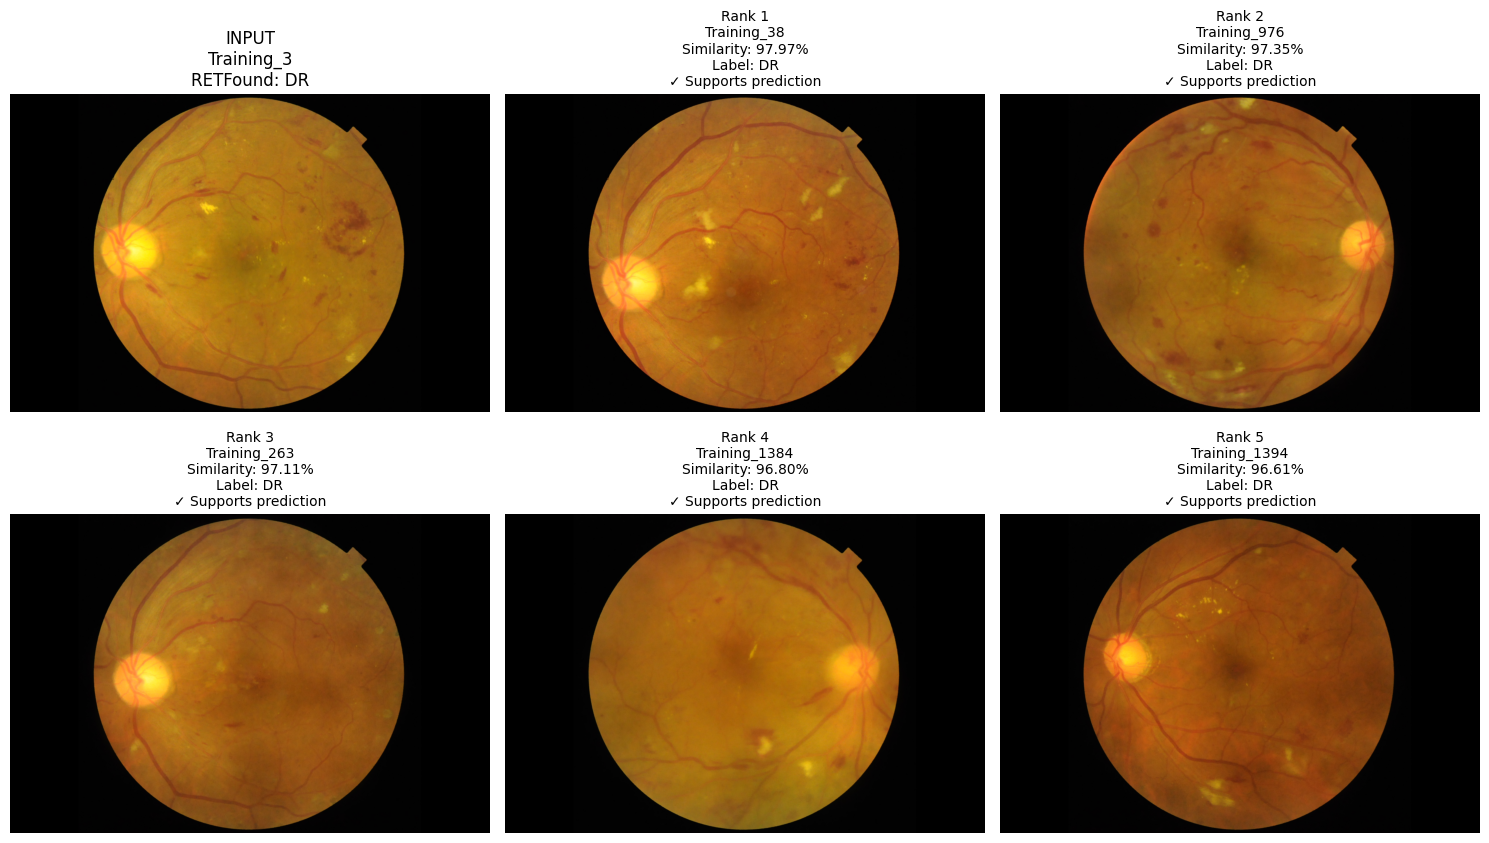

In [73]:
import matplotlib.pyplot as plt
from PIL import Image

# ============================================================
# Display Input + Top-5 Retrieved Fundus Images
# ============================================================

# Helper function: find image path from Image_Key
def get_image_path(image_key):
    return image_map[image_key]

# Input image
input_path = get_image_path(selected_image_key)

# Create figure
fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 9)
)

axes = axes.flatten()

# ------------------------------------------------------------
# Input image
# ------------------------------------------------------------

input_image = Image.open(input_path).convert("RGB")

axes[0].imshow(input_image)
axes[0].set_title(
    f"INPUT\n{selected_image_key}\n"
    f"RETFound: {', '.join(selected_predictions)}",
    fontsize=12
)
axes[0].axis("off")

# ------------------------------------------------------------
# Top-5 retrieved images
# ------------------------------------------------------------

for rank, (_, row) in enumerate(
    selected_retrievals.iterrows(),
    start=1
):

    retrieved_key = row["Retrieved_Image_Key"]
    retrieved_path = get_image_path(retrieved_key)

    retrieved_image = Image.open(
        retrieved_path
    ).convert("RGB")

    # Retrieved labels
    retrieved_labels = [
        disease
        for disease in class_names
        if row[disease] == 1
    ]

    labels_text = (
        ", ".join(retrieved_labels)
        if retrieved_labels
        else "None"
    )

    # Whether it supports RETFound prediction
    supporting_labels = [
        disease
        for disease in selected_predictions
        if row[disease] == 1
    ]

    if supporting_labels:
        support_text = "✓ Supports prediction"
    else:
        support_text = "✗ Does not support"

    axes[rank].imshow(retrieved_image)

    axes[rank].set_title(
        f"Rank {rank}\n"
        f"{retrieved_key}\n"
        f"Similarity: {row['Cosine_Similarity'] * 100:.2f}%\n"
        f"Label: {labels_text}\n"
        f"{support_text}",
        fontsize=10
    )

    axes[rank].axis("off")

plt.tight_layout()
plt.show()

In [74]:
# ============================================================
# Select Representative Test Cases
# ============================================================

# Add number of predicted labels to the summary
representative_df = doctor_summary_df.copy()

representative_df["Num_Predicted_Labels"] = (
    representative_df["RETFound_Prediction"]
    .apply(
        lambda x: 0 if x == "No label predicted"
        else len(x.split(", "))
    )
)

# ------------------------------------------------------------
# 1. Strong single-label case
# ------------------------------------------------------------

single_label_cases = representative_df[
    representative_df["Num_Predicted_Labels"] == 1
].copy()

strong_single = single_label_cases.sort_values(
    ["Evidence_Support_%", "Mean_Similarity_%"],
    ascending=False
).iloc[0]

# ------------------------------------------------------------
# 2. Strong multi-label case
# ------------------------------------------------------------

multi_label_cases = representative_df[
    representative_df["Num_Predicted_Labels"] >= 2
].copy()

if len(multi_label_cases) > 0:
    strong_multi = multi_label_cases.sort_values(
        ["Evidence_Support_%", "Mean_Similarity_%"],
        ascending=False
    ).iloc[0]
else:
    strong_multi = None

# ------------------------------------------------------------
# 3. Difficult case
# ------------------------------------------------------------

difficult_cases = representative_df[
    representative_df["Num_Predicted_Labels"] > 0
].copy()

difficult_case = difficult_cases.sort_values(
    ["Evidence_Support_%", "Mean_Similarity_%"],
    ascending=True
).iloc[0]

# ------------------------------------------------------------
# Display selected cases
# ------------------------------------------------------------

print("✅ Representative cases selected")
print("=" * 60)

print("\n1. STRONG SINGLE-LABEL CASE")
print("Image:", strong_single["Test_Image_Key"])
print("Prediction:", strong_single["RETFound_Prediction"])
print(
    f"Evidence support: "
    f"{strong_single['Evidence_Support_%']:.2f}%"
)
print(
    f"Mean similarity: "
    f"{strong_single['Mean_Similarity_%']:.2f}%"
)

if strong_multi is not None:
    print("\n2. STRONG MULTI-LABEL CASE")
    print("Image:", strong_multi["Test_Image_Key"])
    print("Prediction:", strong_multi["RETFound_Prediction"])
    print(
        f"Evidence support: "
        f"{strong_multi['Evidence_Support_%']:.2f}%"
    )
    print(
        f"Mean similarity: "
        f"{strong_multi['Mean_Similarity_%']:.2f}%"
    )
else:
    print("\n2. STRONG MULTI-LABEL CASE")
    print("No multi-label prediction found.")

print("\n3. DIFFICULT / WEAK-EVIDENCE CASE")
print("Image:", difficult_case["Test_Image_Key"])
print("Prediction:", difficult_case["RETFound_Prediction"])
print(
    f"Evidence support: "
    f"{difficult_case['Evidence_Support_%']:.2f}%"
)
print(
    f"Mean similarity: "
    f"{difficult_case['Mean_Similarity_%']:.2f}%"
)

✅ Representative cases selected

1. STRONG SINGLE-LABEL CASE
Image: Testing_562
Prediction: Is_Normal
Evidence support: 100.00%
Mean similarity: 99.25%

2. STRONG MULTI-LABEL CASE
Image: Training_1373
Prediction: DR, TSLN
Evidence support: 100.00%
Mean similarity: 94.43%

3. DIFFICULT / WEAK-EVIDENCE CASE
Image: Testing_46
Prediction: ARMD
Evidence support: 0.00%
Mean similarity: 78.27%



Displaying case: Testing_562


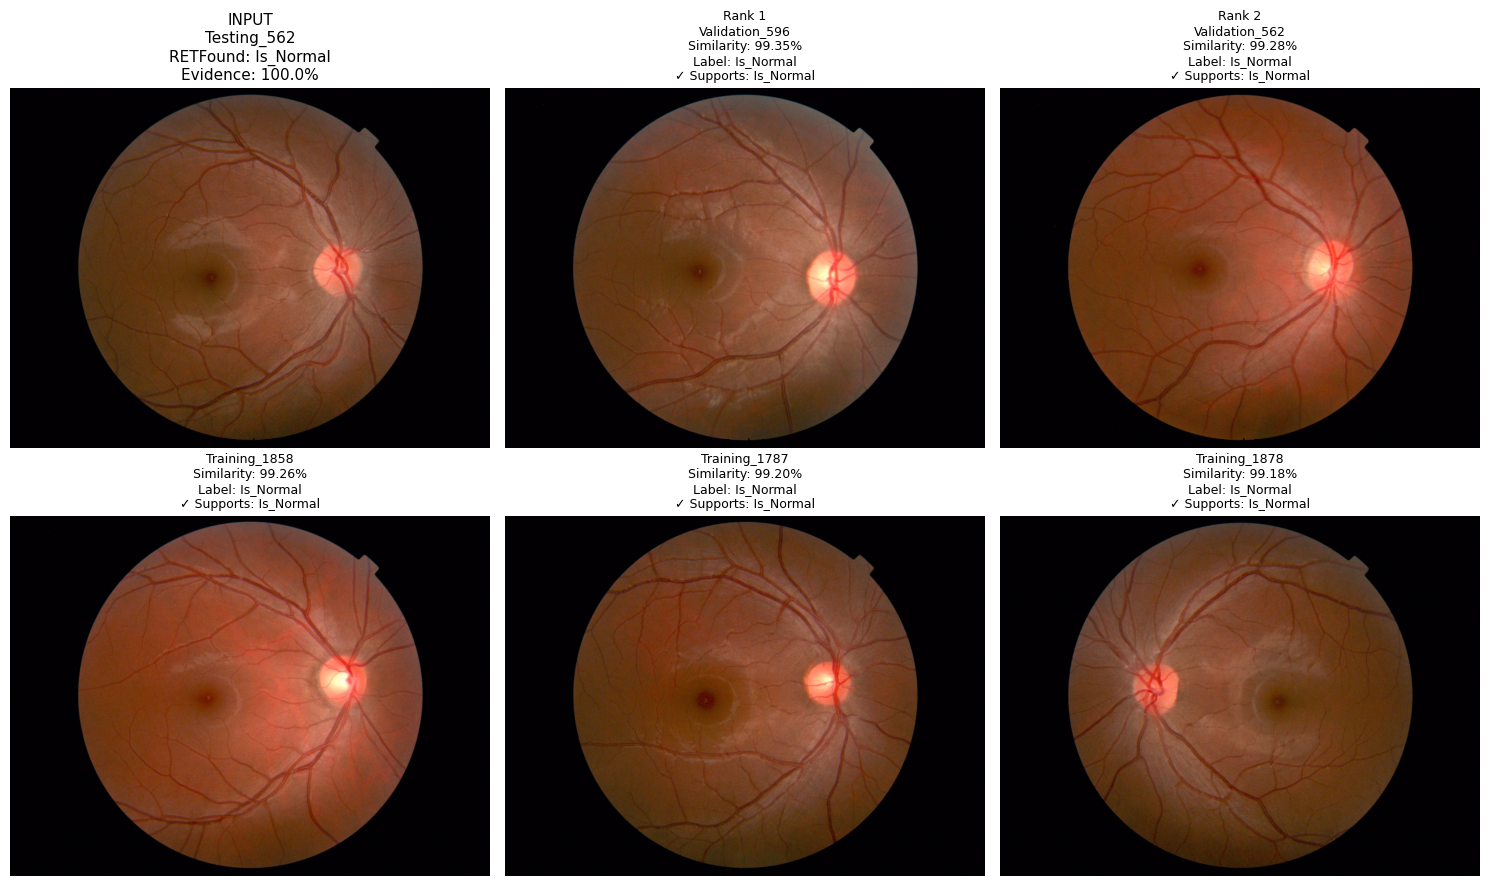


Displaying case: Training_1373


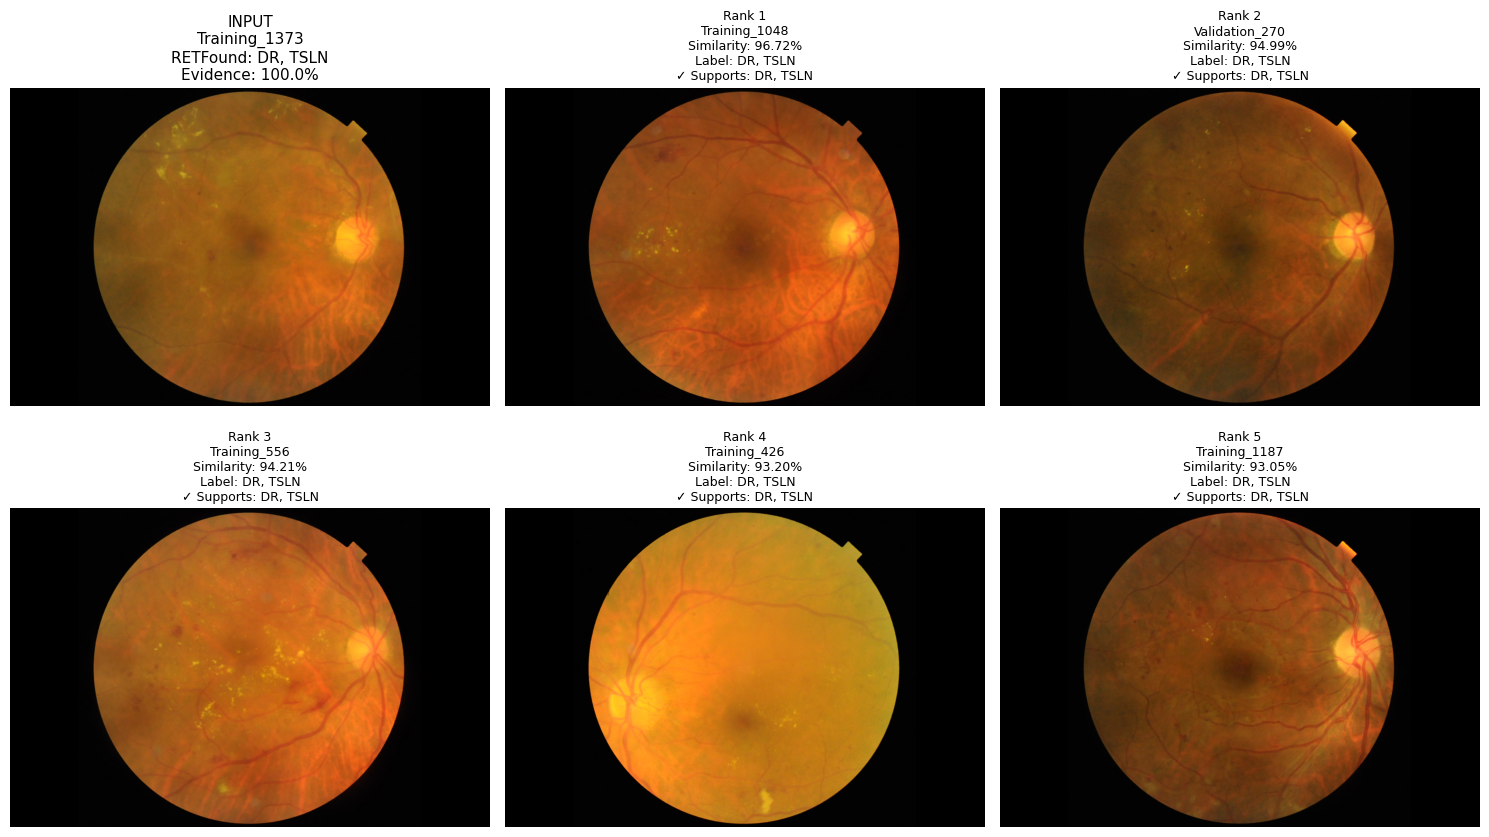


Displaying case: Testing_46


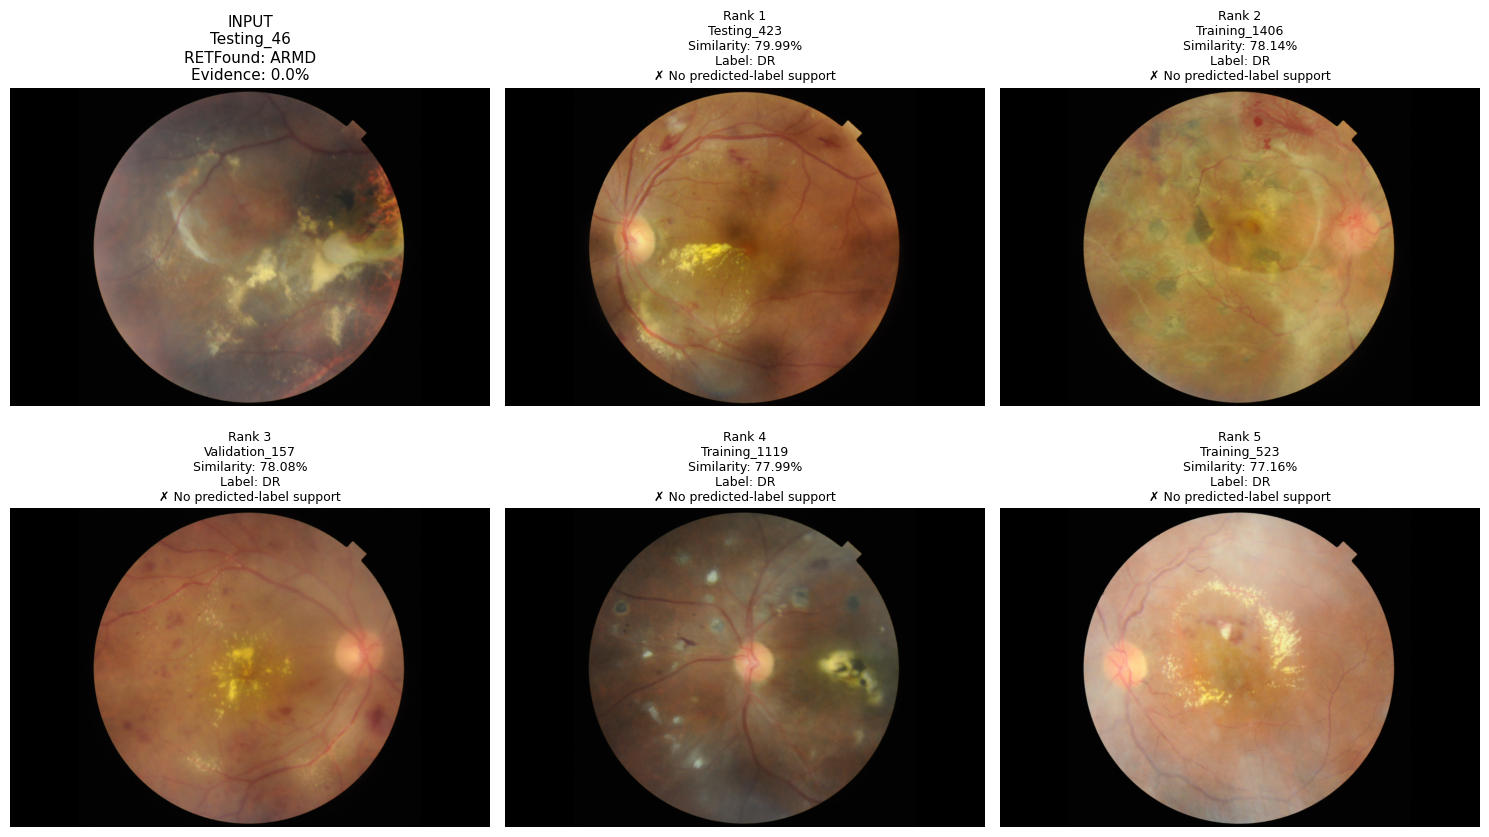

In [75]:
# ============================================================
# Visualize Representative Retrieval Cases
# ============================================================

representative_cases = [
    strong_single["Test_Image_Key"],
    strong_multi["Test_Image_Key"] if strong_multi is not None else None,
    difficult_case["Test_Image_Key"]
]

representative_cases = [
    x for x in representative_cases
    if x is not None
]


def display_retrieval_case(image_key):

    # Find test image
    test_idx = test_image_keys.index(image_key)

    # RETFound prediction
    predicted_indices = np.where(test_pred[test_idx] == 1)[0]

    predicted_labels = [
        class_names[j]
        for j in predicted_indices
    ]

    prediction_text = (
        ", ".join(predicted_labels)
        if predicted_labels
        else "No label predicted"
    )

    # Retrieval results
    retrieved_group = retrieval_with_labels[
        retrieval_with_labels["Test_Image_Key"] == image_key
    ].sort_values("Rank")

    # Overall evidence support
    if len(predicted_indices) > 0:
        support_values = [
            test_retrieval_evidence[test_idx, j]
            for j in predicted_indices
        ]
        evidence_support = np.mean(support_values) * 100
    else:
        evidence_support = 0.0

    # --------------------------------------------------------
    # Create figure
    # --------------------------------------------------------

    fig, axes = plt.subplots(
        2, 3,
        figsize=(15, 9)
    )

    axes = axes.flatten()

    # --------------------------------------------------------
    # Input image
    # --------------------------------------------------------

    input_path = image_map[image_key]
    input_image = Image.open(input_path).convert("RGB")

    axes[0].imshow(input_image)

    axes[0].set_title(
        f"INPUT\n"
        f"{image_key}\n"
        f"RETFound: {prediction_text}\n"
        f"Evidence: {evidence_support:.1f}%",
        fontsize=11
    )

    axes[0].axis("off")

    # --------------------------------------------------------
    # Top-5 retrieved images
    # --------------------------------------------------------

    for rank, (_, row) in enumerate(
        retrieved_group.iterrows(),
        start=1
    ):

        retrieved_key = row["Retrieved_Image_Key"]

        retrieved_path = image_map[retrieved_key]

        retrieved_image = Image.open(
            retrieved_path
        ).convert("RGB")

        # Known labels
        retrieved_labels = [
            disease
            for disease in class_names
            if row[disease] == 1
        ]

        labels_text = (
            ", ".join(retrieved_labels)
            if retrieved_labels
            else "None"
        )

        # Labels that support RETFound prediction
        supporting_labels = [
            disease
            for disease in predicted_labels
            if row[disease] == 1
        ]

        if supporting_labels:
            support_text = (
                "✓ Supports: "
                + ", ".join(supporting_labels)
            )
        else:
            support_text = "✗ No predicted-label support"

        axes[rank].imshow(retrieved_image)

        axes[rank].set_title(
            f"Rank {rank}\n"
            f"{retrieved_key}\n"
            f"Similarity: "
            f"{row['Cosine_Similarity'] * 100:.2f}%\n"
            f"Label: {labels_text}\n"
            f"{support_text}",
            fontsize=9
        )

        axes[rank].axis("off")

    plt.tight_layout()
    plt.show()


# Display all representative cases
for case in representative_cases:

    print("\n" + "=" * 70)
    print(f"Displaying case: {case}")
    print("=" * 70)

    display_retrieval_case(case)

In [76]:
# ============================================================
# Select Another Strong Multi-Label Test Case
# ============================================================

# Multi-label cases excluding the already displayed case
another_multi = representative_df[
    (representative_df["Num_Predicted_Labels"] >= 2) &
    (representative_df["Test_Image_Key"] != "Training_1373")
].copy()

# Select the strongest remaining multi-label case
another_multi = another_multi.sort_values(
    ["Evidence_Support_%", "Mean_Similarity_%"],
    ascending=False
).iloc[0]

print("✅ Another multi-label case selected")
print("=" * 55)

print("Image:", another_multi["Test_Image_Key"])
print("RETFound prediction:", another_multi["RETFound_Prediction"])
print(
    f"Evidence support: "
    f"{another_multi['Evidence_Support_%']:.2f}%"
)
print(
    f"Mean similarity: "
    f"{another_multi['Mean_Similarity_%']:.2f}%"
)

✅ Another multi-label case selected
Image: Validation_167
RETFound prediction: TSLN, ARMD
Evidence support: 100.00%
Mean similarity: 94.03%


In [77]:
# ============================================================
# Select Multi-Label Case with 80–100% Evidence Support
# ============================================================

multi_label_80_100 = representative_df[
    (representative_df["Num_Predicted_Labels"] >= 2) &
    (representative_df["Evidence_Support_%"] >= 80.0) &
    (representative_df["Evidence_Support_%"] < 100.0)
].copy()

# Sort by evidence support, then similarity
multi_label_80_100 = multi_label_80_100.sort_values(
    ["Evidence_Support_%", "Mean_Similarity_%"],
    ascending=[False, False]
)

print("Number of suitable multi-label cases:",
      len(multi_label_80_100))

print("\nTop candidates:")
print(
    multi_label_80_100[
        [
            "Test_Image_Key",
            "RETFound_Prediction",
            "Evidence_Support_%",
            "Mean_Similarity_%"
        ]
    ].head(15).to_string(index=False)
)

Number of suitable multi-label cases: 17

Top candidates:
Test_Image_Key RETFound_Prediction  Evidence_Support_%  Mean_Similarity_%
Validation_483       MH, ODC, TSLN          100.000000          89.711864
   Training_24            MH, TSLN          100.000000          81.864200
 Training_1431          TSLN, BRVO           90.410799          90.094087
   Testing_367            TSLN, DN           90.278878          75.205314
Validation_256             MH, MYA           90.015445          74.105434
Validation_109            MH, TSLN           90.011333          86.168380
  Training_937             MH, ODC           89.938404          86.117676
  Training_843            MH, TSLN           89.920624          74.733846
  Training_398        MH, ODC, MYA           87.354004          73.445626
Validation_343       MH, ODC, TSLN           86.835067          82.681565
Validation_535       MH, ODC, TSLN           80.614386          74.989660
  Training_653           ODC, TSLN           80.331120

CASE: Training_1431

RETFound Prediction:
TSLN, BRVO

Label-wise Retrieval Support:
  TSLN: 4/5 cases (80.82% weighted support)
  BRVO: 5/5 cases (100.00% weighted support)


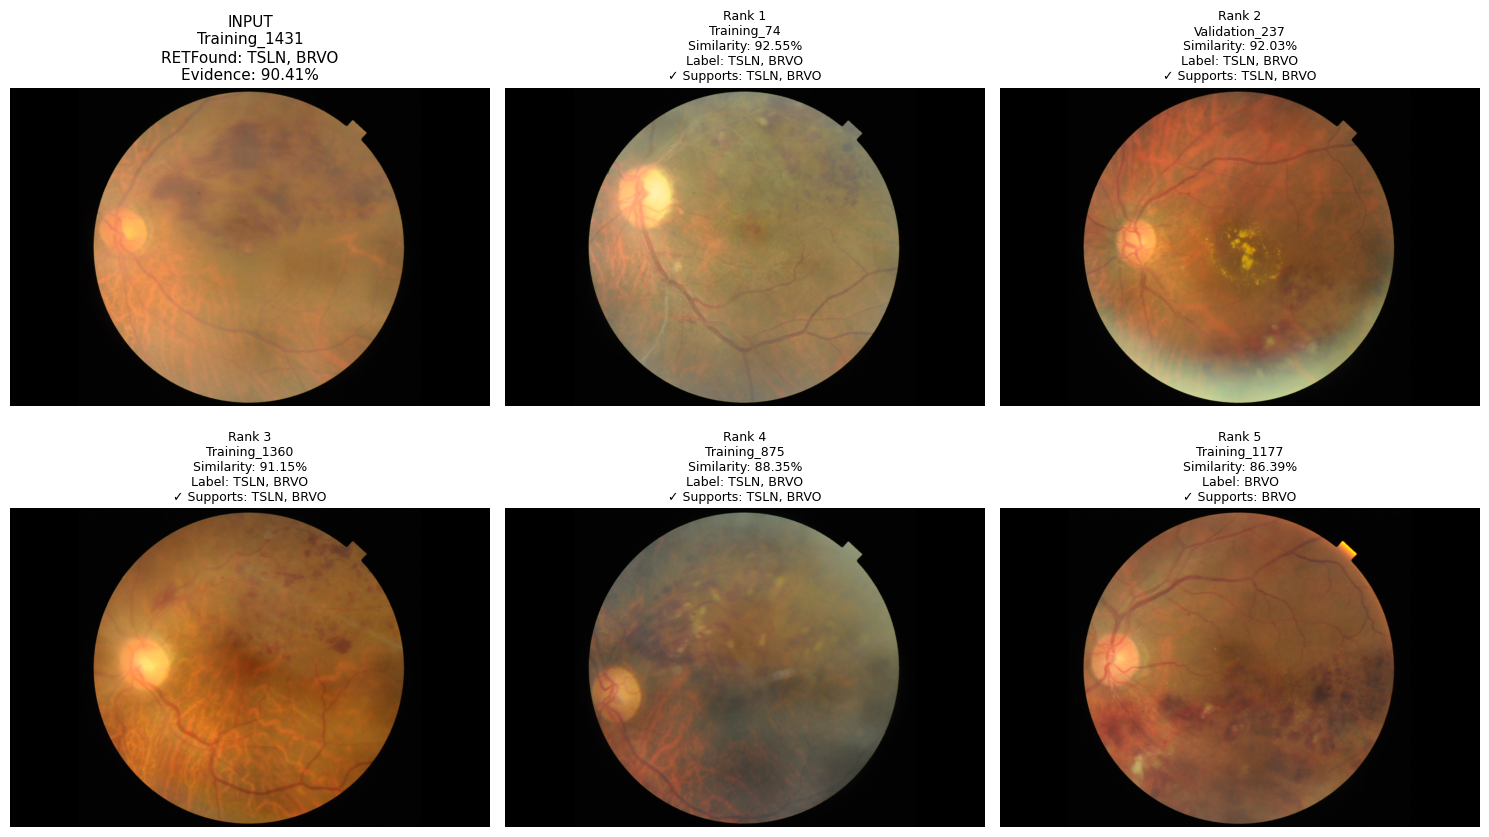

In [78]:
# ============================================================
# Visualize Selected Multi-Label Case
# ============================================================

selected_multi_key = "Training_1431"

# Find test image index
test_idx = test_image_keys.index(selected_multi_key)

# RETFound predicted labels
predicted_indices = np.where(test_pred[test_idx] == 1)[0]

selected_predictions = [
    class_names[j]
    for j in predicted_indices
]

prediction_text = ", ".join(selected_predictions)

# Get Top-5 retrieved cases
selected_retrievals = retrieval_with_labels[
    retrieval_with_labels["Test_Image_Key"] == selected_multi_key
].sort_values("Rank")

# Calculate label-wise support
print("=" * 70)
print(f"CASE: {selected_multi_key}")
print("=" * 70)

print("\nRETFound Prediction:")
print(prediction_text)

print("\nLabel-wise Retrieval Support:")

for j in predicted_indices:

    disease = class_names[j]

    support_score = test_retrieval_evidence[
        test_idx, j
    ]

    supporting_count = int(
        selected_retrievals[disease].sum()
    )

    print(
        f"  {disease}: "
        f"{supporting_count}/5 cases "
        f"({support_score * 100:.2f}% weighted support)"
    )

# ------------------------------------------------------------
# Display images
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 9)
)

axes = axes.flatten()

# Input image
input_image = Image.open(
    image_map[selected_multi_key]
).convert("RGB")

axes[0].imshow(input_image)

axes[0].set_title(
    f"INPUT\n"
    f"{selected_multi_key}\n"
    f"RETFound: {prediction_text}\n"
    f"Evidence: 90.41%",
    fontsize=11
)

axes[0].axis("off")

# Top-5 retrieved images
for rank, (_, row) in enumerate(
    selected_retrievals.iterrows(),
    start=1
):

    retrieved_key = row["Retrieved_Image_Key"]

    retrieved_image = Image.open(
        image_map[retrieved_key]
    ).convert("RGB")

    # Known labels of retrieved case
    retrieved_labels = [
        disease
        for disease in class_names
        if row[disease] == 1
    ]

    labels_text = (
        ", ".join(retrieved_labels)
        if retrieved_labels
        else "None"
    )

    # Which predicted labels are supported
    supporting_labels = [
        disease
        for disease in selected_predictions
        if row[disease] == 1
    ]

    if supporting_labels:
        support_text = (
            "✓ Supports: "
            + ", ".join(supporting_labels)
        )
    else:
        support_text = "✗ No predicted-label support"

    axes[rank].imshow(retrieved_image)

    axes[rank].set_title(
        f"Rank {rank}\n"
        f"{retrieved_key}\n"
        f"Similarity: "
        f"{row['Cosine_Similarity'] * 100:.2f}%\n"
        f"Label: {labels_text}\n"
        f"{support_text}",
        fontsize=9
    )

    axes[rank].axis("off")

plt.tight_layout()
plt.show()

In [79]:
# ============================================================
# Save Final Classification + Retrieval Results
# ============================================================

import os
import json

RESULTS_DIR = "/kaggle/working/PROJECT_PHASE_1/results"
os.makedirs(RESULTS_DIR, exist_ok=True)

# ------------------------------------------------------------
# 1. Final test classification metrics
# ------------------------------------------------------------

final_test_metrics = {
    "Macro_F1": float(baseline_macro_f1),
    "Micro_F1": float(baseline_micro_f1),
    "Macro_Precision": float(baseline_macro_precision),
    "Macro_Recall": float(baseline_macro_recall),
    "Macro_AUC": float(baseline_macro_auc),
    "Exact_Match": float(baseline_exact_match)
}

with open(
    os.path.join(RESULTS_DIR, "final_test_classification_metrics.json"),
    "w"
) as f:
    json.dump(final_test_metrics, f, indent=4)


# ------------------------------------------------------------
# 2. Overall retrieval evidence metrics
# ------------------------------------------------------------

final_retrieval_metrics = {
    "Test_Images": int(len(test_image_keys)),
    "Total_Predicted_Labels": int(test_predicted_label_count),
    "Mean_Retrieval_Support": float(test_mean_support),
    "Mean_Retrieval_Support_Percentage": float(
        test_mean_support * 100
    ),
    "Predictions_With_At_Least_60_Percent_Support": float(
        test_strong_support_rate * 100
    )
}

with open(
    os.path.join(RESULTS_DIR, "final_retrieval_evidence_metrics.json"),
    "w"
) as f:
    json.dump(final_retrieval_metrics, f, indent=4)


# ------------------------------------------------------------
# 3. Per-class retrieval support
# ------------------------------------------------------------

per_class_support_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "per_class_retrieval_support.csv"
    ),
    index=False
)


# ------------------------------------------------------------
# 4. Label-wise retrieval evidence
# ------------------------------------------------------------

labelwise_evidence_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "labelwise_retrieval_evidence.csv"
    ),
    index=False
)


# ------------------------------------------------------------
# 5. Doctor-facing summary
# ------------------------------------------------------------

doctor_summary_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "doctor_facing_retrieval_summary.csv"
    ),
    index=False
)


# ------------------------------------------------------------
# 6. Complete Top-5 retrieval table
# ------------------------------------------------------------

retrieval_with_labels.to_csv(
    os.path.join(
        RESULTS_DIR,
        "test_top5_retrieval_with_labels.csv"
    ),
    index=False
)


# ------------------------------------------------------------
# 7. Complete doctor-facing evidence table
# ------------------------------------------------------------

doctor_evidence_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "doctor_facing_retrieval_evidence.csv"
    ),
    index=False
)


# ------------------------------------------------------------
# 8. Save thresholds used for final test evaluation
# ------------------------------------------------------------

threshold_dict = {
    disease: float(threshold)
    for disease, threshold in zip(
        class_names,
        thresholds
    )
}

with open(
    os.path.join(
        RESULTS_DIR,
        "final_classification_thresholds.json"
    ),
    "w"
) as f:
    json.dump(threshold_dict, f, indent=4)


# ------------------------------------------------------------
# Verify saved files
# ------------------------------------------------------------

print("✅ Final results saved successfully")
print("\nResults directory:")
print(RESULTS_DIR)

print("\nSaved files:")

for filename in sorted(os.listdir(RESULTS_DIR)):
    filepath = os.path.join(RESULTS_DIR, filename)

    if os.path.isfile(filepath):
        size_kb = os.path.getsize(filepath) / 1024

        print(
            f"  ✓ {filename} "
            f"({size_kb:.1f} KB)"
        )

✅ Final results saved successfully

Results directory:
/kaggle/working/PROJECT_PHASE_1/results

Saved files:
  ✓ doctor_facing_retrieval_evidence.csv (154.4 KB)
  ✓ doctor_facing_retrieval_summary.csv (23.2 KB)
  ✓ final_classification_thresholds.json (0.2 KB)
  ✓ final_retrieval_evidence_metrics.json (0.2 KB)
  ✓ final_test_classification_metrics.json (0.2 KB)
  ✓ labelwise_retrieval_evidence.csv (19.7 KB)
  ✓ optimal_thresholds.json (0.3 KB)
  ✓ per_class_retrieval_support.csv (0.4 KB)
  ✓ per_class_test_metrics.csv (0.8 KB)
  ✓ test_metrics.json (0.3 KB)
  ✓ test_top5_retrieval_with_labels.csv (133.2 KB)


In [80]:
# ============================================================
# Upload PROJECT_PHASE_1 results as a Kaggle Dataset
# ============================================================

import os
import json
import shutil

RESULTS_SOURCE = "/kaggle/working/PROJECT_PHASE_1/results"
UPLOAD_DIR = "/kaggle/working/PROJECT_PHASE_1_FINAL_RESULTS"

os.makedirs(UPLOAD_DIR, exist_ok=True)

# Copy all result files
for filename in os.listdir(RESULTS_SOURCE):
    source = os.path.join(RESULTS_SOURCE, filename)

    if os.path.isfile(source):
        shutil.copy2(
            source,
            os.path.join(UPLOAD_DIR, filename)
        )

# Kaggle dataset metadata
metadata = {
    "title": "PROJECT PHASE 1 - RETFound Final Results",
    "id": "rithika2006/project-phase-1-retfound-results",
    "licenses": [
        {
            "name": "CC0-1.0"
        }
    ],
    "description": (
        "Final classification and retrieval evidence results "
        "for PROJECT PHASE 1 using RETFound and FAISS."
    )
}

with open(
    os.path.join(UPLOAD_DIR, "dataset-metadata.json"),
    "w"
) as f:
    json.dump(metadata, f, indent=4)

print("✅ Results prepared for Kaggle Dataset upload")
print("Upload directory:", UPLOAD_DIR)
print("\nFiles:")

for filename in sorted(os.listdir(UPLOAD_DIR)):
    print("  ✓", filename)

✅ Results prepared for Kaggle Dataset upload
Upload directory: /kaggle/working/PROJECT_PHASE_1_FINAL_RESULTS

Files:
  ✓ dataset-metadata.json
  ✓ doctor_facing_retrieval_evidence.csv
  ✓ doctor_facing_retrieval_summary.csv
  ✓ final_classification_thresholds.json
  ✓ final_retrieval_evidence_metrics.json
  ✓ final_test_classification_metrics.json
  ✓ labelwise_retrieval_evidence.csv
  ✓ optimal_thresholds.json
  ✓ per_class_retrieval_support.csv
  ✓ per_class_test_metrics.csv
  ✓ test_metrics.json
  ✓ test_top5_retrieval_with_labels.csv


In [81]:
# Upload final results to Kaggle as a private dataset

!kaggle datasets create \
    -p /kaggle/working/PROJECT_PHASE_1_FINAL_RESULTS \
    -r zip

Starting upload for file per_class_test_metrics.csv
100%|██████████████████████████████████████████| 870/870 [00:00<00:00, 3.32kB/s]
Upload successful: per_class_test_metrics.csv (870B)
Starting upload for file final_test_classification_metrics.json
100%|████████████████████████████████████████████| 233/233 [00:00<00:00, 882B/s]
Upload successful: final_test_classification_metrics.json (233B)
Starting upload for file per_class_retrieval_support.csv
100%|██████████████████████████████████████████| 426/426 [00:00<00:00, 1.59kB/s]
Upload successful: per_class_retrieval_support.csv (426B)
Starting upload for file test_top5_retrieval_with_labels.csv
100%|█████████████████████████████████████████| 133k/133k [00:00<00:00, 493kB/s]
Upload successful: test_top5_retrieval_with_labels.csv (133KB)
Starting upload for file test_metrics.json
100%|██████████████████████████████████████████| 315/315 [00:00<00:00, 1.21kB/s]
Upload successful: test_metrics.json (315B)
Starting upload for file doctor_fac

In [82]:
!kaggle datasets files rithika2006/project-phase-1-retfound-results

name                                      size  creationDate                
--------------------------------------  ------  --------------------------  
doctor_facing_retrieval_evidence.csv    158094  2026-09-03 10:30:06.421000  
doctor_facing_retrieval_summary.csv      23772  2026-09-03 10:30:06.403000  
final_classification_thresholds.json       175  2026-09-03 10:30:06.187000  
final_retrieval_evidence_metrics.json      242  2026-09-03 10:30:06.158000  
final_test_classification_metrics.json     233  2026-09-03 10:30:06.158000  
labelwise_retrieval_evidence.csv         20132  2026-09-03 10:30:06.379000  
optimal_thresholds.json                    263  2026-09-03 10:30:06.180000  
per_class_retrieval_support.csv            426  2026-09-03 10:30:06.410000  
per_class_test_metrics.csv                 870  2026-09-03 10:30:06.434000  
test_metrics.json                          315  2026-09-03 10:30:06.172000  
test_top5_retrieval_with_labels.csv     136402  2026-09-03 10:30:06.416000  

In [83]:
# ============================================================
# Check why Training_46 has no predicted label
# ============================================================

check_key = "Training_46"

idx = test_image_keys.index(check_key)

print("Image:", check_key)
print("\nRETFound probabilities vs thresholds:\n")

for j, disease in enumerate(class_names):

    probability = y_test_prob[idx, j]
    threshold = thresholds[j]
    predicted = test_pred[idx, j]

    print(
        f"{disease:12s} "
        f"Probability: {probability:.4f}  "
        f"Threshold: {threshold:.2f}  "
        f"Prediction: {predicted}"
    )

Image: Training_46

RETFound probabilities vs thresholds:

DR           Probability: 0.0002  Threshold: 0.55  Prediction: 0
MH           Probability: 0.3532  Threshold: 0.75  Prediction: 0
ODC          Probability: 0.0019  Threshold: 0.15  Prediction: 0
TSLN         Probability: 0.0003  Threshold: 0.75  Prediction: 0
DN           Probability: 0.0097  Threshold: 0.30  Prediction: 0
ARMD         Probability: 0.0002  Threshold: 0.15  Prediction: 0
MYA          Probability: 0.0004  Threshold: 0.25  Prediction: 0
BRVO         Probability: 0.0005  Threshold: 0.80  Prediction: 0
ODP          Probability: 0.0001  Threshold: 0.35  Prediction: 0
Is_Normal    Probability: 0.7890  Threshold: 0.90  Prediction: 0


In [84]:
# ============================================================
# Check how many test images have no predicted labels
# ============================================================

no_prediction_mask = (
    test_pred.sum(axis=1) == 0
)

num_no_prediction = int(
    no_prediction_mask.sum()
)

total_test_images = len(test_pred)

print("Test images with no predicted label:",
      num_no_prediction)

print(
    f"Percentage with no predicted label: "
    f"{num_no_prediction / total_test_images * 100:.2f}%"
)

print("\nTest images with at least one prediction:",
      total_test_images - num_no_prediction)

print(
    f"Percentage with at least one prediction: "
    f"{(total_test_images - num_no_prediction) / total_test_images * 100:.2f}%"
)

# Show the no-prediction cases
no_prediction_keys = [
    test_image_keys[i]
    for i in np.where(no_prediction_mask)[0]
]

print("\nFirst 20 no-prediction images:")

for key in no_prediction_keys[:20]:
    print(" ", key)

Test images with no predicted label: 13
Percentage with no predicted label: 3.23%

Test images with at least one prediction: 389
Percentage with at least one prediction: 96.77%

First 20 no-prediction images:
  Training_46
  Training_135
  Training_1130
  Training_1320
  Training_1413
  Training_1526
  Training_1716
  Validation_83
  Validation_203
  Validation_434
  Validation_464
  Testing_172
  Testing_483


In [85]:
# ============================================================
# Diagnostic: Test Images With No Predicted Labels
# ============================================================

no_prediction_indices = np.where(
    test_pred.sum(axis=1) == 0
)[0]

no_prediction_rows = []

for i in no_prediction_indices:

    # Highest probability class
    max_idx = np.argmax(y_test_prob[i])
    max_probability = y_test_prob[i, max_idx]
    max_class = class_names[max_idx]

    # Ground-truth labels
    true_indices = np.where(y_test_true[i] == 1)[0]

    true_labels = [
        class_names[j]
        for j in true_indices
    ]

    no_prediction_rows.append({
        "Image_Key": test_image_keys[i],
        "Highest_Probability_Class": max_class,
        "Highest_Probability": max_probability,
        "Ground_Truth": ", ".join(true_labels)
    })

no_prediction_df = pd.DataFrame(
    no_prediction_rows
)

print("✅ No-prediction cases analyzed")
print("Number of cases:", len(no_prediction_df))

print(
    no_prediction_df.to_string(
        index=False,
        formatters={
            "Highest_Probability":
                lambda x: f"{x:.4f}"
        }
    )
)

✅ No-prediction cases analyzed
Number of cases: 13
     Image_Key Highest_Probability_Class Highest_Probability Ground_Truth
   Training_46                 Is_Normal              0.7890           MH
  Training_135                        DR              0.4770           DN
 Training_1130                       ODP              0.1681      DR, ODC
 Training_1320                 Is_Normal              0.7847           DN
 Training_1413                 Is_Normal              0.3991           DR
 Training_1526                 Is_Normal              0.6955    Is_Normal
 Training_1716                 Is_Normal              0.8839    Is_Normal
 Validation_83                 Is_Normal              0.7695           DN
Validation_203                 Is_Normal              0.6875           MH
Validation_434                        DN              0.2619           DN
Validation_464                 Is_Normal              0.7417    Is_Normal
   Testing_172                 Is_Normal              0.7120 

In [86]:
# ============================================================
# Top-5 Retrieval Label Agreement
# ============================================================

agreement_rows = []

for i, test_key in enumerate(test_image_keys):

    predicted_indices = np.where(test_pred[i] == 1)[0]

    # Skip images with no confident prediction
    if len(predicted_indices) == 0:
        continue

    retrieved_group = retrieval_with_labels[
        retrieval_with_labels["Test_Image_Key"] == test_key
    ].sort_values("Rank")

    for j in predicted_indices:

        disease = class_names[j]

        # Number of Top-5 retrieved cases with this label
        supporting_count = int(
            retrieved_group[disease].sum()
        )

        # At least one retrieved case supports the label
        has_support = supporting_count > 0

        agreement_rows.append({
            "Test_Image_Key": test_key,
            "Predicted_Label": disease,
            "Supporting_Cases": supporting_count,
            "Top5_Agreement": has_support
        })

top5_agreement_df = pd.DataFrame(agreement_rows)

# ------------------------------------------------------------
# Overall agreement
# ------------------------------------------------------------

overall_agreement = (
    top5_agreement_df["Top5_Agreement"].mean()
)

print("✅ Top-5 retrieval label agreement calculated")
print("=" * 55)

print(
    f"Predicted labels evaluated: "
    f"{len(top5_agreement_df)}"
)

print(
    f"Predicted labels with ≥1 supporting case: "
    f"{top5_agreement_df['Top5_Agreement'].sum()}"
)

print(
    f"Top-5 label agreement: "
    f"{overall_agreement * 100:.2f}%"
)

# ------------------------------------------------------------
# Per-class agreement
# ------------------------------------------------------------

per_class_agreement = (
    top5_agreement_df
    .groupby("Predicted_Label")
    .agg(
        Predicted_Count=("Predicted_Label", "size"),
        Mean_Supporting_Cases=("Supporting_Cases", "mean"),
        Top5_Agreement=("Top5_Agreement", "mean")
    )
    .reset_index()
)

per_class_agreement["Top5_Agreement"] *= 100

print("\nPer-class Top-5 agreement:")
print(
    per_class_agreement.to_string(
        index=False,
        formatters={
            "Mean_Supporting_Cases":
                lambda x: f"{x:.2f}",
            "Top5_Agreement":
                lambda x: f"{x:.2f}%"
        }
    )
)

✅ Top-5 retrieval label agreement calculated
Predicted labels evaluated: 525
Predicted labels with ≥1 supporting case: 488
Top-5 label agreement: 92.95%

Per-class Top-5 agreement:
Predicted_Label  Predicted_Count Mean_Supporting_Cases Top5_Agreement
           ARMD               28                  4.21         92.86%
           BRVO               10                  4.70        100.00%
             DN               37                  3.62         81.08%
             DR              100                  4.82         98.00%
      Is_Normal              105                  5.00        100.00%
             MH               79                  4.89        100.00%
            MYA               25                  4.12         88.00%
            ODC               79                  3.05         74.68%
            ODP                9                  1.89         66.67%
           TSLN               53                  4.74        100.00%


In [87]:
# ============================================================
# Save Top-5 Retrieval Agreement Results
# ============================================================

# Save detailed agreement table
top5_agreement_df.to_csv(
    os.path.join(
        RESULTS_DIR,
        "top5_retrieval_label_agreement.csv"
    ),
    index=False
)

# Save per-class agreement
per_class_agreement.to_csv(
    os.path.join(
        RESULTS_DIR,
        "per_class_top5_retrieval_agreement.csv"
    ),
    index=False
)

# Save overall metric
top5_agreement_metrics = {
    "Predicted_Labels_Evaluated": int(
        len(top5_agreement_df)
    ),
    "Predicted_Labels_With_At_Least_One_Supporting_Case": int(
        top5_agreement_df["Top5_Agreement"].sum()
    ),
    "Top5_Label_Agreement_Percentage": float(
        overall_agreement * 100
    )
}

with open(
    os.path.join(
        RESULTS_DIR,
        "top5_retrieval_agreement_metrics.json"
    ),
    "w"
) as f:
    json.dump(
        top5_agreement_metrics,
        f,
        indent=4
    )

print("✅ Top-5 retrieval agreement results saved")

print("\nSaved:")
print("  ✓ top5_retrieval_label_agreement.csv")
print("  ✓ per_class_top5_retrieval_agreement.csv")
print("  ✓ top5_retrieval_agreement_metrics.json")

✅ Top-5 retrieval agreement results saved

Saved:
  ✓ top5_retrieval_label_agreement.csv
  ✓ per_class_top5_retrieval_agreement.csv
  ✓ top5_retrieval_agreement_metrics.json


In [88]:
# ============================================================
# Update the Kaggle Results Dataset
# ============================================================

!kaggle datasets version \
    -p /kaggle/working/PROJECT_PHASE_1_FINAL_RESULTS \
    -m "Added Top-5 retrieval label agreement results" \
    -r zip

Starting upload for file per_class_test_metrics.csv
100%|██████████████████████████████████████████| 870/870 [00:00<00:00, 3.40kB/s]
Upload successful: per_class_test_metrics.csv (870B)
Starting upload for file final_test_classification_metrics.json
100%|████████████████████████████████████████████| 233/233 [00:00<00:00, 892B/s]
Upload successful: final_test_classification_metrics.json (233B)
Starting upload for file per_class_retrieval_support.csv
100%|██████████████████████████████████████████| 426/426 [00:00<00:00, 1.70kB/s]
Upload successful: per_class_retrieval_support.csv (426B)
Starting upload for file test_top5_retrieval_with_labels.csv
100%|█████████████████████████████████████████| 133k/133k [00:00<00:00, 546kB/s]
Upload successful: test_top5_retrieval_with_labels.csv (133KB)
Starting upload for file test_metrics.json
100%|██████████████████████████████████████████| 315/315 [00:00<00:00, 1.20kB/s]
Upload successful: test_metrics.json (315B)
Starting upload for file doctor_fac

In [89]:
!kaggle datasets files rithika2006/project-phase-1-retfound-results

name                                      size  creationDate                
--------------------------------------  ------  --------------------------  
doctor_facing_retrieval_evidence.csv    158094  2026-09-03 11:10:36.042000  
doctor_facing_retrieval_summary.csv      23772  2026-09-03 11:10:36.033000  
final_classification_thresholds.json       175  2026-09-03 11:10:35.618000  
final_retrieval_evidence_metrics.json      242  2026-09-03 11:10:35.762000  
final_test_classification_metrics.json     233  2026-09-03 11:10:35.827000  
labelwise_retrieval_evidence.csv         20132  2026-09-03 11:10:36.048000  
optimal_thresholds.json                    263  2026-09-03 11:10:35.895000  
per_class_retrieval_support.csv            426  2026-09-03 11:10:36.062000  
per_class_test_metrics.csv                 870  2026-09-03 11:10:36.125000  
test_metrics.json                          315  2026-09-03 11:10:35.875000  
test_top5_retrieval_with_labels.csv     136402  2026-09-03 11:10:36.051000  

In [91]:
# ============================================================
# FINAL PREDICTION WITH FALLBACK
# ============================================================

final_test_pred = test_pred.copy()

fallback_count = 0

for i in range(len(test_image_keys)):

    # Check whether at least one label crossed its optimized threshold
    predicted_indices = np.where(final_test_pred[i] == 1)[0]

    # If no label was predicted
    if len(predicted_indices) == 0:

        # Select the label with the highest RETFound probability
        best_label_idx = np.argmax(y_test_prob[i])

        # Assign that label as the prediction
        final_test_pred[i, best_label_idx] = 1

        fallback_count += 1

print("Fallback predictions applied:", fallback_count)
print("Total test images:", len(test_image_keys))

# Verify that every image now has at least one prediction
no_prediction_count = np.sum(final_test_pred.sum(axis=1) == 0)

print("Images with no prediction:", no_prediction_count)

Fallback predictions applied: 13
Total test images: 402
Images with no prediction: 0


In [93]:
# ============================================================
# CONVERT FINAL PREDICTIONS TO LABEL NAMES
# ============================================================

CLASS_NAMES = [
    'DR',
    'MH',
    'ODC',
    'TSLN',
    'DN',
    'ARMD',
    'MYA',
    'BRVO',
    'ODP',
    'Is_Normal'
]

final_prediction_labels = []

for i in range(len(test_image_keys)):

    predicted_indices = np.where(final_test_pred[i] == 1)[0]

    labels = [CLASS_NAMES[j] for j in predicted_indices]

    final_prediction_labels.append(", ".join(labels))

final_prediction_df = pd.DataFrame({
    "Test_Image_Key": test_image_keys,
    "RETFound_Prediction": final_prediction_labels
})

print(final_prediction_df.head(10))

  Test_Image_Key RETFound_Prediction
0     Training_3                  DR
1    Training_11            MH, ARMD
2    Training_14                  DN
3    Training_24            MH, TSLN
4    Training_27            DR, TSLN
5    Training_31                ARMD
6    Training_39                  DR
7    Training_45                  MH
8    Training_46           Is_Normal
9    Training_51              DR, DN


In [94]:
# ============================================================
# UPDATE DOCTOR-FACING RETRIEVAL OUTPUT
# ============================================================

doctor_evidence_final = doctor_evidence_df.copy()

# Replace the prediction column using our final predictions
doctor_evidence_final["RETFound_Prediction"] = (
    doctor_evidence_final["Test_Image_Key"]
    .map(
        final_prediction_df.set_index("Test_Image_Key")[
            "RETFound_Prediction"
        ]
    )
)

# Check the result
print(doctor_evidence_final[
    doctor_evidence_final["Test_Image_Key"] == "Training_46"
].head())

   Test_Image_Key RETFound_Prediction  Rank Retrieved_Image_Key  Similarity  \
40    Training_46           Is_Normal     1        Training_116    0.859620   
41    Training_46           Is_Normal     2         Training_81    0.856695   
42    Training_46           Is_Normal     3        Training_598    0.856590   
43    Training_46           Is_Normal     4        Training_728    0.849750   
44    Training_46           Is_Normal     5         Training_91    0.847926   

   Retrieved_Labels Supporting_Labels    Support_Status  
40        Is_Normal              None  Does not support  
41        Is_Normal              None  Does not support  
42        Is_Normal              None  Does not support  
43        Is_Normal              None  Does not support  
44        Is_Normal              None  Does not support  


In [95]:
# ============================================================
# APPLY FALLBACK TO ALL UNLABELLED PREDICTIONS
# ============================================================

# Start from the original doctor-facing dataframe
doctor_evidence_final = doctor_evidence_df.copy()

# Create mapping: Image Key -> Final Prediction
prediction_mapping = dict(
    zip(
        final_prediction_df["Test_Image_Key"],
        final_prediction_df["RETFound_Prediction"]
    )
)

# Apply final predictions to ALL test images
doctor_evidence_final["RETFound_Prediction"] = (
    doctor_evidence_final["Test_Image_Key"].map(prediction_mapping)
)

# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

print("Total test images:",
      doctor_evidence_final["Test_Image_Key"].nunique())

print("Total retrieval rows:",
      len(doctor_evidence_final))

print("\nMissing predictions:",
      doctor_evidence_final["RETFound_Prediction"].isna().sum())

print("\nPreviously unlabelled images now assigned:")
print(
    final_prediction_df[
        final_prediction_df["Test_Image_Key"].isin(
            test_image_keys[np.where(test_pred.sum(axis=1) == 0)[0]]
        )
    ].to_string(index=False)
)

Total test images: 402
Total retrieval rows: 2010

Missing predictions: 0

Previously unlabelled images now assigned:


TypeError: only integer scalar arrays can be converted to a scalar index

In [96]:
# ============================================================
# VERIFY ALL PREVIOUSLY UNLABELLED CASES
# ============================================================

previously_empty_indices = np.where(test_pred.sum(axis=1) == 0)[0]

previously_empty_keys = [
    test_image_keys[i] for i in previously_empty_indices
]

fallback_cases_df = final_prediction_df[
    final_prediction_df["Test_Image_Key"].isin(previously_empty_keys)
].copy()

print("Previously unlabelled images:", len(fallback_cases_df))
print()

print(fallback_cases_df.to_string(index=False))

Previously unlabelled images: 13

Test_Image_Key RETFound_Prediction
   Training_46           Is_Normal
  Training_135                  DR
 Training_1130                 ODP
 Training_1320           Is_Normal
 Training_1413           Is_Normal
 Training_1526           Is_Normal
 Training_1716           Is_Normal
 Validation_83           Is_Normal
Validation_203           Is_Normal
Validation_434                  DN
Validation_464           Is_Normal
   Testing_172           Is_Normal
   Testing_483           Is_Normal


In [97]:
# ============================================================
# REBUILD DOCTOR-FACING RETRIEVAL EVIDENCE
# USING FINAL PREDICTIONS
# ============================================================

doctor_evidence_final = doctor_evidence_df.copy()

# Map each test image to its final prediction
prediction_mapping = dict(
    zip(
        final_prediction_df["Test_Image_Key"],
        final_prediction_df["RETFound_Prediction"]
    )
)

# Replace predictions for ALL 402 test images
doctor_evidence_final["RETFound_Prediction"] = (
    doctor_evidence_final["Test_Image_Key"].map(prediction_mapping)
)

# ------------------------------------------------------------
# Recalculate supporting labels and support status
# ------------------------------------------------------------

def get_label_set(label_string):
    if pd.isna(label_string):
        return set()
    
    return set(
        label.strip()
        for label in str(label_string).split(",")
        if label.strip()
    )


doctor_evidence_final["Supporting_Labels"] = ""
doctor_evidence_final["Support_Status"] = ""

for idx, row in doctor_evidence_final.iterrows():

    predicted_labels = get_label_set(
        row["RETFound_Prediction"]
    )

    retrieved_labels = get_label_set(
        row["Retrieved_Labels"]
    )

    supporting_labels = predicted_labels.intersection(
        retrieved_labels
    )

    if len(supporting_labels) > 0:
        doctor_evidence_final.at[idx, "Supporting_Labels"] = (
            ", ".join(sorted(supporting_labels))
        )
        doctor_evidence_final.at[idx, "Support_Status"] = "Supports"
    else:
        doctor_evidence_final.at[idx, "Supporting_Labels"] = "None"
        doctor_evidence_final.at[idx, "Support_Status"] = "Does not support"


# ------------------------------------------------------------
# Verification
# ------------------------------------------------------------

print("Total test images:",
      doctor_evidence_final["Test_Image_Key"].nunique())

print("Total retrieval rows:",
      len(doctor_evidence_final))

print("Missing predictions:",
      doctor_evidence_final["RETFound_Prediction"].isna().sum())

print("\nPrediction examples:")
print(
    doctor_evidence_final[
        doctor_evidence_final["Test_Image_Key"] == "Training_46"
    ].head()
)

Total test images: 402
Total retrieval rows: 2010
Missing predictions: 0

Prediction examples:
   Test_Image_Key RETFound_Prediction  Rank Retrieved_Image_Key  Similarity  \
40    Training_46           Is_Normal     1        Training_116    0.859620   
41    Training_46           Is_Normal     2         Training_81    0.856695   
42    Training_46           Is_Normal     3        Training_598    0.856590   
43    Training_46           Is_Normal     4        Training_728    0.849750   
44    Training_46           Is_Normal     5         Training_91    0.847926   

   Retrieved_Labels Supporting_Labels Support_Status  
40        Is_Normal         Is_Normal       Supports  
41        Is_Normal         Is_Normal       Supports  
42        Is_Normal         Is_Normal       Supports  
43        Is_Normal         Is_Normal       Supports  
44        Is_Normal         Is_Normal       Supports  


In [98]:
# ============================================================
# SAVE CORRECTED DOCTOR-FACING RETRIEVAL RESULTS
# ============================================================

RESULTS_DIR = "/kaggle/working/PROJECT_PHASE_1/results"

# Save corrected doctor-facing evidence
doctor_evidence_final_path = os.path.join(
    RESULTS_DIR,
    "doctor_facing_retrieval_evidence.csv"
)

doctor_evidence_final.to_csv(
    doctor_evidence_final_path,
    index=False
)

print("Saved:")
print(doctor_evidence_final_path)

# Verify no missing predictions
print("\nMissing predictions:",
      doctor_evidence_final["RETFound_Prediction"].isna().sum())

# Verify no "No label predicted"
print(
    "No-label predictions:",
    (
        doctor_evidence_final["RETFound_Prediction"]
        == "No label predicted"
    ).sum()
)

Saved:
/kaggle/working/PROJECT_PHASE_1/results/doctor_facing_retrieval_evidence.csv

Missing predictions: 0
No-label predictions: 0


In [99]:
# ============================================================
# UPDATE KAGGLE RESULTS DATASET
# ============================================================

!kaggle datasets version \
    -p /kaggle/working/PROJECT_PHASE_1/results \
    -m "Updated doctor-facing predictions with fallback labels" \
    -r zip

Metadata file not found: dataset-metadata.json


In [100]:
!kaggle datasets files rithika2006/project-phase-1-retfound-results

name                                      size  creationDate                
--------------------------------------  ------  --------------------------  
doctor_facing_retrieval_evidence.csv    158094  2026-09-03 11:10:36.042000  
doctor_facing_retrieval_summary.csv      23772  2026-09-03 11:10:36.033000  
final_classification_thresholds.json       175  2026-09-03 11:10:35.618000  
final_retrieval_evidence_metrics.json      242  2026-09-03 11:10:35.762000  
final_test_classification_metrics.json     233  2026-09-03 11:10:35.827000  
labelwise_retrieval_evidence.csv         20132  2026-09-03 11:10:36.048000  
optimal_thresholds.json                    263  2026-09-03 11:10:35.895000  
per_class_retrieval_support.csv            426  2026-09-03 11:10:36.062000  
per_class_test_metrics.csv                 870  2026-09-03 11:10:36.125000  
test_metrics.json                          315  2026-09-03 11:10:35.875000  
test_top5_retrieval_with_labels.csv     136402  2026-09-03 11:10:36.051000  

In [101]:
# ============================================================
# CREATE KAGGLE DATASET METADATA
# ============================================================

import json
import os

RESULTS_DIR = "/kaggle/working/PROJECT_PHASE_1/results"

metadata = {
    "title": "PROJECT PHASE 1 - RETFound Results",
    "id": "rithika2006/project-phase-1-retfound-results",
    "licenses": [
        {
            "name": "CC0-1.0"
        }
    ],
    "description": "Final classification and retrieval results from the RETFound-based retinal disease diagnosis project."
}

metadata_path = os.path.join(
    RESULTS_DIR,
    "dataset-metadata.json"
)

with open(metadata_path, "w") as f:
    json.dump(metadata, f, indent=4)

print("Created:")
print(metadata_path)

print("\nFiles in results folder:")
print(os.listdir(RESULTS_DIR))

Created:
/kaggle/working/PROJECT_PHASE_1/results/dataset-metadata.json

Files in results folder:
['dataset-metadata.json', 'top5_retrieval_label_agreement.csv', 'per_class_test_metrics.csv', 'per_class_top5_retrieval_agreement.csv', 'final_test_classification_metrics.json', 'per_class_retrieval_support.csv', 'test_top5_retrieval_with_labels.csv', 'test_metrics.json', 'doctor_facing_retrieval_evidence.csv', 'optimal_thresholds.json', 'labelwise_retrieval_evidence.csv', 'doctor_facing_retrieval_summary.csv', 'final_retrieval_evidence_metrics.json', 'final_classification_thresholds.json', 'top5_retrieval_agreement_metrics.json']


In [102]:
!kaggle datasets version \
    -p /kaggle/working/PROJECT_PHASE_1/results \
    -m "Updated doctor-facing predictions with fallback labels" \
    -r zip

Starting upload for file top5_retrieval_label_agreement.csv
100%|██████████████████████████████████████| 13.2k/13.2k [00:00<00:00, 45.5kB/s]
Upload successful: top5_retrieval_label_agreement.csv (13KB)
Starting upload for file per_class_test_metrics.csv
100%|██████████████████████████████████████████| 870/870 [00:00<00:00, 3.29kB/s]
Upload successful: per_class_test_metrics.csv (870B)
Starting upload for file per_class_top5_retrieval_agreement.csv
100%|██████████████████████████████████████████| 380/380 [00:00<00:00, 1.22kB/s]
Upload successful: per_class_top5_retrieval_agreement.csv (380B)
Starting upload for file final_test_classification_metrics.json
100%|████████████████████████████████████████████| 233/233 [00:00<00:00, 920B/s]
Upload successful: final_test_classification_metrics.json (233B)
Starting upload for file per_class_retrieval_support.csv
100%|██████████████████████████████████████████| 426/426 [00:00<00:00, 1.62kB/s]
Upload successful: per_class_retrieval_support.csv (42

In [103]:
!kaggle datasets files rithika2006/project-phase-1-retfound-results

name                                      size  creationDate                
--------------------------------------  ------  --------------------------  
doctor_facing_retrieval_evidence.csv    157133  2026-09-03 12:04:36.272000  
doctor_facing_retrieval_summary.csv      23772  2026-09-03 12:04:36.241000  
final_classification_thresholds.json       175  2026-09-03 12:04:35.834000  
final_retrieval_evidence_metrics.json      242  2026-09-03 12:04:36.156000  
final_test_classification_metrics.json     233  2026-09-03 12:04:36.130000  
labelwise_retrieval_evidence.csv         20132  2026-09-03 12:04:36.152000  
optimal_thresholds.json                    263  2026-09-03 12:04:36.119000  
per_class_retrieval_support.csv            426  2026-09-03 12:04:36.237000  
per_class_test_metrics.csv                 870  2026-09-03 12:04:36.220000  
per_class_top5_retrieval_agreement.csv     380  2026-09-03 12:04:36.255000  
test_metrics.json                          315  2026-09-03 12:04:36.004000  

In [104]:
# ============================================================
# REMOVE Is_Normal WHEN A DISEASE IS ALSO PREDICTED
# ============================================================

DISEASE_LABELS = [
    'DR',
    'MH',
    'ODC',
    'TSLN',
    'DN',
    'ARMD',
    'MYA',
    'BRVO',
    'ODP'
]

NORMAL_LABEL = 'Is_Normal'

# Copy the current final predictions
final_prediction_clean = final_prediction_df.copy()

def enforce_normal_consistency(prediction):
    
    labels = [
        label.strip()
        for label in str(prediction).split(",")
        if label.strip()
    ]
    
    # Find disease predictions
    disease_predictions = [
        label for label in labels
        if label in DISEASE_LABELS
    ]
    
    # If any disease is predicted, remove Is_Normal
    if len(disease_predictions) > 0:
        return ", ".join(disease_predictions)
    
    # Otherwise keep the normal prediction
    return ", ".join(labels)


# Apply to all 402 images
final_prediction_clean["RETFound_Prediction"] = (
    final_prediction_clean["RETFound_Prediction"]
    .apply(enforce_normal_consistency)
)

print("Total test images:",
      len(final_prediction_clean))

print("\nEmpty predictions:",
      (
          final_prediction_clean["RETFound_Prediction"]
          .str.strip() == ""
      ).sum())

print("\nFirst 10 predictions:")
print(final_prediction_clean.head(10))

Total test images: 402

Empty predictions: 0

First 10 predictions:
  Test_Image_Key RETFound_Prediction
0     Training_3                  DR
1    Training_11            MH, ARMD
2    Training_14                  DN
3    Training_24            MH, TSLN
4    Training_27            DR, TSLN
5    Training_31                ARMD
6    Training_39                  DR
7    Training_45                  MH
8    Training_46           Is_Normal
9    Training_51              DR, DN


In [105]:
# ============================================================
# CHECK DN, Is_Normal / DISEASE + NORMAL CASES
# ============================================================

original_prediction_map = dict(
    zip(
        final_prediction_df["Test_Image_Key"],
        final_prediction_df["RETFound_Prediction"]
    )
)

clean_prediction_map = dict(
    zip(
        final_prediction_clean["Test_Image_Key"],
        final_prediction_clean["RETFound_Prediction"]
    )
)

changed_cases = []

for image_key in original_prediction_map:

    original = original_prediction_map[image_key]
    cleaned = clean_prediction_map[image_key]

    if original != cleaned:
        changed_cases.append({
            "Test_Image_Key": image_key,
            "Before": original,
            "After": cleaned
        })

changed_cases_df = pd.DataFrame(changed_cases)

print("Number of predictions corrected:",
      len(changed_cases_df))

print()

print(changed_cases_df.to_string(index=False))

Number of predictions corrected: 3

Test_Image_Key         Before After
  Training_651 ODC, Is_Normal   ODC
 Training_1404  DN, Is_Normal    DN
Validation_610 ODP, Is_Normal   ODP


In [106]:
# ============================================================
# UPDATE DOCTOR-FACING OUTPUT WITH CLEAN PREDICTIONS
# ============================================================

# Create mapping using the cleaned predictions
clean_prediction_mapping = dict(
    zip(
        final_prediction_clean["Test_Image_Key"],
        final_prediction_clean["RETFound_Prediction"]
    )
)

# Update predictions
doctor_evidence_final["RETFound_Prediction"] = (
    doctor_evidence_final["Test_Image_Key"]
    .map(clean_prediction_mapping)
)

# ------------------------------------------------------------
# Recalculate supporting labels and support status
# ------------------------------------------------------------

def get_label_set(label_string):
    if pd.isna(label_string):
        return set()

    return set(
        label.strip()
        for label in str(label_string).split(",")
        if label.strip()
    )


doctor_evidence_final["Supporting_Labels"] = ""
doctor_evidence_final["Support_Status"] = ""

for idx, row in doctor_evidence_final.iterrows():

    predicted_labels = get_label_set(
        row["RETFound_Prediction"]
    )

    retrieved_labels = get_label_set(
        row["Retrieved_Labels"]
    )

    supporting_labels = predicted_labels.intersection(
        retrieved_labels
    )

    if supporting_labels:
        doctor_evidence_final.at[idx, "Supporting_Labels"] = (
            ", ".join(sorted(supporting_labels))
        )
        doctor_evidence_final.at[idx, "Support_Status"] = "Supports"
    else:
        doctor_evidence_final.at[idx, "Supporting_Labels"] = "None"
        doctor_evidence_final.at[idx, "Support_Status"] = "Does not support"


# ------------------------------------------------------------
# FINAL VERIFICATION
# ------------------------------------------------------------

print("Total test images:",
      doctor_evidence_final["Test_Image_Key"].nunique())

print("Total retrieval rows:",
      len(doctor_evidence_final))

print("Missing predictions:",
      doctor_evidence_final["RETFound_Prediction"].isna().sum())

print("No-label predictions:",
      (
          doctor_evidence_final["RETFound_Prediction"]
          == "No label predicted"
      ).sum())

# Check the three corrected cases
print("\nCorrected cases:")
print(
    doctor_evidence_final[
        doctor_evidence_final["Test_Image_Key"].isin(
            ["Training_651", "Training_1404", "Validation_610"]
        )
    ][
        [
            "Test_Image_Key",
            "RETFound_Prediction",
            "Retrieved_Labels",
            "Supporting_Labels",
            "Support_Status"
        ]
    ].to_string(index=False)
)

Total test images: 402
Total retrieval rows: 2010
Missing predictions: 0
No-label predictions: 0

Corrected cases:
Test_Image_Key RETFound_Prediction Retrieved_Labels Supporting_Labels   Support_Status
  Training_651                 ODC        Is_Normal              None Does not support
  Training_651                 ODC        Is_Normal              None Does not support
  Training_651                 ODC        Is_Normal              None Does not support
  Training_651                 ODC        Is_Normal              None Does not support
  Training_651                 ODC        Is_Normal              None Does not support
 Training_1404                  DN        Is_Normal              None Does not support
 Training_1404                  DN        Is_Normal              None Does not support
 Training_1404                  DN        Is_Normal              None Does not support
 Training_1404                  DN        Is_Normal              None Does not support
 Training_1404 

In [107]:
# ============================================================
# SAVE UPDATED DOCTOR-FACING EVIDENCE + SUMMARY
# ============================================================

RESULTS_DIR = "/kaggle/working/PROJECT_PHASE_1/results"

# ------------------------------------------------------------
# 1. Save corrected detailed retrieval evidence
# ------------------------------------------------------------

evidence_path = os.path.join(
    RESULTS_DIR,
    "doctor_facing_retrieval_evidence.csv"
)

doctor_evidence_final.to_csv(
    evidence_path,
    index=False
)


# ------------------------------------------------------------
# 2. Rebuild doctor-facing summary
# ------------------------------------------------------------

summary_rows = []

for image_key, group in doctor_evidence_final.groupby(
    "Test_Image_Key",
    sort=False
):

    prediction = group["RETFound_Prediction"].iloc[0]

    # Number of retrieved cases supporting at least
    # one predicted label
    supporting_cases = (
        group["Support_Status"] == "Supports"
    ).sum()

    total_retrieved = len(group)

    evidence_support = (
        supporting_cases / total_retrieved * 100
        if total_retrieved > 0
        else 0
    )

    mean_similarity = group["Similarity"].mean() * 100

    # Evidence strength for doctor-facing display
    if evidence_support >= 80:
        evidence_strength = "Strong"
    elif evidence_support >= 60:
        evidence_strength = "Moderate"
    elif evidence_support > 0:
        evidence_strength = "Weak"
    else:
        evidence_strength = "No supporting evidence"

    summary_rows.append({
        "Test_Image_Key": image_key,
        "RETFound_Prediction": prediction,
        "Supporting_Cases": f"{supporting_cases}/{total_retrieved}",
        "Total_Retrieved": total_retrieved,
        "Evidence_Support_%": round(evidence_support, 2),
        "Mean_Similarity_%": round(mean_similarity, 2),
        "Evidence_Strength": evidence_strength
    })


doctor_summary_final = pd.DataFrame(summary_rows)


# ------------------------------------------------------------
# 3. Save summary
# ------------------------------------------------------------

summary_path = os.path.join(
    RESULTS_DIR,
    "doctor_facing_retrieval_summary.csv"
)

doctor_summary_final.to_csv(
    summary_path,
    index=False
)


# ------------------------------------------------------------
# 4. Final verification
# ------------------------------------------------------------

print("Evidence saved:")
print(evidence_path)

print("\nSummary saved:")
print(summary_path)

print("\nSummary shape:",
      doctor_summary_final.shape)

print("Unique test images:",
      doctor_summary_final["Test_Image_Key"].nunique())

print("\nMissing predictions:",
      doctor_summary_final["RETFound_Prediction"].isna().sum())

print("\nNo-label predictions:",
      (
          doctor_summary_final["RETFound_Prediction"]
          == "No label predicted"
      ).sum())

print("\nCorrected cases in summary:")
print(
    doctor_summary_final[
        doctor_summary_final["Test_Image_Key"].isin(
            [
                "Training_651",
                "Training_1404",
                "Validation_610"
            ]
        )
    ].to_string(index=False)
)

Evidence saved:
/kaggle/working/PROJECT_PHASE_1/results/doctor_facing_retrieval_evidence.csv

Summary saved:
/kaggle/working/PROJECT_PHASE_1/results/doctor_facing_retrieval_summary.csv

Summary shape: (402, 7)
Unique test images: 402

Missing predictions: 0

No-label predictions: 0

Corrected cases in summary:
Test_Image_Key RETFound_Prediction Supporting_Cases  Total_Retrieved  Evidence_Support_%  Mean_Similarity_%      Evidence_Strength
  Training_651                 ODC              0/5                5                 0.0              90.60 No supporting evidence
 Training_1404                  DN              0/5                5                 0.0              90.47 No supporting evidence
Validation_610                 ODP              0/5                5                 0.0              85.01 No supporting evidence


In [108]:
import os

RESULTS_DIR = "/kaggle/working/PROJECT_PHASE_1/results"

print("Required files:")
print("doctor_facing_retrieval_evidence.csv:",
      os.path.exists(os.path.join(
          RESULTS_DIR, "doctor_facing_retrieval_evidence.csv"
      )))

print("doctor_facing_retrieval_summary.csv:",
      os.path.exists(os.path.join(
          RESULTS_DIR, "doctor_facing_retrieval_summary.csv"
      )))

print("dataset-metadata.json:",
      os.path.exists(os.path.join(
          RESULTS_DIR, "dataset-metadata.json"
      )))

Required files:
doctor_facing_retrieval_evidence.csv: True
doctor_facing_retrieval_summary.csv: True
dataset-metadata.json: True


In [109]:
!kaggle datasets version \
    -p /kaggle/working/PROJECT_PHASE_1/results \
    -m "Final doctor-facing predictions and evidence update" \
    -r zip

Starting upload for file top5_retrieval_label_agreement.csv
100%|██████████████████████████████████████| 13.2k/13.2k [00:00<00:00, 53.9kB/s]
Upload successful: top5_retrieval_label_agreement.csv (13KB)
Starting upload for file per_class_test_metrics.csv
100%|██████████████████████████████████████████| 870/870 [00:00<00:00, 3.15kB/s]
Upload successful: per_class_test_metrics.csv (870B)
Starting upload for file per_class_top5_retrieval_agreement.csv
100%|██████████████████████████████████████████| 380/380 [00:00<00:00, 1.46kB/s]
Upload successful: per_class_top5_retrieval_agreement.csv (380B)
Starting upload for file final_test_classification_metrics.json
100%|████████████████████████████████████████████| 233/233 [00:00<00:00, 958B/s]
Upload successful: final_test_classification_metrics.json (233B)
Starting upload for file per_class_retrieval_support.csv
100%|██████████████████████████████████████████| 426/426 [00:00<00:00, 1.65kB/s]
Upload successful: per_class_retrieval_support.csv (42

In [110]:
!kaggle datasets files rithika2006/project-phase-1-retfound-results

name                                      size  creationDate                
--------------------------------------  ------  --------------------------  
doctor_facing_retrieval_evidence.csv    156983  2026-09-03 12:12:54.380000  
doctor_facing_retrieval_summary.csv      18660  2026-09-03 12:12:54.412000  
final_classification_thresholds.json       175  2026-09-03 12:12:54.057000  
final_retrieval_evidence_metrics.json      242  2026-09-03 12:12:54.080000  
final_test_classification_metrics.json     233  2026-09-03 12:12:54.216000  
labelwise_retrieval_evidence.csv         20132  2026-09-03 12:12:54.411000  
optimal_thresholds.json                    263  2026-09-03 12:12:54.252000  
per_class_retrieval_support.csv            426  2026-09-03 12:12:54.474000  
per_class_test_metrics.csv                 870  2026-09-03 12:12:54.464000  
per_class_top5_retrieval_agreement.csv     380  2026-09-03 12:12:54.477000  
test_metrics.json                          315  2026-09-03 12:12:54.342000  